# Prediksi Harga Cabai Rawit - ST-GCN
**Kabupaten Banyumas | Dinperindag 2023-2025**

# REVISI 2 — Ringkasan perubahan (11 Okt 2026)

Notebook ini adalah salinan dari versi REVISI dengan perbaikan berikut. **File & folder versi lama tidak disentuh** — semua hasil REVISI 2 disimpan di folder **`outputs_r2/`** dan **`model_r2/`**.

| No | Bagian | Perubahan | Alasan singkat |
|---|---|---|---|
| 1 | STEP 8.2 Normalisasi | `np.clip(..., 0, 1)` **dihapus** | Harga uji yang melebihi rentang data latih tidak lagi "dipotong", sehingga input model, target evaluasi, dan persistence memakai harga yang sama persis |
| 2 | STEP 10 Split | Split berdasarkan **tanggal target** + **jarak pengaman (gap) 29 sampel** di antara train–val dan val–test | Menghilangkan tumpang tindih target (kebocoran kecil) antara train↔val dan val↔test |
| 3 | STEP 12 Evaluasi | Harga aktual uji diambil langsung dari data harga (Rupiah asli); sel tambalan "harga asli" dihapus karena sudah tidak perlu | Lebih sederhana & pasti benar |
| 4 | Cek periode uji | Mencetak tanggal target uji + persentase data asli (bukan forward fill) | Bahan kalimat di paper |
| 5 | MAPE training vs testing | Ditambah kolom **gabungan** (rata-rata merah & hijau); label "tidak ada overfitting" diganti netral | Angka gabungan untuk paper; label lama menyesatkan |
| 6 | Kesimpulan distribution shift | Kalimat "bukan kegagalan model" diganti kesimpulan netral | Klaim lama tidak didukung data |
| 7 | STEP 13 (notebook utama) | Sel duplikat GRU-only dihapus; path file jarak diarahkan ke `outputs_jarak_r2` | Kebersihan & konsistensi |

Yang **tidak** diubah (sudah benar): seleksi pasar, forward/backward fill per pasar, korelasi & scaler hanya dari data latih, arsitektur ST-GCN REVISI (2 jalur + output 2 harga + residual ke harga terakhir), seed tetap (10, 1, 3, 42, 7), hyperparameter.

**Urutan menjalankan:** notebook **versi jarak REVISI 2** dulu (Restart & Run All), baru notebook **utama REVISI 2**.

### Pembaruan 20 Okt 2026
- Gambar yang dipakai di paper disamakan persis dengan paper (300 dpi, label bahasa Inggris, ukuran 1 kolom IEEE): **Fig. 1** tren harga (STEP 4.6), **Fig. 2** graf jaringan (STEP 7.3), **Fig. 3** heatmap korelasi gabungan (STEP 6.1), **Fig. 4** dua panel pola musiman + prediksi hari ke-30 (STEP 13.5).
- Semua gambar lain kini otomatis disimpan 300 dpi.
- **STEP 14** baru: MAPE hanya pada target asli (bukan hasil pengisian).
- **STEP 15** baru: menyimpan file untuk dashboard Streamlit ke `model_r2/`.


 ## STEP 1: Install & Import Library

In [419]:
import os

os.chdir(r'C:\prediksi-cabai-banyumas')

os.makedirs('data',    exist_ok=True)
os.makedirs('model_r2',   exist_ok=True)
os.makedirs('outputs_r2', exist_ok=True)

print(f'Working directory: {os.getcwd()}')

Working directory: C:\prediksi-cabai-banyumas


In [420]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from itertools import product
from math import radians, sin, cos, sqrt, atan2
from scipy import stats
from sklearn.preprocessing import MinMaxScaler
import pickle, holidays, warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi']       = 120
plt.rcParams['font.size']        = 10
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.grid']        = True
plt.rcParams['grid.alpha']       = 0.3
plt.rcParams['savefig.dpi']      = 300      # REVISI: semua gambar disimpan 300 dpi (saran Reviewer 1)

# REVISI: gaya gambar untuk PAPER (huruf terbaca saat dicetak 1 kolom IEEE, label bahasa Inggris)
INK, MUT = '#1f1f1d', '#6b6a64'
RED, GRN = '#d03b2f', '#1f8a4c'
C_BIRU, C_ORANYE = '#2a78d6', '#eb6834'
GAYA_PAPER = {'font.size': 7, 'axes.titlesize': 7.5, 'axes.labelsize': 7, 'xtick.labelsize': 6.5,
              'ytick.labelsize': 6.5, 'legend.fontsize': 6.5, 'axes.spines.top': False,
              'axes.spines.right': False, 'axes.edgecolor': MUT, 'axes.grid': False,
              'axes.titleweight': 'normal'}
GAYA_PAPER_BESAR = {'font.size': 12, 'axes.edgecolor': MUT, 'axes.labelcolor': INK, 'xtick.color': MUT,
                    'ytick.color': MUT, 'axes.spines.top': False, 'axes.spines.right': False,
                    'axes.grid': False, 'axes.titleweight': 'normal'}

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Library berhasil diimport.')
print(f'Device : {device}')
if device.type == 'cuda':
    print(f'GPU    : {torch.cuda.get_device_name(0)}')

Library berhasil diimport.
Device : cpu


## STEP 2: Upload & Load Data

In [421]:
FILE   = 'C:/prediksi-cabai-banyumas/data/dinperindag_2023-2025.xlsx'
df     = pd.read_excel(FILE, sheet_name='cabai_rawit')
master = pd.read_excel(FILE, sheet_name='master_pasar')
df['tanggal'] = pd.to_datetime(df['tanggal'])

print(f"Sheet cabai_rawit  : {len(df):,} baris, {df['id_pasar'].nunique()} pasar")
print(f"Sheet master_pasar : {len(master)} baris")
print(f"Periode            : {df['tanggal'].min().date()} s/d {df['tanggal'].max().date()}")
print(f"Jumlah hari        : {df['tanggal'].nunique():,}")

Sheet cabai_rawit  : 26,925 baris, 25 pasar
Sheet master_pasar : 25 baris
Periode            : 2023-01-09 s/d 2025-12-31
Jumlah hari        : 1,077


## STEP 3: Cek Data Awal

In [422]:
df.head(5)

,tanggal,id_pasar,nama_pasar,latitude,longitude,harga_rawit_merah,harga_rawit_hijau
0,2023-01-31,P01,TAMBAK,-7.612192,109.411235,40000.0,38000.0
1,2023-01-31,P02,WAGE,-7.426629,109.250388,50000.0,30000.0
2,2023-01-31,P03,BANYUMAS,-7.510783,109.296070,55000.0,40000.0
3,2023-01-31,P04,KEMUKUSAN,-7.360538,109.275277,47000.0,29000.0
4,2023-01-31,P05,PAHING,-7.409807,109.201967,50000.0,32000.0


In [423]:
print('INFO DATASET\n')
df.info()

INFO DATASET

<class 'pandas.DataFrame'>
RangeIndex: 26925 entries, 0 to 26924
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   tanggal            26925 non-null  datetime64[us]
 1   id_pasar           26925 non-null  str           
 2   nama_pasar         26925 non-null  str           
 3   latitude           26925 non-null  float64       
 4   longitude          26925 non-null  float64       
 5   harga_rawit_merah  16241 non-null  float64       
 6   harga_rawit_hijau  16207 non-null  float64       
dtypes: datetime64[us](1), float64(4), str(2)
memory usage: 1.7 MB


In [424]:
print('JUMLAH MISSING VALUES\n')
print('cabai_rawit:')
print(df.isna().sum())

print('\nmaster_pasar:')
print(master.isna().sum())

JUMLAH MISSING VALUES

cabai_rawit:
tanggal                  0
id_pasar                 0
nama_pasar               0
latitude                 0
longitude                0
harga_rawit_merah    10684
harga_rawit_hijau    10718
dtype: int64

master_pasar:
id_pasar      0
nama_pasar    0
latitude      0
longitude     0
dtype: int64


In [425]:
print('JUMLAH DUPLIKAT')
print(f"Duplikat (semua kolom)        : {df.duplicated().sum()}")
print(f"Duplikat (tanggal + id_pasar) : {df.duplicated(subset=['tanggal','id_pasar']).sum()}")

JUMLAH DUPLIKAT
Duplikat (semua kolom)        : 0
Duplikat (tanggal + id_pasar) : 0


In [426]:
# Cek ada tanggal yang tidak urut/loncat?

# Ambil tanggal unik lalu urutkan
tanggal_unik = sorted(df['tanggal'].unique())

# Ubah ke Series (satu kolom)
tgl = pd.Series(tanggal_unik)

# Hitung selisih antar tanggal
selisih = tgl.diff().dt.days

# Cari gap tanggal yang loncat (>1 hari)
loncat = pd.DataFrame({
    'tanggal_sebelumnya': tgl.shift(1),
    'tanggal_sekarang'  : tgl,
    'selisih_hari'      : selisih
})
loncat = loncat[loncat['selisih_hari'] > 1].reset_index(drop=True)
loncat.index += 1

print(f"Total gap tanggal : {len(loncat)}")
display(loncat)

Total gap tanggal : 8


,tanggal_sebelumnya,tanggal_sekarang,selisih_hari
1,2023-04-20,2023-04-25,5.0
2,2023-04-29,2023-05-01,2.0
3,2023-05-06,2023-05-08,2.0
4,2023-05-13,2023-05-15,2.0
5,2023-05-20,2023-05-22,2.0
6,2023-05-27,2023-05-29,2.0
7,2023-06-03,2023-06-05,2.0
8,2023-06-10,2023-06-12,2.0


## STEP 4: Data Cleaning

### 4.1 Lengkapi Semua Tanggal x Pasar
Model butuh data lengkap setiap hari untuk setiap pasar. Baris yang kosong akan diisi nanti dengan forward fill.

In [427]:
semua_tanggal = pd.date_range(start=df['tanggal'].min(), end=df['tanggal'].max(), freq='D')
semua_pasar   = df['id_pasar'].unique()

kombinasi = pd.DataFrame(
    list(product(semua_tanggal, semua_pasar)),
    columns=['tanggal','id_pasar']
)
df_lengkap = kombinasi.merge(
    df[['tanggal','id_pasar','harga_rawit_merah','harga_rawit_hijau']],
    on=['tanggal','id_pasar'], how='left'
)
df_lengkap = df_lengkap.merge(
    master[['id_pasar','nama_pasar','latitude','longitude']],
    on='id_pasar', how='left'
)
df_lengkap = df_lengkap.sort_values(['id_pasar','tanggal']).reset_index(drop=True)
print(f"Total : {len(df_lengkap):,} baris ({len(semua_tanggal)} hari x {len(semua_pasar)} pasar)")

Total : 27,200 baris (1088 hari x 25 pasar)


### 4.2 Tandai Data Asli (is_observed)
Kolom ini menandai mana baris yang **benar-benar ada datanya** dari lapangan (nilai = 1) dan mana yang akan **diisi otomatis** (nilai = 0). Harus dibuat SEBELUM forward fill.

In [428]:
df_lengkap['is_observed_merah'] = df_lengkap['harga_rawit_merah'].notna().astype(int)
df_lengkap['is_observed_hijau']  = df_lengkap['harga_rawit_hijau'].notna().astype(int)

total    = len(df_lengkap)
keduanya = ((df_lengkap['is_observed_merah']==1) & (df_lengkap['is_observed_hijau']==1)).sum()
kosong   = ((df_lengkap['is_observed_merah']==0) & (df_lengkap['is_observed_hijau']==0)).sum()

print(f"Data asli (keduanya tercatat) : {keduanya:,}  ({keduanya/total*100:.1f}%)")
print(f"Data kosong (perlu diisi)     : {kosong:,}  ({kosong/total*100:.1f}%)")

Data asli (keduanya tercatat) : 16,203  (59.6%)
Data kosong (perlu diisi)     : 10,955  (40.3%)


In [429]:
# Simpan salinan sebelum pengisian
df_lengkap['harga_rawit_merah_sebelum'] = df_lengkap['harga_rawit_merah'].copy()
df_lengkap['harga_rawit_hijau_sebelum'] = df_lengkap['harga_rawit_hijau'].copy()
print("Salinan sebelum pengisian sudah disimpan.")

Salinan sebelum pengisian sudah disimpan.


### 4.3 Isi Nilai Kosong (Forward Fill + Backward Fill)
- **Forward fill**: isi kosong dengan harga terakhir yang tercatat.
- **Backward fill**: jika ada kosong di awal periode, isi dari data sesudahnya.
- Dilakukan **per pasar** agar tidak tercampur antar pasar.

In [430]:
for kolom in ['harga_rawit_merah','harga_rawit_hijau']:
    df_lengkap[kolom] = df_lengkap.groupby('id_pasar')[kolom].ffill()
    df_lengkap[kolom] = df_lengkap.groupby('id_pasar')[kolom].bfill()

sisa = df_lengkap[['harga_rawit_merah','harga_rawit_hijau']].isna().sum().sum()
print('Semua data terisi.' if sisa == 0 else f'Sisa NaN: {sisa}')

Semua data terisi.


### 4.4 Rapikan Urutan Kolom

In [431]:
df_lengkap = df_lengkap[[
    'tanggal','id_pasar','nama_pasar',
    'latitude','longitude','harga_rawit_merah','harga_rawit_hijau',
    'harga_rawit_merah_sebelum','harga_rawit_hijau_sebelum',
    'is_observed_merah','is_observed_hijau'
]]
print(f"Baris : {len(df_lengkap):,}")
df_lengkap.head()

Baris : 27,200


,tanggal,id_pasar,nama_pasar,latitude,longitude,harga_rawit_merah,harga_rawit_hijau,harga_rawit_merah_sebelum,harga_rawit_hijau_sebelum,is_observed_merah,is_observed_hijau
0,2023-01-09,P01,TAMBAK,-7.612192,109.411235,40000.0,38000.0,NaN,NaN,0,0
1,2023-01-10,P01,TAMBAK,-7.612192,109.411235,40000.0,38000.0,NaN,NaN,0,0
2,2023-01-11,P01,TAMBAK,-7.612192,109.411235,40000.0,38000.0,NaN,NaN,0,0
3,2023-01-12,P01,TAMBAK,-7.612192,109.411235,40000.0,38000.0,NaN,NaN,0,0
4,2023-01-13,P01,TAMBAK,-7.612192,109.411235,40000.0,38000.0,NaN,NaN,0,0


### 4.5 Seleksi Pasar Berdasarkan Kualitas Data

Karena penelitian ini menggunakan **Graph Neural Network (GNN)**,
kualitas data setiap pasar (node) sangat kritis.

Dalam GNN, setiap pasar menyebarkan informasi harganya ke
pasar-pasar tetangganya melalui mekanisme *graph convolution*.
Pasar dengan data yang sebagian besar adalah hasil *forward fill*
(bukan data asli) akan menyebarkan **informasi yang tidak akurat**
ke seluruh jaringan merusak prediksi pasar lain, bukan hanya
dirinya sendiri.

Oleh karena itu, dilakukan seleksi pasar berdasarkan
**dua kriteria kualitas data:**

* **Kriteria 1: Persentase Data Asli < 50%**
Pasar dengan data observasi asli di bawah 50% berarti lebih dari
separuh datanya adalah hasil *forward fill*, bukan pencatatan
harga nyata dari lapangan. Data seperti ini tidak representatif
sebagai sumber informasi dalam graph.

* **Kriteria 2: Gap Berturut-turut > 180 Hari**
Pasar yang pernah tidak melaporkan harga selama lebih dari
6 bulan berturut-turut menghasilkan *forward fill* yang sangat
panjang. Harga yang "dibekukan" selama ratusan hari tidak
mencerminkan dinamika harga yang sebenarnya dan berbahaya
untuk pembelajaran model *time series*.

> Pasar yang memenuhi **salah satu atau kedua** kriteria di atas
> akan dieliminasi dari graph.

In [432]:
# Hitung persentase data asli per pasar
obs_merah = df_lengkap.groupby('nama_pasar')['is_observed_merah'].agg(['sum','count'])
obs_hijau = df_lengkap.groupby('nama_pasar')['is_observed_hijau'].agg(['sum','count'])

persen_merah = (obs_merah['sum'] / obs_merah['count'] * 100).round(1)
persen_hijau = (obs_hijau['sum'] / obs_hijau['count'] * 100).round(1)

# Hitung max gap per pasar
def hitung_max_gap(nama_pasar, kolom):
    data = df_lengkap[df_lengkap['nama_pasar'] == nama_pasar][kolom]
    seri = (data == 0).astype(int)
    return seri.groupby((seri != seri.shift()).cumsum()).sum().max()

# Kriteria seleksi
BATAS_PERSEN = 50
BATAS_GAP    = 180

# Analisis semua pasar
hasil = []
for pasar in sorted(df_lengkap['nama_pasar'].unique()):
    pm = persen_merah[pasar]
    ph = persen_hijau[pasar]
    gm = hitung_max_gap(pasar, 'is_observed_merah')
    gh = hitung_max_gap(pasar, 'is_observed_hijau')

    gagal_persen = pm < BATAS_PERSEN or ph < BATAS_PERSEN
    gagal_gap    = gm > BATAS_GAP   or gh > BATAS_GAP

    if gagal_persen and gagal_gap:
        keputusan = 'HAPUS'
        alasan    = 'Gagal 2 kriteria'
    elif gagal_persen:
        keputusan = 'HAPUS'
        alasan    = 'Data asli < 50%'
    elif gagal_gap:
        keputusan = 'HAPUS'
        alasan    = 'Gap > 180 hari'
    else:
        keputusan = 'PERTAHANKAN'
        alasan    = 'Lulus semua kriteria'

    hasil.append({
        'Pasar'          : pasar,
        '% Merah'        : pm,
        '% Hijau'        : ph,
        'Gap Merah (hr)' : int(gm),
        'Gap Hijau (hr)' : int(gh),
        'Keputusan'      : keputusan,
        'Alasan'         : alasan
    })

df_hasil = pd.DataFrame(hasil).sort_values(
    ['Keputusan', '% Merah'], ascending=[True, True]
).reset_index(drop=True)
df_hasil.index += 1

# Tampilkan sebagai tabel
print(f"Kriteria : Data asli < {BATAS_PERSEN}%  ATAU  Gap > {BATAS_GAP} hari")
print()
display(df_hasil)

# Ringkasan
hapus_list       = df_hasil[df_hasil['Keputusan'] == 'HAPUS']['Pasar'].tolist()
pertahankan_list = df_hasil[df_hasil['Keputusan'] == 'PERTAHANKAN']['Pasar'].tolist()

print(f"\nTotal pasar dihapus       : {len(hapus_list)}")
print(f"Total pasar dipertahankan : {len(pertahankan_list)}")

Kriteria : Data asli < 50%  ATAU  Gap > 180 hari



,Pasar,% Merah,% Hijau,Gap Merah (hr),Gap Hijau (hr),Keputusan,Alasan
1,KARANGLEWAS,19.7,19.7,679,679,HAPUS,Gagal 2 kriteria
2,PON,26.3,26.3,259,259,HAPUS,Gagal 2 kriteria
3,CIKEBROK,30.5,30.4,226,226,HAPUS,Gagal 2 kriteria
4,SANGKALPUTUNG,31.7,31.7,268,268,HAPUS,Gagal 2 kriteria
5,CILONGOK,32.4,32.4,675,675,HAPUS,Gagal 2 kriteria
6,SITUMPUR,45.6,45.6,265,265,HAPUS,Gagal 2 kriteria
7,JATILAWANG,46.0,46.0,175,175,HAPUS,Data asli < 50%
8,KARANGTENGAH,47.2,47.2,331,331,HAPUS,Gagal 2 kriteria
9,PAHING,51.6,51.7,253,253,HAPUS,Gap > 180 hari
10,LEGOK,52.8,52.8,320,320,HAPUS,Gap > 180 hari



Total pasar dihapus       : 11
Total pasar dipertahankan : 14


In [433]:
# Hapus pasar yang tidak memenuhi kriteria
df_lengkap = df_lengkap[df_lengkap['nama_pasar'].isin(pertahankan_list)].copy()
df_lengkap = df_lengkap.reset_index(drop=True)

print(f"df_lengkap setelah seleksi:")
print(f"  Jumlah pasar : {df_lengkap['nama_pasar'].nunique()}")
print(f"  Total baris  : {len(df_lengkap):,}")
print(f"  Pasar aktif  : {sorted(df_lengkap['nama_pasar'].unique())}")

df_lengkap setelah seleksi:
  Jumlah pasar : 14
  Total baris  : 15,232
  Pasar aktif  : ['AJIBARANG', 'BANYUMAS', 'BUNTU', 'KEMUKUSAN', 'LARANGAN', 'MANIS', 'PROLIMAN', 'SARIMULYO', 'SOKARAJA', 'SUMPIUH', 'TAMBAK', 'WAGE', 'WANGON', 'WIJAHAN']


### Tabel Before-After Forward Fill backward fill

In [434]:
import pandas as pd
import os
os.makedirs('outputs_r2', exist_ok=True)


def cari_contoh_fill(df, metode='forward', n_contoh=3):
    """
    Mencari beberapa contoh 'run' (rangkaian tanggal kosong berurutan)
    yang diisi lewat forward fill atau backward fill, lengkap dengan
    tanggal & nilai acuan yang dipakai untuk mengisi.
    """
    hasil = []
    for pasar in sorted(df['nama_pasar'].unique()):
        sub = df[df['nama_pasar'] == pasar].sort_values('tanggal').reset_index(drop=True)
        is_na = sub['harga_rawit_merah_sebelum'].isna()

        if not is_na.any():
            continue

        # beri label tiap 'run' nilai kosong yang berurutan
        run_id = (is_na != is_na.shift()).cumsum()

        for rid, grup in sub[is_na].groupby(run_id[is_na]):
            idx_awal = grup.index[0]
            idx_akhir = grup.index[-1]

            if metode == 'forward':
                # forward fill: acuan = baris valid TEPAT SEBELUM run ini
                if idx_awal == 0:
                    continue  # tidak ada baris sebelumnya -> bukan kasus forward fill
                idx_acuan = idx_awal - 1
            else:
                # backward fill: run harus di awal data pasar (tidak ada baris valid sebelumnya)
                if idx_awal != 0:
                    continue
                idx_acuan = idx_akhir + 1
                if idx_acuan >= len(sub):
                    continue

            baris_acuan = sub.loc[idx_acuan]

            hasil.append({
                'pasar': pasar,
                'tanggal_acuan': baris_acuan['tanggal'],
                'merah_acuan': baris_acuan['harga_rawit_merah'],
                'hijau_acuan': baris_acuan['harga_rawit_hijau'],
                'tanggal_terisi': list(grup['tanggal']),
            })

            if len(hasil) >= n_contoh:
                return hasil
    return hasil


def bentuk_tabel(daftar_contoh, label_metode):
    """Ubah hasil cari_contoh_fill jadi tabel panjang: Acuan -> Sebelum -> Sesudah."""
    baris = []
    for i, c in enumerate(daftar_contoh, start=1):
        # baris acuan
        baris.append({
            'Contoh ke': i, 'Keterangan': f'Acuan ({label_metode})',
            'Tanggal': c['tanggal_acuan'], 'Pasar': c['pasar'],
            'Harga Merah': c['merah_acuan'], 'Harga Hijau': c['hijau_acuan'],
        })
        # baris-baris sebelum (kosong)
        for tgl in c['tanggal_terisi']:
            baris.append({
                'Contoh ke': i, 'Keterangan': 'Sebelum (kosong)',
                'Tanggal': tgl, 'Pasar': c['pasar'],
                'Harga Merah': None, 'Harga Hijau': None,
            })
        # baris-baris sesudah (terisi, nilainya = nilai acuan)
        for tgl in c['tanggal_terisi']:
            baris.append({
                'Contoh ke': i, 'Keterangan': 'Sesudah (terisi)',
                'Tanggal': tgl, 'Pasar': c['pasar'],
                'Harga Merah': c['merah_acuan'], 'Harga Hijau': c['hijau_acuan'],
            })
    return pd.DataFrame(baris)


# ===== FORWARD FILL =====
contoh_forward = cari_contoh_fill(df_lengkap, metode='forward', n_contoh=3)
print(f"Jumlah contoh forward fill ditemukan: {len(contoh_forward)}")
tabel_forward = bentuk_tabel(contoh_forward, 'Forward Fill')
print(tabel_forward.to_string(index=False))
tabel_forward.to_excel('outputs_r2/tabel_forward_fill.xlsx', index=False)

print()

# ===== BACKWARD FILL =====
contoh_backward = cari_contoh_fill(df_lengkap, metode='backward', n_contoh=3)
print(f"Jumlah contoh backward fill ditemukan: {len(contoh_backward)}")
tabel_backward = bentuk_tabel(contoh_backward, 'Backward Fill')
print(tabel_backward.to_string(index=False))
tabel_backward.to_excel('outputs_r2/tabel_backward_fill.xlsx', index=False)

print("\nTersimpan di outputs_r2/tabel_forward_fill.xlsx dan outputs_r2/tabel_backward_fill.xlsx")

Jumlah contoh forward fill ditemukan: 3
 Contoh ke           Keterangan    Tanggal     Pasar  Harga Merah  Harga Hijau
         1 Acuan (Forward Fill) 2023-01-20 AJIBARANG      28000.0      26000.0
         1     Sebelum (kosong) 2023-01-21 AJIBARANG          NaN          NaN
         1     Sebelum (kosong) 2023-01-22 AJIBARANG          NaN          NaN
         1     Sebelum (kosong) 2023-01-23 AJIBARANG          NaN          NaN
         1     Sebelum (kosong) 2023-01-24 AJIBARANG          NaN          NaN
         1     Sebelum (kosong) 2023-01-25 AJIBARANG          NaN          NaN
         1     Sebelum (kosong) 2023-01-26 AJIBARANG          NaN          NaN
         1     Sebelum (kosong) 2023-01-27 AJIBARANG          NaN          NaN
         1     Sebelum (kosong) 2023-01-28 AJIBARANG          NaN          NaN
         1     Sebelum (kosong) 2023-01-29 AJIBARANG          NaN          NaN
         1     Sebelum (kosong) 2023-01-30 AJIBARANG          NaN          NaN
         1  

### Tabel Before-After Preprocessing

In [435]:
import os
os.makedirs('outputs_r2', exist_ok=True)

# Ambil contoh baris yang sebelumnya kosong (is_observed = 0)
contoh_kosong = df_lengkap[df_lengkap['is_observed_merah'] == 0].sort_values(['nama_pasar','tanggal']).head(10)

tabel_before_after = contoh_kosong[[
    'tanggal', 'nama_pasar',
    'harga_rawit_merah_sebelum', 'harga_rawit_merah',
    'harga_rawit_hijau_sebelum', 'harga_rawit_hijau'
]].rename(columns={
    'harga_rawit_merah_sebelum': 'Harga Merah (Sebelum)',
    'harga_rawit_merah': 'Harga Merah (Sesudah)',
    'harga_rawit_hijau_sebelum': 'Harga Hijau (Sebelum)',
    'harga_rawit_hijau': 'Harga Hijau (Sesudah)',
})

print(tabel_before_after.to_string(index=False))
tabel_before_after.to_excel('outputs_r2/tabel_before_after_preprocessing.xlsx', index=False)
print("\nTersimpan di outputs_r2/tabel_before_after_preprocessing.xlsx")

   tanggal nama_pasar  Harga Merah (Sebelum)  Harga Merah (Sesudah)  Harga Hijau (Sebelum)  Harga Hijau (Sesudah)
2023-01-09  AJIBARANG                    NaN                28000.0                    NaN                26000.0
2023-01-10  AJIBARANG                    NaN                28000.0                    NaN                26000.0
2023-01-11  AJIBARANG                    NaN                28000.0                    NaN                26000.0
2023-01-12  AJIBARANG                    NaN                28000.0                    NaN                26000.0
2023-01-13  AJIBARANG                    NaN                28000.0                    NaN                26000.0
2023-01-14  AJIBARANG                    NaN                28000.0                    NaN                26000.0
2023-01-15  AJIBARANG                    NaN                28000.0                    NaN                26000.0
2023-01-16  AJIBARANG                    NaN                28000.0                    N

### 4.6 Statistik Dasar

In [436]:
# Statistik Dasar Harga Cabai Rawit
print("STATISTIK DASAR")
display(df_lengkap[['harga_rawit_merah','harga_rawit_hijau']].describe().round(0))

STATISTIK DASAR


,harga_rawit_merah,harga_rawit_hijau
count,15232.0,15232.0
mean,47719.0,33615.0
std,21412.0,12121.0
min,15000.0,10000.0
25%,30000.0,25000.0
50%,40000.0,30000.0
75%,60000.0,40000.0
max,160000.0,92000.0


In [437]:
# Statistik per Pasar
print("RATA-RATA HARGA PER PASAR")
stat_pasar = df_lengkap.groupby('nama_pasar')[['harga_rawit_merah','harga_rawit_hijau']].agg(
    ['mean','min','max','std']).round(0)
stat_pasar.columns = ['Mean Merah','Min Merah','Max Merah','Std Merah',
                        'Mean Hijau','Min Hijau','Max Hijau','Std Hijau']
display(stat_pasar.reset_index())

RATA-RATA HARGA PER PASAR


,nama_pasar,Mean Merah,Min Merah,Max Merah,Std Merah,Mean Hijau,Min Hijau,Max Hijau,Std Hijau
0,AJIBARANG,43078.0,15000.0,120000.0,20271.0,27723.0,10000.0,64000.0,9536.0
1,BANYUMAS,47504.0,15000.0,100000.0,21686.0,35530.0,15000.0,82000.0,11688.0
2,BUNTU,44629.0,18000.0,160000.0,21414.0,30051.0,15000.0,65000.0,11556.0
3,KEMUKUSAN,50914.0,20000.0,100000.0,21167.0,31933.0,16000.0,60000.0,9868.0
4,LARANGAN,43804.0,19300.0,150000.0,21067.0,30525.0,14700.0,80000.0,9231.0
5,MANIS,48831.0,25000.0,110000.0,17229.0,33654.0,20000.0,80000.0,8157.0
6,PROLIMAN,54502.0,22000.0,120000.0,23493.0,43151.0,20000.0,90000.0,13760.0
7,SARIMULYO,50549.0,20000.0,120000.0,24436.0,31239.0,16000.0,70000.0,12543.0
8,SOKARAJA,51744.0,20000.0,105000.0,21850.0,37351.0,20000.0,70000.0,9548.0
9,SUMPIUH,46777.0,16000.0,100000.0,21480.0,36323.0,15000.0,70000.0,14266.0


In [438]:
# Statistik per Tahun
print("RATA-RATA HARGA PER TAHUN")
df_lengkap['tahun'] = df_lengkap['tanggal'].dt.year
stat_tahun = df_lengkap.groupby('tahun')[['harga_rawit_merah','harga_rawit_hijau']].mean().round(0)
stat_tahun.columns = ['Rata-rata Merah','Rata-rata Hijau']
display(stat_tahun.reset_index())

RATA-RATA HARGA PER TAHUN


,tahun,Rata-rata Merah,Rata-rata Hijau
0,2023,45578.0,32049.0
1,2024,42503.0,31389.0
2,2025,55043.0,37379.0


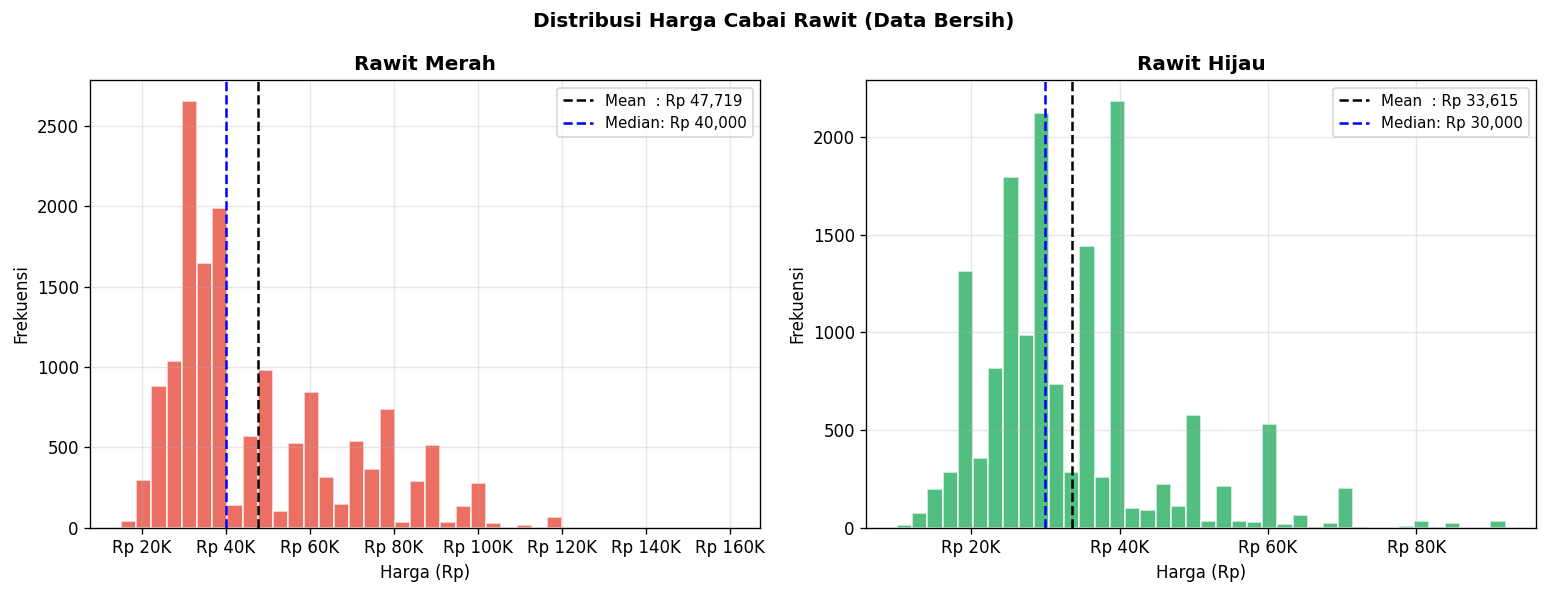

In [439]:
# Visualisasi Distribusi Harga
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Distribusi Harga Cabai Rawit (Data Bersih)', fontweight='bold')

for ax, kolom, label, warna in zip(
    axes,
    ['harga_rawit_merah','harga_rawit_hijau'],
    ['Rawit Merah','Rawit Hijau'],
    ['#e74c3c','#27ae60']
):
    ax.hist(df_lengkap[kolom].dropna(), bins=40,
            color=warna, alpha=0.8, edgecolor='white')
    ax.axvline(df_lengkap[kolom].mean(), color='black', ls='--', lw=1.5,
                label=f'Mean  : Rp {df_lengkap[kolom].mean():,.0f}')
    ax.axvline(df_lengkap[kolom].median(), color='blue', ls='--', lw=1.5,
                label=f'Median: Rp {df_lengkap[kolom].median():,.0f}')
    ax.set_title(label)
    ax.set_xlabel('Harga (Rp)')
    ax.set_ylabel('Frekuensi')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v,_: f'Rp {v/1000:.0f}K'))
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('outputs_r2/distribusi_harga.png', bbox_inches='tight')
plt.show()

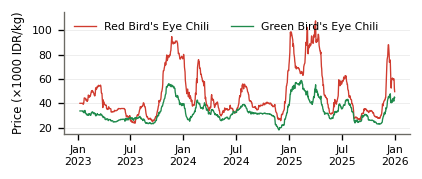

In [440]:
# Tren Harga dari Waktu ke Waktu  -> Fig. 1 di paper
# REVISI: ukuran 1 kolom IEEE, 300 dpi, label bahasa Inggris
import matplotlib.dates as mdates
df_trend = df_lengkap.groupby('tanggal')[['harga_rawit_merah', 'harga_rawit_hijau']].mean() / 1000

with plt.rc_context(GAYA_PAPER):
    fig, ax = plt.subplots(figsize=(3.4, 1.35))
    ax.plot(df_trend.index, df_trend['harga_rawit_merah'], color=RED, lw=.8, label="Red Bird's Eye Chili")
    ax.plot(df_trend.index, df_trend['harga_rawit_hijau'], color=GRN, lw=.8, label="Green Bird's Eye Chili")
    ax.set_ylabel('Price (×1000 IDR/kg)')
    ax.grid(axis='y', alpha=.25, lw=.5)
    ax.xaxis.set_major_locator(mdates.MonthLocator([1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax.legend(frameon=False, loc='upper left', ncol=2)
    ax.set_ylim(15, 115)
    fig.tight_layout(pad=.3)
    plt.savefig('outputs_r2/tren_harga.png', dpi=300, bbox_inches='tight', pad_inches=0.02)
    plt.show()


### 4.7 Ringkasan Cleaning & Simpan File

In [441]:
print("=" * 55)
print("  RINGKASAN HASIL CLEANING")
print("=" * 55)
print(f"  Total baris          : {len(df_lengkap):,}")
print(f"  Jumlah pasar         : {df_lengkap['id_pasar'].nunique()}")
print(f"  Jumlah hari          : {df_lengkap['tanggal'].nunique():,}")
print(f"  Periode              : {df_lengkap['tanggal'].min().date()} s/d {df_lengkap['tanggal'].max().date()}")
print(f"  Sisa NaN harga merah : {df_lengkap['harga_rawit_merah'].isna().sum()}")
print(f"  Sisa NaN harga hijau : {df_lengkap['harga_rawit_hijau'].isna().sum()}")
print("=" * 55)

  RINGKASAN HASIL CLEANING
  Total baris          : 15,232
  Jumlah pasar         : 14
  Jumlah hari          : 1,088
  Periode              : 2023-01-09 s/d 2025-12-31
  Sisa NaN harga merah : 0
  Sisa NaN harga hijau : 0


In [442]:
df_lengkap.info()

<class 'pandas.DataFrame'>
RangeIndex: 15232 entries, 0 to 15231
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   tanggal                    15232 non-null  datetime64[us]
 1   id_pasar                   15232 non-null  str           
 2   nama_pasar                 15232 non-null  str           
 3   latitude                   15232 non-null  float64       
 4   longitude                  15232 non-null  float64       
 5   harga_rawit_merah          15232 non-null  float64       
 6   harga_rawit_hijau          15232 non-null  float64       
 7   harga_rawit_merah_sebelum  11450 non-null  float64       
 8   harga_rawit_hijau_sebelum  11416 non-null  float64       
 9   is_observed_merah          15232 non-null  int64         
 10  is_observed_hijau          15232 non-null  int64         
 11  tahun                      15232 non-null  int32         
dtypes: datetime64[u

In [443]:
# Simpan hasil ke file Excel baru
import os

# Simpan hasil ke file Excel baru
os.makedirs('data', exist_ok=True)
OUTPUT = 'data/dinperindag_2023-2025_clean.xlsx'

with pd.ExcelWriter(OUTPUT, engine='openpyxl') as writer:
    df_lengkap.to_excel(writer, sheet_name='cabai_rawit', index=False)

print(f"File disimpan: {OUTPUT}")

File disimpan: data/dinperindag_2023-2025_clean.xlsx



  Rawit Merah
  Q1          : Rp30.000
  Q3          : Rp60.000
  IQR         : Rp30.000
  Batas Bawah : Rp-15.000
  Batas Atas  : Rp105.000
  Jumlah Outlier: 85 data (0.56%)

  Rawit Hijau
  Q1          : Rp25.000
  Q3          : Rp40.000
  IQR         : Rp15.000
  Batas Bawah : Rp2.500
  Batas Atas  : Rp62.500
  Jumlah Outlier: 411 data (2.70%)


OUTLIER RAWIT MERAH (10 nilai terjauh):
   tanggal nama_pasar  harga_rawit_merah
2025-04-01      BUNTU           160000.0
2025-04-02   LARANGAN           150000.0
2025-03-05     TAMBAK           120000.0
2025-03-04     TAMBAK           120000.0
2025-03-03     TAMBAK           120000.0
2025-03-08     TAMBAK           120000.0
2025-03-09     TAMBAK           120000.0
2025-03-10     TAMBAK           120000.0
2025-03-11     TAMBAK           120000.0
2025-03-12     TAMBAK           120000.0


OUTLIER RAWIT HIJAU (10 nilai terjauh):
   tanggal nama_pasar  harga_rawit_hijau
2023-12-08     TAMBAK            92000.0
2023-12-07     TAMBAK            

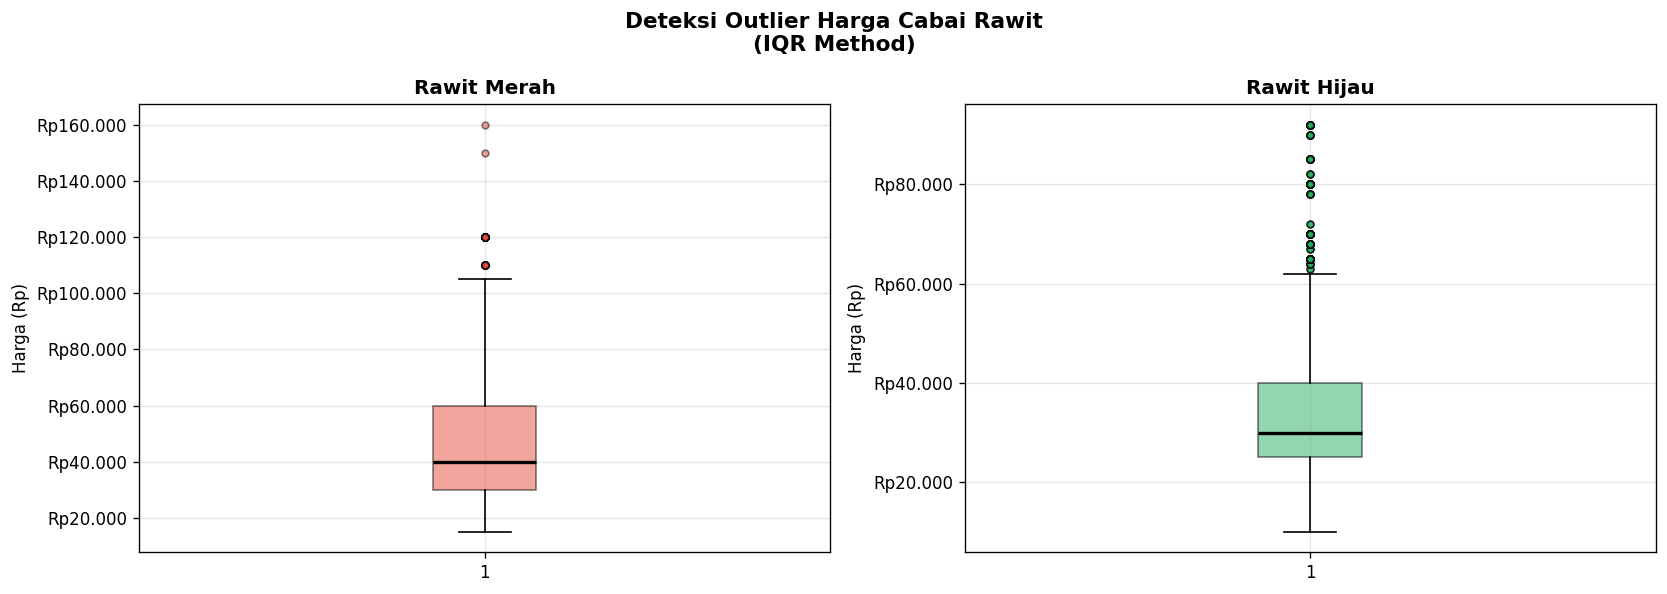

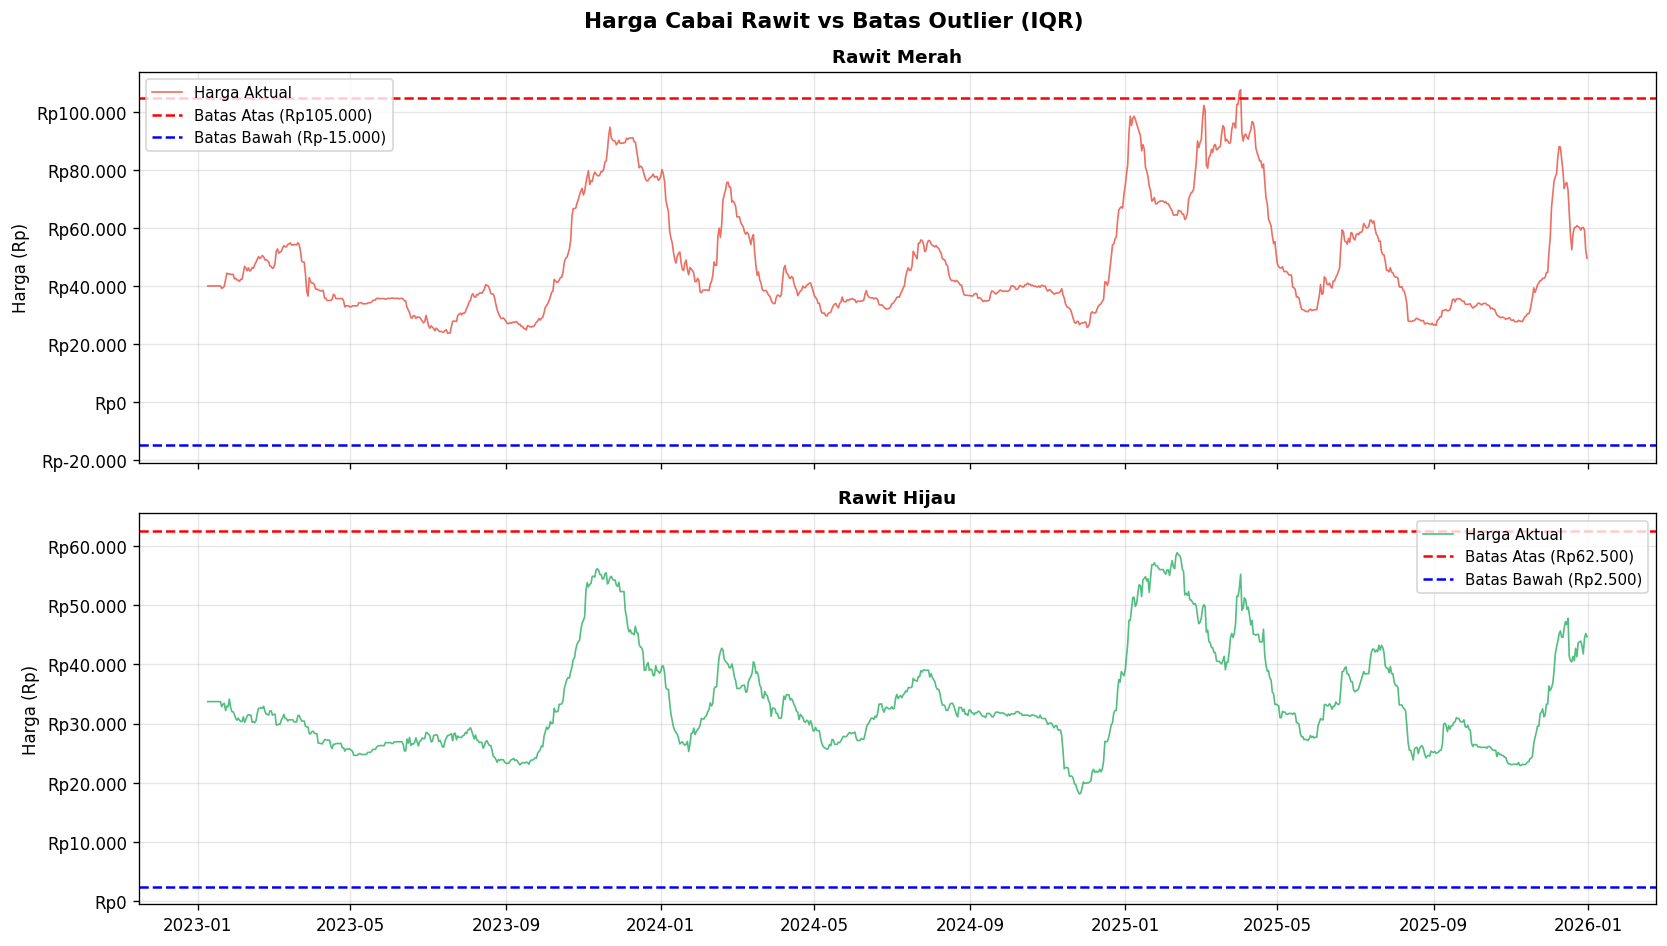


  KESIMPULAN CEK OUTLIER
  Total data    : 30,464
  Total outlier : 496 (1.63%)

  Catatan: Outlier yang terdeteksi kemungkinan
  merupakan lonjakan harga musiman (Lebaran,
  gagal panen) yang valid secara domain.
  Model menggunakan Huber Loss yang robust
  terhadap outlier sehingga tidak dihapus.


In [444]:
# CEK OUTLIER - Data Harga Cabai Rawit
import matplotlib.gridspec as gridspec

# Gunakan df_raw sebelum cleaning (bukan df_lengkap)
df_cek = df_lengkap[['tanggal','nama_pasar','harga_rawit_merah','harga_rawit_hijau']].copy()

# ── Fungsi deteksi outlier IQR ────────────────────────────
def deteksi_outlier_iqr(series, nama):
    Q1  = series.quantile(0.25)
    Q3  = series.quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas  = Q3 + 1.5 * IQR
    outlier = series[(series < batas_bawah) | (series > batas_atas)]
    print(f"\n{'='*50}")
    print(f"  {nama}")
    print(f"{'='*50}")
    print(f"  Q1          : Rp{int(Q1):,}".replace(',','.'))
    print(f"  Q3          : Rp{int(Q3):,}".replace(',','.'))
    print(f"  IQR         : Rp{int(IQR):,}".replace(',','.'))
    print(f"  Batas Bawah : Rp{int(batas_bawah):,}".replace(',','.'))
    print(f"  Batas Atas  : Rp{int(batas_atas):,}".replace(',','.'))
    print(f"  Jumlah Outlier: {len(outlier)} data "
          f"({len(outlier)/len(series)*100:.2f}%)")
    return batas_bawah, batas_atas, outlier

# ── Cek per komoditas ─────────────────────────────────────
merah = df_cek['harga_rawit_merah'].dropna()
hijau = df_cek['harga_rawit_hijau'].dropna()

bb_m, ba_m, out_m = deteksi_outlier_iqr(merah, "Rawit Merah")
bb_h, ba_h, out_h = deteksi_outlier_iqr(hijau, "Rawit Hijau")

# ── Tampilkan 10 outlier terbesar & terkecil ──────────────
print("\n\nOUTLIER RAWIT MERAH (10 nilai terjauh):")
df_out_m = df_cek[df_cek['harga_rawit_merah'].isin(out_m)]\
           [['tanggal','nama_pasar','harga_rawit_merah']]\
           .sort_values('harga_rawit_merah', ascending=False)
print(df_out_m.head(10).to_string(index=False))

print("\n\nOUTLIER RAWIT HIJAU (10 nilai terjauh):")
df_out_h = df_cek[df_cek['harga_rawit_hijau'].isin(out_h)]\
           [['tanggal','nama_pasar','harga_rawit_hijau']]\
           .sort_values('harga_rawit_hijau', ascending=False)
print(df_out_h.head(10).to_string(index=False))

# Visualisasi boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Deteksi Outlier Harga Cabai Rawit\n(IQR Method)', fontsize=13, fontweight='bold')

for ax, data, label, color in [
    (axes[0], merah, 'Rawit Merah', '#E74C3C'),
    (axes[1], hijau, 'Rawit Hijau', '#27AE60')
]:
    ax.boxplot(data.dropna(), patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.5),
               medianprops=dict(color='black', linewidth=2),
               flierprops=dict(marker='o', markerfacecolor=color,
                               markersize=4, alpha=0.5))
    ax.set_title(label, fontsize=12)
    ax.set_ylabel('Harga (Rp)')
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f'Rp{int(x):,}'.replace(',','.')))
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('outputs_r2/outlier_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

# ── Visualisasi time series dengan batas outlier ──────────
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
fig.suptitle('Harga Cabai Rawit vs Batas Outlier (IQR)', fontsize=13, fontweight='bold')

df_plot = df_cek.groupby('tanggal')[
    ['harga_rawit_merah','harga_rawit_hijau']].mean().reset_index()

for ax, kol, label, color, bb, ba in [
    (axes[0], 'harga_rawit_merah', 'Rawit Merah', '#E74C3C', bb_m, ba_m),
    (axes[1], 'harga_rawit_hijau', 'Rawit Hijau', '#27AE60', bb_h, ba_h)
]:
    ax.plot(df_plot['tanggal'], df_plot[kol],
            color=color, linewidth=1, alpha=0.8, label='Harga Aktual')
    ax.axhline(y=ba, color='red', linestyle='--', linewidth=1.5, label=f'Batas Atas (Rp{int(ba):,})'.replace(',','.'))
    ax.axhline(y=bb, color='blue', linestyle='--', linewidth=1.5, label=f'Batas Bawah (Rp{int(bb):,})'.replace(',','.'))
    ax.set_title(label, fontsize=11)
    ax.set_ylabel('Harga (Rp)')
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f'Rp{int(x):,}'.replace(',','.')))
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('outputs_r2/outlier_timeseries.png', dpi=300, bbox_inches='tight')
plt.show()

# ── Kesimpulan ────────────────────────────────────────────
total_data = len(merah) + len(hijau)
total_out  = len(out_m) + len(out_h)
print(f"\n{'='*50}")
print(f"  KESIMPULAN CEK OUTLIER")
print(f"{'='*50}")
print(f"  Total data    : {total_data:,}")
print(f"  Total outlier : {total_out:,} "f"({total_out/total_data*100:.2f}%)")
print(f"\n  Catatan: Outlier yang terdeteksi kemungkinan")
print(f"  merupakan lonjakan harga musiman (Lebaran,")
print(f"  gagal panen) yang valid secara domain.")
print(f"  Model menggunakan Huber Loss yang robust")
print(f"  terhadap outlier sehingga tidak dihapus.")
print(f"{'='*50}")

## STEP 5: Tentukan Batas Waktu Split

**Menentukan batas waktu split sebelum korelasi dan normalisasi.**

Alasannya:
- Korelasi antar pasar harus dihitung dari **data training saja**
- Scaler harus di-*fit* dari **data training saja**

Kalau keduanya dihitung dari semua data (termasuk test), model secara tidak langsung sudah 'tahu' pola di masa depan. Ini namanya **data leakage** dan membuat hasil evaluasi menjadi tidak jujur.

In [445]:
semua_tgl_unik = sorted(df_lengkap['tanggal'].unique())
n_hari         = len(semua_tgl_unik)

n_train = int(n_hari * 0.75)
n_val   = int(n_hari * 0.125)
n_test  = n_hari - n_train - n_val

tgl_train_end = pd.Timestamp(semua_tgl_unik[n_train - 1])
tgl_val_end   = pd.Timestamp(semua_tgl_unik[n_train + n_val - 1])
tgl_test_end  = pd.Timestamp(semua_tgl_unik[-1])

print('=' * 55)
print('  BATAS WAKTU SPLIT')
print('=' * 55)
print(f'  Total hari    : {n_hari}')
print(f'  Train (75%)   : {n_train} hari -> s/d {tgl_train_end.date()}')
print(f'  Val   (12.5%) : {n_val}  hari -> s/d {tgl_val_end.date()}')
print(f'  Test  (12.5%) : {n_test}  hari -> s/d {tgl_test_end.date()}')

  BATAS WAKTU SPLIT
  Total hari    : 1088
  Train (75%)   : 816 hari -> s/d 2025-04-03
  Val   (12.5%) : 136  hari -> s/d 2025-08-17
  Test  (12.5%) : 136  hari -> s/d 2025-12-31


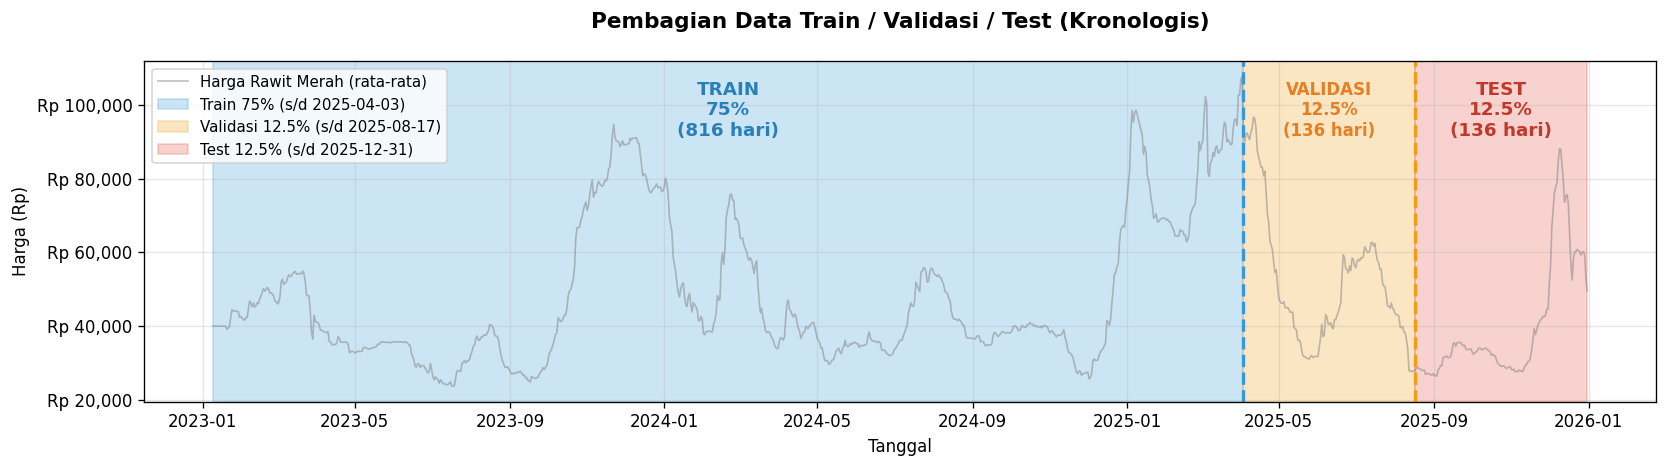

Keterangan:
Data dibagi berdasarkan waktu, bukan random
  - BIRU   = data yang dipakai model untuk BELAJAR
  - ORANYE = data untuk CEK apakah model mulai hafalan
  - MERAH  = data UJIAN ASLI, tidak disentuh sama sekali selama training


In [446]:
fig, ax = plt.subplots(figsize=(14, 4))

df_trend = df_lengkap.groupby('tanggal')['harga_rawit_merah'].mean()

ax.plot(df_trend.index, df_trend.values,
        color='gray', lw=1, alpha=0.5, label='Harga Rawit Merah (rata-rata)')

ax.axvspan(df_trend.index[0], tgl_train_end, alpha=0.25, color='#3498db', label=f'Train 75% (s/d {tgl_train_end.date()})')
ax.axvspan(tgl_train_end, tgl_val_end, alpha=0.25, color='#f39c12', label=f'Validasi 12.5% (s/d {tgl_val_end.date()})')
ax.axvspan(tgl_val_end, df_trend.index[-1], alpha=0.25, color='#e74c3c', label=f'Test 12.5% (s/d {tgl_test_end.date()})')

ax.axvline(tgl_train_end, color='#3498db', lw=2, ls='--')
ax.axvline(tgl_val_end,   color='#f39c12', lw=2, ls='--')

# Posisi teks di bagian bawah grafik supaya tidak tabrakan
y_tinggi = df_trend.max() * 0.85   # teks train di atas
y_rendah = df_trend.max() * 0.20   # teks val & test di bawah

# Label TRAIN
ax.text(df_trend.index[0] + (tgl_train_end - df_trend.index[0]) / 2,
        y_tinggi, 'TRAIN\n75%\n(816 hari)', ha='center', fontsize=11, fontweight='bold', color='#2980b9')

# Label VALIDASI
ax.text(tgl_train_end + (tgl_val_end - tgl_train_end) / 2,
        y_tinggi, 'VALIDASI\n12.5%\n(136 hari)', ha='center', fontsize=10, fontweight='bold', color='#e67e22')

# Label TEST
ax.text(tgl_val_end + (df_trend.index[-1] - tgl_val_end) / 2,
        y_tinggi, 'TEST\n12.5%\n(136 hari)', ha='center', fontsize=11, fontweight='bold', color='#c0392b')

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v,_: f'Rp {v:,.0f}'))
ax.set_title('Pembagian Data Train / Validasi / Test (Kronologis)\n', fontweight='bold', fontsize=13)
ax.set_xlabel('Tanggal')
ax.set_ylabel('Harga (Rp)')

# Pindah legend ke kiri bawah supaya tidak tabrakan
ax.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.savefig('outputs_r2/split_data.png', dpi=300, bbox_inches='tight')
plt.show()

print('Keterangan:')
print('Data dibagi berdasarkan waktu, bukan random')
print('  - BIRU   = data yang dipakai model untuk BELAJAR')
print('  - ORANYE = data untuk CEK apakah model mulai hafalan')
print('  - MERAH  = data UJIAN ASLI, tidak disentuh sama sekali selama training')

## STEP 6: Analisis Korelasi

> Hanya menggunakan **data training** (sebelum tanggal batas) dan hanya baris yang benar-benar tercatat dari lapangan (`is_observed = 1`).

Ini memastikan tidak ada informasi dari periode validasi/test yang 'bocor' ke dalam struktur graph.

In [447]:
# Filter: hanya data training, hanya data asli
df_asli_train = df_lengkap[
    (df_lengkap['tanggal'] <= tgl_train_end) &
    (df_lengkap['is_observed_merah'] == 1) &
    (df_lengkap['is_observed_hijau'] == 1)
].copy()

print(f'Data training asli : {len(df_asli_train):,} baris')
print(f'Pasar              : {df_asli_train["nama_pasar"].nunique()}')
print(f'Periode            : {df_asli_train["tanggal"].min().date()} '
      f's/d {df_asli_train["tanggal"].max().date()}')

Data training asli : 7,898 baris
Pasar              : 14
Periode            : 2023-01-19 s/d 2025-04-03


### 6.1 Korelasi Harga Antar Pasar

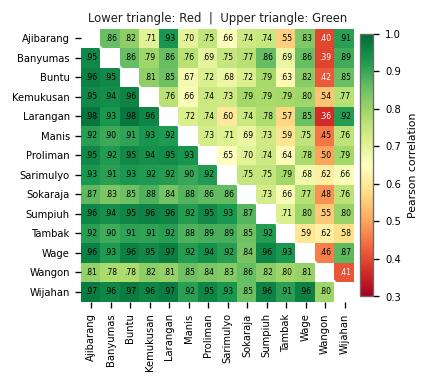

Rawit Merah - rata: 0.908  min: 0.781  max: 0.979
Rawit Hijau  - rata: 0.710  min: 0.363  max: 0.932


In [448]:
pivot_tr_m = df_asli_train.pivot_table(
    index='tanggal', columns='nama_pasar', values='harga_rawit_merah')
pivot_tr_h = df_asli_train.pivot_table(
    index='tanggal', columns='nama_pasar', values='harga_rawit_hijau')

korr_merah = pivot_tr_m.corr()
korr_hijau = pivot_tr_h.corr()

# Heatmap korelasi -> Fig. 3 di paper
# REVISI: satu heatmap (segitiga bawah = Merah, segitiga atas = Hijau) supaya angka lebih besar & terbaca
psr = sorted(korr_merah.columns); n_p = len(psr)
km_ = korr_merah.reindex(index=psr, columns=psr).values
kh_ = korr_hijau.reindex(index=psr, columns=psr).values
Mx = np.full((n_p, n_p), np.nan)
ib, ia = np.tril_indices(n_p, -1), np.triu_indices(n_p, 1)
Mx[ib] = km_[ib]; Mx[ia] = kh_[ia]

with plt.rc_context(GAYA_PAPER):
    fig, ax = plt.subplots(figsize=(3.4, 3.15))
    im = ax.imshow(Mx, cmap='RdYlGn', vmin=0.3, vmax=1)
    for a in range(n_p):
        for b in range(n_p):
            if a != b:
                ax.text(b, a, f'{Mx[a, b]:.2f}'[1:], ha='center', va='center', fontsize=4.6,
                        color='black' if Mx[a, b] > 0.45 else 'white')
    ax.set_xticks(range(n_p)); ax.set_yticks(range(n_p))
    ax.set_xticklabels([p.title() for p in psr], rotation=90, fontsize=6)
    ax.set_yticklabels([p.title() for p in psr], fontsize=6)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.plot([-.5, n_p - .5], [-.5, n_p - .5], color='white', lw=1.5)
    ax.set_title('Lower triangle: Red  |  Upper triangle: Green', fontsize=7, color=INK, pad=4)
    cb = fig.colorbar(im, ax=ax, fraction=.045, pad=.02)
    cb.ax.tick_params(labelsize=6); cb.set_label('Pearson correlation', fontsize=6.5)
    fig.tight_layout(pad=.3)
    plt.savefig('outputs_r2/korelasi_antar_pasar.png', dpi=300, bbox_inches='tight', pad_inches=0.02)
    plt.show()

mask_flat = np.triu(np.ones_like(korr_merah, dtype=bool))
km = korr_merah.where(~mask_flat).stack()
kh = korr_hijau.where(~mask_flat).stack()
print(f'Rawit Merah - rata: {km.mean():.3f}  min: {km.min():.3f}  max: {km.max():.3f}')
print(f'Rawit Hijau  - rata: {kh.mean():.3f}  min: {kh.min():.3f}  max: {kh.max():.3f}')


### 6.2 Korelasi Jarak vs Selisih Harga

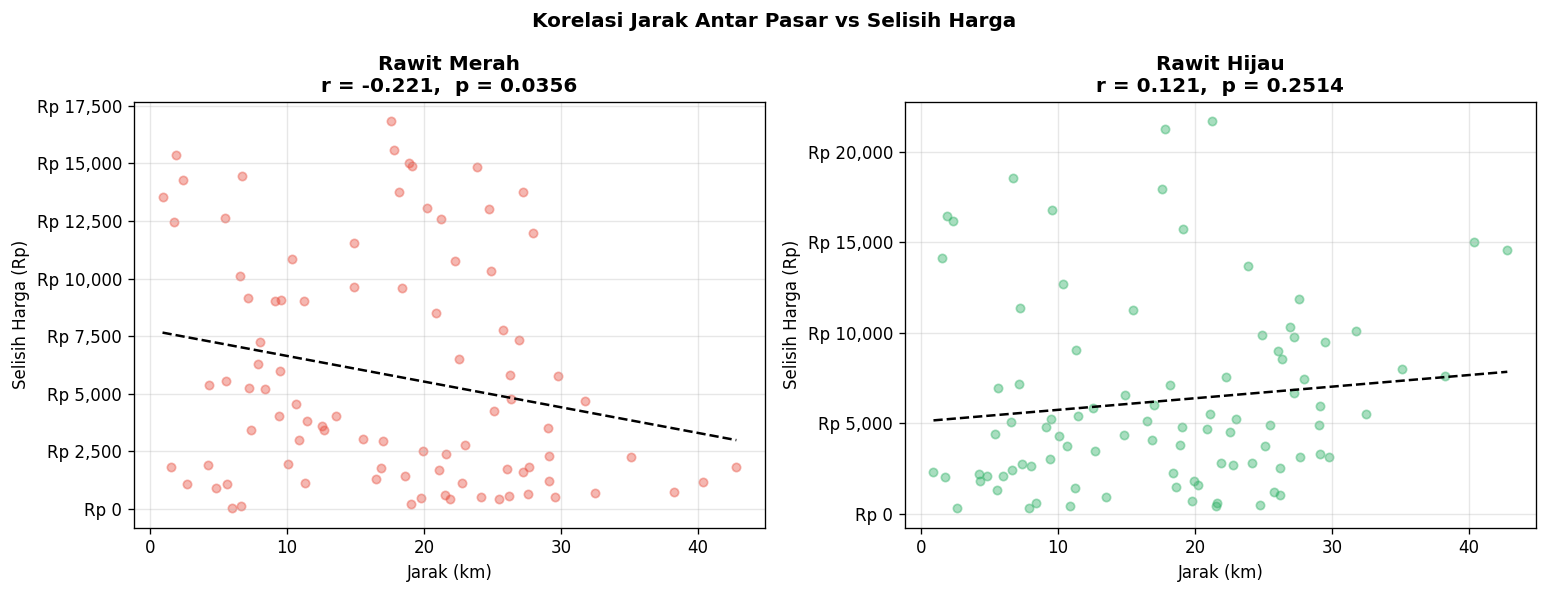

Rawit Merah - r=-0.221, p=0.0356
Rawit Hijau  - r=0.121, p=0.2514


In [449]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371
    lat1,lon1,lat2,lon2 = map(radians,[lat1,lon1,lat2,lon2])
    dlat, dlon = lat2-lat1, lon2-lon1
    a = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlon/2)**2
    return R * 2 * atan2(sqrt(a), sqrt(1-a))

info = df_asli_train.groupby('nama_pasar').agg(
    lat=('latitude','first'), lon=('longitude','first'),
    rm=('harga_rawit_merah','mean'), rh=('harga_rawit_hijau','mean')
).reset_index()

distances, sm, sh = [], [], []
for i in range(len(info)):
    for j in range(i+1, len(info)):
        d = haversine_km(info.iloc[i]['lat'], info.iloc[i]['lon'],
                        info.iloc[j]['lat'], info.iloc[j]['lon'])
        distances.append(d)
        sm.append(abs(info.iloc[i]['rm'] - info.iloc[j]['rm']))
        sh.append(abs(info.iloc[i]['rh'] - info.iloc[j]['rh']))

distances, sm, sh = np.array(distances), np.array(sm), np.array(sh)
r_m, p_m = stats.pearsonr(distances, sm)
r_h, p_h = stats.pearsonr(distances, sh)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Korelasi Jarak Antar Pasar vs Selisih Harga', fontweight='bold')
for ax, sel, label, warna, r, p in zip(
    axes, [sm, sh], ['Rawit Merah','Rawit Hijau'],
    ['#e74c3c','#27ae60'], [r_m, r_h], [p_m, p_h]
):
    ax.scatter(distances, sel, alpha=0.4, color=warna, s=25)
    xl = np.linspace(distances.min(), distances.max(), 100)
    mf, bf = np.polyfit(distances, sel, 1)
    ax.plot(xl, mf*xl+bf, 'k--', lw=1.5)
    ax.set_xlabel('Jarak (km)')
    ax.set_ylabel('Selisih Harga (Rp)')
    ax.set_title(f'{label}\nr = {r:.3f},  p = {p:.4f}')
    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(lambda v,_: f'Rp {v:,.0f}'))
    
plt.tight_layout()
plt.savefig('outputs_r2/korelasi_jarak.png', bbox_inches='tight')
plt.show()

print(f'Rawit Merah - r={r_m:.3f}, p={p_m:.4f}')
print(f'Rawit Hijau  - r={r_h:.3f}, p={p_h:.4f}')

### 6.3 Pola Musiman

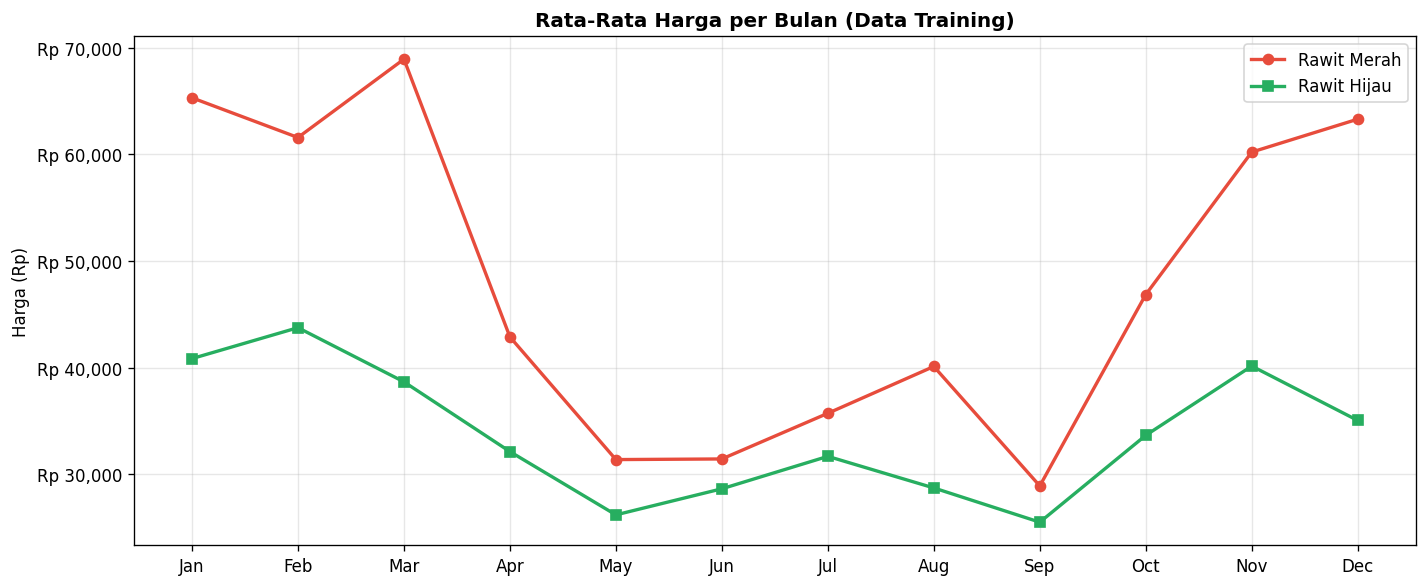

In [450]:
df_asli_train['bulan']      = df_asli_train['tanggal'].dt.month
df_asli_train['nama_bulan'] = df_asli_train['tanggal'].dt.strftime('%b')
per_bulan = (df_asli_train.groupby(['bulan','nama_bulan'])[['harga_rawit_merah','harga_rawit_hijau']].mean().reset_index().sort_values('bulan'))

fig, ax = plt.subplots(figsize=(12, 5))
x = range(len(per_bulan))
ax.plot(x, per_bulan['harga_rawit_merah'], color='#e74c3c', marker='o', ms=6, lw=2, label='Rawit Merah')
ax.plot(x, per_bulan['harga_rawit_hijau'], color='#27ae60', marker='s', ms=6, lw=2, label='Rawit Hijau')
ax.set_xticks(list(x))
ax.set_xticklabels(per_bulan['nama_bulan'])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v,_: f'Rp {v:,.0f}'))

ax.set_title('Rata-Rata Harga per Bulan (Data Training)', fontweight='bold')
ax.set_ylabel('Harga (Rp)')
ax.legend()

plt.tight_layout()
plt.savefig('outputs_r2/pola_musiman.png', bbox_inches='tight')
plt.show()

### 6.4 Korelasi Rawit Merah vs Hijau

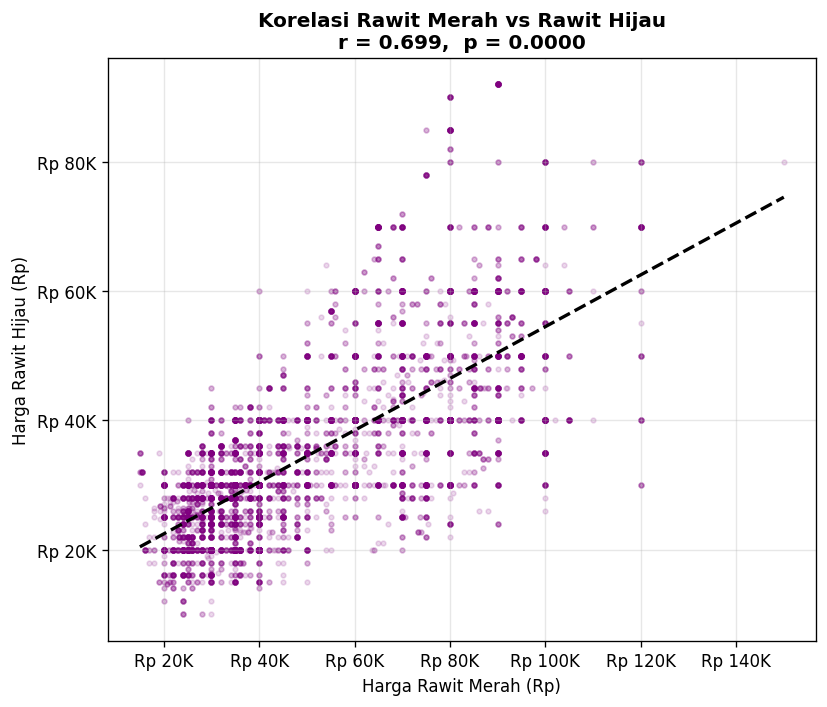

Merah vs Hijau : r=0.699, p=0.0000


In [451]:
r_mh, p_mh = stats.pearsonr(
    df_asli_train['harga_rawit_merah'],
    df_asli_train['harga_rawit_hijau']
)
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(df_asli_train['harga_rawit_merah'], df_asli_train['harga_rawit_hijau'], alpha=0.15, s=8, color='purple')

xl = np.linspace(df_asli_train['harga_rawit_merah'].min(), df_asli_train['harga_rawit_merah'].max(), 100)
mf, bf = np.polyfit(df_asli_train['harga_rawit_merah'], df_asli_train['harga_rawit_hijau'], 1)
ax.plot(xl, mf*xl+bf, 'k--', lw=2)
ax.set_title(f'Korelasi Rawit Merah vs Rawit Hijau\nr = {r_mh:.3f},  p = {p_mh:.4f}', fontweight='bold')
ax.set_xlabel('Harga Rawit Merah (Rp)')
ax.set_ylabel('Harga Rawit Hijau (Rp)')
ax.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda v,_: f'Rp {v/1000:.0f}K'))
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda v,_: f'Rp {v/1000:.0f}K'))

plt.tight_layout()
plt.savefig('outputs_r2/korelasi_mh.png', bbox_inches='tight')
plt.show()
print(f'Merah vs Hijau : r={r_mh:.3f}, p={p_mh:.4f}')

## STEP 7: Adjacency Matrix (Bangun Graph)

Korelasi merah dan hijau digabung (dirata-rata) lalu diterapkan threshold 0.65. Dua pasar dihubungkan hanya jika rata-rata korelasinya >= 0.65.

> Adjacency matrix ini dibangun **hanya dari data training**, sehingga tidak ada informasi masa depan yang bocor ke dalam struktur graph.

### 7.1 Hitung Adj Matrix

In [452]:
daftar_pasar = sorted(list(korr_merah.columns))
N = len(daftar_pasar)

km_val = korr_merah.reindex(index=daftar_pasar, columns=daftar_pasar).values
kh_val = korr_hijau.reindex(index=daftar_pasar, columns=daftar_pasar).values

# Gabung dua korelasi
korr_gabungan = (km_val + kh_val) / 2.0
np.fill_diagonal(korr_gabungan, 0)

# Terapkan threshold
THRESHOLD = 0.65
adj = np.where(korr_gabungan >= THRESHOLD, korr_gabungan, 0).astype(np.float32)

# Row normalization
row_sum = adj.sum(axis=1, keepdims=True)
row_sum[row_sum == 0] = 1.0
adj_norm = (adj / row_sum).astype(np.float32)

jumlah_edge  = (adj_norm > 0).sum()
rata_tetangga = jumlah_edge / N
terisolasi   = [daftar_pasar[i] for i in range(N) if adj_norm[i].sum() == 0]

print(f'Jumlah node     : {N}')
print(f'Threshold       : {THRESHOLD}')
print(f'Jumlah edge     : {jumlah_edge}')
print(f'Rata tetangga   : {rata_tetangga:.1f} per pasar')
print(f'Node terisolasi : {"Tidak ada" if not terisolasi else terisolasi}')

Jumlah node     : 14
Threshold       : 0.65
Jumlah edge     : 170
Rata tetangga   : 12.1 per pasar
Node terisolasi : Tidak ada


### 7.2 Heatmap & Simpan Adj Matrix

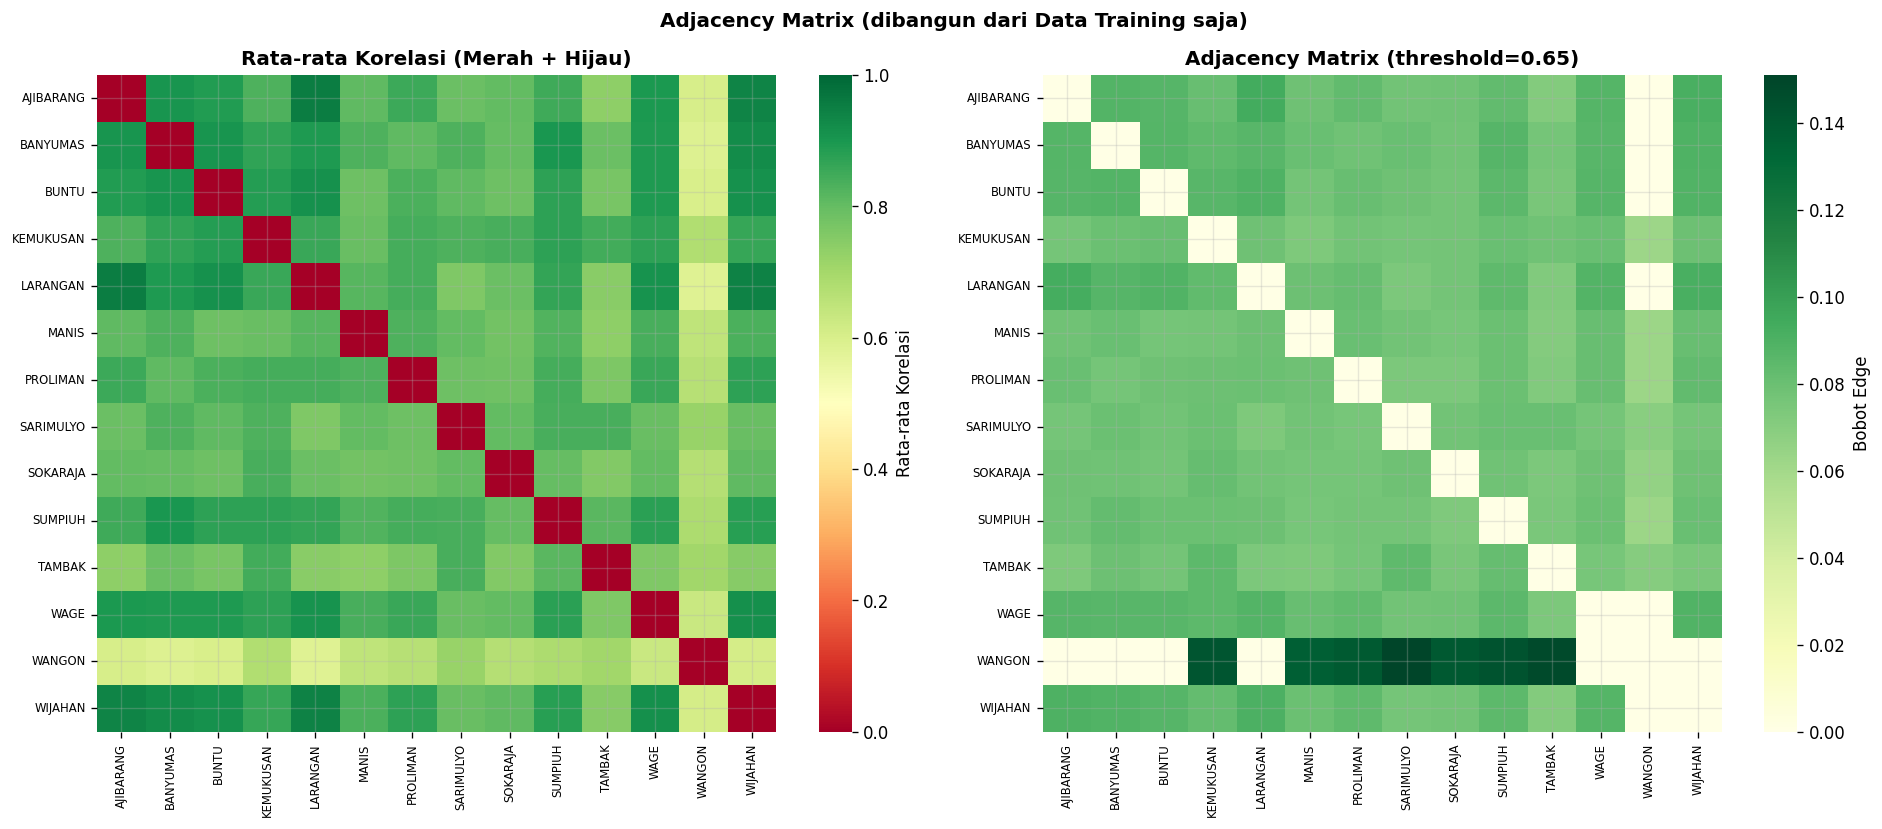

In [453]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Adjacency Matrix (dibangun dari Data Training saja)', fontweight='bold')

sns.heatmap(korr_gabungan, ax=axes[0],
            xticklabels=daftar_pasar, yticklabels=daftar_pasar,
            cmap='RdYlGn', vmin=0, vmax=1,
            cbar_kws={'label':'Rata-rata Korelasi'})
axes[0].set_title('Rata-rata Korelasi (Merah + Hijau)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=90, fontsize=7)
axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0,  fontsize=7)

sns.heatmap(adj_norm, ax=axes[1],
            xticklabels=daftar_pasar, yticklabels=daftar_pasar,
            cmap='YlGn', vmin=0,
            cbar_kws={'label':'Bobot Edge'})
axes[1].set_title(f'Adjacency Matrix (threshold={THRESHOLD})')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=90, fontsize=7)
axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0,  fontsize=7)

plt.tight_layout()
plt.savefig('outputs_r2/adj_matrix.png', bbox_inches='tight')
plt.show()

- corr_avg = matriks korelasi rata-rata (Merah + Hijau) antar 14 pasar.
- WAJIB matriks yang SAMA dengan yang kamu pakai membangun adjacency 0,65,
- supaya baris 0,65 di tabel ini cocok dengan angka 170 edge di Tabel 4.8.

- Kalau belum tersimpan sebagai variabel, rekonstruksi dari pivot training:
1. corr_m   = pivot_train_m.corr()      # korelasi antar pasar utk Rawit Merah
2. corr_h   = pivot_train_h.corr()      # korelasi antar pasar utk Rawit Hijau
3. corr_avg = (corr_m + corr_h) / 2

(pastikan pivot dari data is_observed=1, sama seperti analisis korelasi)

In [454]:
# angka tabel sensitivitas itu (loop threshold 0,55–0,75, hitung edge/tetangga/node terisolasi

daftar_pasar = sorted(list(korr_merah.columns))
N = len(daftar_pasar)

km_val = korr_merah.reindex(index=daftar_pasar, columns=daftar_pasar).values
kh_val = korr_hijau.reindex(index=daftar_pasar, columns=daftar_pasar).values
korr_gab = (km_val + kh_val) / 2.0
np.fill_diagonal(korr_gab, 0)          # buang self-loop

thresholds = [0.55, 0.60, 0.65, 0.70, 0.75]
hasil = []

for thr in thresholds:
    adj_t   = np.where(korr_gab >= thr, korr_gab, 0)   # buang edge lemah
    derajat = (adj_t > 0).sum(axis=1)                  # jumlah tetangga tiap pasar

    jumlah_edge   = int((adj_t > 0).sum())             # total edge berarah (cocok dgn 170)
    rata_tetangga = round(derajat.mean(), 1)
    n_isolasi     = int((derajat == 0).sum())          # pasar tanpa tetangga

    idx_min   = int(np.argmin(derajat))                # pasar tetangga paling sedikit
    pasar_min = f'{daftar_pasar[idx_min]} ({int(derajat[idx_min])})'

    idx_w  = [i for i, n in enumerate(daftar_pasar) if n.upper() == 'WANGON']
    wangon = int(derajat[idx_w[0]]) if idx_w else None

    hasil.append({
        'Threshold': thr,
        'Jumlah Edge': jumlah_edge,
        'Rata-rata Tetangga': rata_tetangga,
        'Tetangga Wangon': wangon,
        'Pasar Tetangga Min': pasar_min,
        'Node Terisolasi': n_isolasi
    })

tabel_sensitivitas = pd.DataFrame(hasil)
print(tabel_sensitivitas.to_string(index=False))

# simpan utk laporan
tabel_sensitivitas.to_excel('outputs_r2/sensitivitas_threshold.xlsx', index=False)

 Threshold  Jumlah Edge  Rata-rata Tetangga  Tetangga Wangon Pasar Tetangga Min  Node Terisolasi
      0.55          182                13.0               13     AJIBARANG (13)                0
      0.60          178                12.7               11        WANGON (11)                0
      0.65          170                12.1                7         WANGON (7)                0
      0.70          160                11.4                2         WANGON (2)                0
      0.75          148                10.6                0         WANGON (0)                1


### 7.3 Visualisasi Graph

In [455]:
import networkx as nx

# Bangun graph dari adjacency matrix
G = nx.Graph()

# Tambah semua node (pasar)
for i, nama in enumerate(daftar_pasar):
    G.add_node(i, label=nama)

# Tambah edge hanya yang bobotnya > 0
for i in range(N):
    for j in range(i + 1, N):
        if adj_norm[i, j] > 0:
            G.add_edge(i, j, weight=float(adj_norm[i, j]))

# Gunakan posisi geografis asli
pos = {}
for i, nama in enumerate(daftar_pasar):
    baris = df_lengkap[df_lengkap['nama_pasar'] == nama].iloc[0]
    pos[i] = (baris['longitude'], baris['latitude'])

# Hitung jumlah tetangga per pasar
degree = dict(G.degree())
node_size    = [degree[n] * 80 for n in G.nodes()]
node_color   = [degree[n] for n in G.nodes()]
edge_weights = [G[u][v]['weight'] * 8 for u, v in G.edges()]

Jumlah pasangan pasar terhubung (edge): 85


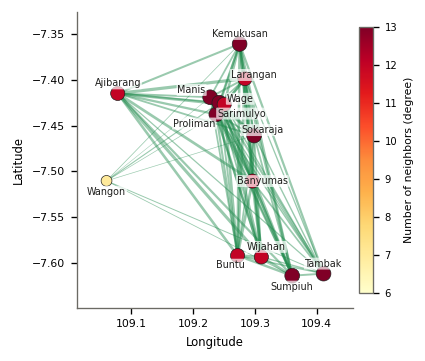

In [456]:
# Graf jaringan pasar -> Fig. 2 di paper
# REVISI: ukuran 1 kolom IEEE, 300 dpi, label bahasa Inggris.
# Ketebalan garis = rata-rata korelasi (adj sebelum row normalization); warna node = jumlah tetangga.
G2 = nx.Graph(); G2.add_nodes_from(range(N))
for a in range(N):
    for b in range(a + 1, N):
        if adj[a, b] > 0:
            G2.add_edge(a, b, w=float(adj[a, b]))
print('Jumlah pasangan pasar terhubung (edge):', G2.number_of_edges())   # 85 (= 170 koneksi berarah / 2)

w_ = np.array([G2[u][v]['w'] for u, v in G2.edges()])
ws = 0.3 + (w_ - w_.min()) / (w_.max() - w_.min() + 1e-9) * 1.6
deg2 = dict(G2.degree())
geser = {'MANIS': (-0.03, 0.008), 'WAGE': (0.026, 0.006), 'SARIMULYO': (0.036, -0.012), 'PROLIMAN': (-0.036, -0.01),
         'SOKARAJA': (0.014, 0.006), 'LARANGAN': (0.014, 0.004), 'KEMUKUSAN': (0, 0.011), 'AJIBARANG': (0, 0.011),
         'WANGON': (0, -0.012), 'BANYUMAS': (0.016, 0), 'BUNTU': (-0.012, -0.01), 'WIJAHAN': (0.008, 0.011),
         'SUMPIUH': (0, -0.012), 'TAMBAK': (0, 0.011)}

with plt.rc_context(GAYA_PAPER):
    fig, ax = plt.subplots(figsize=(3.4, 2.9))
    nx.draw_networkx_edges(G2, pos, ax=ax, width=ws, edge_color=GRN, alpha=.45)
    nc = nx.draw_networkx_nodes(G2, pos, ax=ax, node_size=[deg2[n] * 6 for n in G2],
                                node_color=[deg2[n] for n in G2], cmap='YlOrRd', vmin=6, vmax=13,
                                edgecolors=INK, linewidths=.4)
    for a, p in enumerate(daftar_pasar):
        x, y = pos[a]; ox, oy = geser.get(p, (0, .01))
        ax.text(x + ox, y + oy, p.title(), fontsize=5.8, ha='center', va='center', color=INK,
                bbox=dict(boxstyle='round,pad=0.1', fc='white', ec='none', alpha=.7))
    cb = fig.colorbar(nc, ax=ax, fraction=.045, pad=.02)
    cb.ax.tick_params(labelsize=6); cb.set_label('Number of neighbors (degree)', fontsize=6.5)
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
    ax.margins(.08)
    fig.tight_layout(pad=.3)
    plt.savefig('outputs_r2/graph_jaringan_pasar.png', dpi=500, bbox_inches='tight', pad_inches=0.02)
    plt.show()


In [457]:
# Tabel pasangan tetangga dari adjacency matrix
records = []
for i, pasar_i in enumerate(daftar_pasar):
    tetangga = []
    for j, pasar_j in enumerate(daftar_pasar):
        if i != j and adj_norm[i, j] > 0:
            tetangga.append(f"{pasar_j} ({adj_norm[i,j]:.3f})")

    records.append({
        'Pasar'           : pasar_i,
        'Jumlah Tetangga' : len(tetangga),
        'Daftar Tetangga (bobot)' : ', '.join(sorted(tetangga))
    })

df_tetangga = pd.DataFrame(records).sort_values(
    'Jumlah Tetangga', ascending=False
).reset_index(drop=True)
df_tetangga.index += 1

print('Tabel Tetangga Graph (dari Adjacency Matrix):')
display(df_tetangga)

Tabel Tetangga Graph (dari Adjacency Matrix):


,Pasar,Jumlah Tetangga,Daftar Tetangga (bobot)
1,MANIS,13,"AJIBARANG (0.078), BANYUMAS (0.080), BUNTU (0...."
2,KEMUKUSAN,13,"AJIBARANG (0.076), BANYUMAS (0.080), BUNTU (0...."
3,SUMPIUH,13,"AJIBARANG (0.078), BANYUMAS (0.082), BUNTU (0...."
4,SOKARAJA,13,"AJIBARANG (0.078), BANYUMAS (0.078), BUNTU (0...."
5,SARIMULYO,13,"AJIBARANG (0.076), BANYUMAS (0.080), BUNTU (0...."
6,PROLIMAN,13,"AJIBARANG (0.081), BANYUMAS (0.076), BUNTU (0...."
7,TAMBAK,13,"AJIBARANG (0.073), BANYUMAS (0.079), BUNTU (0...."
8,BUNTU,12,"AJIBARANG (0.087), BANYUMAS (0.088), KEMUKUSAN..."
9,AJIBARANG,12,"BANYUMAS (0.088), BUNTU (0.087), KEMUKUSAN (0...."
10,BANYUMAS,12,"AJIBARANG (0.087), BUNTU (0.087), KEMUKUSAN (0..."


## STEP 8: Normalisasi & Feature Engineering

1. **Pivot data**: ubah dari format tabel panjang menjadi matrix `(hari x pasar)`
2. **Normalisasi harga**: ubah harga (Rp) ke rentang 0–1 menggunakan MinMaxScaler.
   Scaler di-*fit* hanya dari data training, lalu digunakan untuk transform semua data (train/val/test)
3. **Tambah fitur waktu**: sin/cos encoding untuk menangkap pola mingguan dan musiman:
   - `sin_dow`, `cos_dow` → pola hari dalam seminggu
   - `sin_doy`, `cos_doy` → pola hari dalam setahun

Semua fitur digabung menjadi satu tensor: `(1088 hari × 14 pasar × 6 fitur)`

### 8.1 Pivot Data

In [458]:
# Pivot: ubah dari tabel panjang jadi matrix (hari x pasar)
pivot_all_m = df_lengkap.pivot_table(
    index='tanggal', columns='nama_pasar', values='harga_rawit_merah'
).reindex(columns=daftar_pasar)
pivot_all_h = df_lengkap.pivot_table(
    index='tanggal', columns='nama_pasar', values='harga_rawit_hijau'
).reindex(columns=daftar_pasar)

daftar_tanggal = pivot_all_m.index.values

print(f'Shape matrix merah : {pivot_all_m.shape}  (hari x pasar)')
print(f'Shape matrix hijau : {pivot_all_h.shape}  (hari x pasar)')

Shape matrix merah : (1088, 14)  (hari x pasar)
Shape matrix hijau : (1088, 14)  (hari x pasar)


### 8.2 Normalisasi Harga

In [459]:
# Fit scaler HANYA dari data training
pivot_train_m = pivot_all_m[pivot_all_m.index <= tgl_train_end]
pivot_train_h = pivot_all_h[pivot_all_h.index <= tgl_train_end]

scaler_m = MinMaxScaler(feature_range=(0, 1))
scaler_h = MinMaxScaler(feature_range=(0, 1))
scaler_m.fit(pivot_train_m.values)
scaler_h.fit(pivot_train_h.values)

# Transform semua data menggunakan scaler yang sama
# REVISI 2: TANPA np.clip -> harga uji di luar rentang data latih tidak dipotong
# (data latih tetap di 0-1 karena scaler di-fit dari data latih)
X_m = scaler_m.transform(pivot_all_m.values).astype(np.float32)
X_h = scaler_h.transform(pivot_all_h.values).astype(np.float32)

print(f'Scaler fit dari : {pivot_train_m.shape[0]} hari training')
print(f'Min merah : {X_m.min():.3f}  Max merah : {X_m.max():.3f}')
print(f'Min hijau : {X_h.min():.3f}  Max hijau : {X_h.max():.3f}')

Scaler fit dari : 816 hari training
Min merah : -0.089  Max merah : 1.133
Min hijau : -0.077  Max hijau : 1.250


### 8.3 Fitur Waktu & Pembentukan Tensor

In [460]:
# Sin/cos encoding untuk pola waktu
tgl_index = pd.to_datetime(daftar_tanggal)

dow = tgl_index.dayofweek.values   # 0-6 (Senin-Minggu)
doy = tgl_index.dayofyear.values   # 1-365

sin_dow = np.sin(2 * np.pi * dow / 7).astype(np.float32)
cos_dow = np.cos(2 * np.pi * dow / 7).astype(np.float32)
sin_doy = np.sin(2 * np.pi * doy / 365).astype(np.float32)
cos_doy = np.cos(2 * np.pi * doy / 365).astype(np.float32)

# Broadcast ke semua pasar: (n_hari,) → (n_hari, n_pasar)
N_hari, N_pasar = X_m.shape

def broadcast_ke_pasar(arr):
    return np.repeat(arr[:, np.newaxis], N_pasar, axis=1)

sin_dow_mat = broadcast_ke_pasar(sin_dow)
cos_dow_mat = broadcast_ke_pasar(cos_dow)
sin_doy_mat = broadcast_ke_pasar(sin_doy)
cos_doy_mat = broadcast_ke_pasar(cos_doy)

# Gabungkan semua fitur jadi satu tensor
tensor_data = np.stack(
    [X_m, X_h, sin_dow_mat, cos_dow_mat, sin_doy_mat, cos_doy_mat], axis=-1
).astype(np.float32)

print(f'Shape tensor : {tensor_data.shape}  (hari x pasar x fitur)')
print(f'Fitur        : [merah, hijau, sin_dow, cos_dow, sin_doy, cos_doy]')

Shape tensor : (1088, 14, 6)  (hari x pasar x fitur)
Fitur        : [merah, hijau, sin_dow, cos_dow, sin_doy, cos_doy]


### TABEL BEFORE-AFTER: NORMALISASI

In [461]:
tgl_index = pd.to_datetime(daftar_tanggal)
 
rows_norm = []
for i in range(14):  # 14 hari pertama saja, cukup untuk laporan
    for j, pasar in enumerate(daftar_pasar):
        rows_norm.append({
            'tanggal': tgl_index[i].date(),
            'pasar': pasar,
            'harga_merah_sebelum (Rp)': pivot_all_m.values[i, j],
            'harga_merah_sesudah (0-1)': round(float(X_m[i, j]), 4),
            'harga_hijau_sebelum (Rp)': pivot_all_h.values[i, j],
            'harga_hijau_sesudah (0-1)': round(float(X_h[i, j]), 4),
        })
 
df_before_after_norm = pd.DataFrame(rows_norm)
print("TABEL BEFORE-AFTER NORMALISASI")
print(df_before_after_norm.head(10).to_string(index=False))
df_before_after_norm.to_excel('outputs_r2/tabel_before_after_normalisasi.xlsx', index=False)
print("\nTersimpan di outputs_r2/tabel_before_after_normalisasi.xlsx\n")

TABEL BEFORE-AFTER NORMALISASI
   tanggal     pasar  harga_merah_sebelum (Rp)  harga_merah_sesudah (0-1)  harga_hijau_sebelum (Rp)  harga_hijau_sesudah (0-1)
2023-01-09 AJIBARANG                   28000.0                     0.1238                   26000.0                     0.2963
2023-01-09  BANYUMAS                   50000.0                     0.4118                   50000.0                     0.6364
2023-01-09     BUNTU                   32000.0                     0.0986                   17000.0                     0.0400
2023-01-09 KEMUKUSAN                   45000.0                     0.3125                   36000.0                     0.4545
2023-01-09  LARANGAN                   40000.0                     0.1584                   35000.0                     0.3109
2023-01-09     MANIS                   40000.0                     0.2000                   40000.0                     0.3750
2023-01-09  PROLIMAN                   60000.0                     0.3333       

### TABEL BEFORE-AFTER: SIN/COS ENCODING

In [462]:
rows_sincos = []
for i in range(14):
    tgl = tgl_index[i]
    rows_sincos.append({
        'tanggal': tgl.date(),
        'dow_sebelum (0-6)': int(tgl.dayofweek),
        'doy_sebelum (1-365)': int(tgl.dayofyear),
        'sin_dow_sesudah': round(float(sin_dow[i]), 4),
        'cos_dow_sesudah': round(float(cos_dow[i]), 4),
        'sin_doy_sesudah': round(float(sin_doy[i]), 4),
        'cos_doy_sesudah': round(float(cos_doy[i]), 4),
    })
 
df_before_after_sincos = pd.DataFrame(rows_sincos)
print("TABEL BEFORE-AFTER SIN/COS ENCODING")
print(df_before_after_sincos.to_string(index=False))
df_before_after_sincos.to_excel('outputs_r2/tabel_before_after_sincos.xlsx', index=False)
print("\nTersimpan di outputs_r2/tabel_before_after_sincos.xlsx")

TABEL BEFORE-AFTER SIN/COS ENCODING
   tanggal  dow_sebelum (0-6)  doy_sebelum (1-365)  sin_dow_sesudah  cos_dow_sesudah  sin_doy_sesudah  cos_doy_sesudah
2023-01-09                  0                    9           0.0000           1.0000           0.1543           0.9880
2023-01-10                  1                   10           0.7818           0.6235           0.1713           0.9852
2023-01-11                  2                   11           0.9749          -0.2225           0.1882           0.9821
2023-01-12                  3                   12           0.4339          -0.9010           0.2051           0.9787
2023-01-13                  4                   13          -0.4339          -0.9010           0.2219           0.9751
2023-01-14                  5                   14          -0.9749          -0.2225           0.2387           0.9711
2023-01-15                  6                   15          -0.7818           0.6235           0.2554           0.9668
2023-01-16  

## STEP 9: Sliding Window

- **LOOKBACK = 14** : model melihat 14 hari ke belakang sebagai input
- **HORIZON  = 30** : model memprediksi 30 hari ke depan sebagai output

Setiap sampel dibuat dengan menggeser jendela 1 hari:
- Sampel ke-i : X = hari i s/d i+13, y = hari i+14 s/d i+43

In [463]:
LOOKBACK = 14
HORIZON  = 30

X_list, y_list = [], []
for i in range(len(tensor_data) - LOOKBACK - HORIZON + 1):
    X_list.append(tensor_data[i : i + LOOKBACK])
    y_list.append(tensor_data[i + LOOKBACK : i + LOOKBACK + HORIZON])

X_all = np.array(X_list)  # (n_sampel, 14, 25, 6)
y_all = np.array(y_list)  # (n_sampel,  7, 25, 6)

print(f'Total sampel : {len(X_all):,}')
print(f'Shape X      : {X_all.shape}  (sampel x lookback x pasar x fitur)')
print(f'Shape y      : {y_all.shape}  (sampel x horizon  x pasar x fitur)')

Total sampel : 1,045
Shape X      : (1045, 14, 14, 6)  (sampel x lookback x pasar x fitur)
Shape y      : (1045, 30, 14, 6)  (sampel x horizon  x pasar x fitur)


### Tabel Data Masukkan ke Model

In [464]:
import pandas as pd
import os
os.makedirs('outputs_r2', exist_ok=True)

# Pilih 1 sampel sebagai contoh (misal sampel pertama di data training)
IDX_SAMPEL = 0
PASAR_CONTOH = daftar_pasar[0]  # ganti index ini kalau mau pasar lain
idx_pasar = daftar_pasar.index(PASAR_CONTOH)

nama_fitur = ['harga_rawit_merah', 'harga_rawit_hijau', 'sin_dow', 'cos_dow', 'sin_doy', 'cos_doy']

# ===== TABEL INPUT (X): 14 hari LOOKBACK =====
tgl_input = daftar_tanggal[IDX_SAMPEL: IDX_SAMPEL + LOOKBACK]
data_input = X_all[IDX_SAMPEL, :, idx_pasar, :]  # shape: (14 hari, 6 fitur)

tabel_input = pd.DataFrame(data_input, columns=nama_fitur)
tabel_input.insert(0, 'Tanggal', pd.to_datetime(tgl_input).date)
tabel_input.insert(1, 'Pasar', PASAR_CONTOH)

# Tambahkan kolom harga asli (Rupiah), hasil inverse manual dari nilai ternormalisasi
# (scaler_m/scaler_h di-fit per pasar/kolom, jadi inverse_transform butuh semua kolom
#  sekaligus -- di sini kita hitung manual, cukup ambil min-max untuk 1 pasar saja)
min_merah_pasar = scaler_m.data_min_[idx_pasar]
max_merah_pasar = scaler_m.data_max_[idx_pasar]
min_hijau_pasar = scaler_h.data_min_[idx_pasar]
max_hijau_pasar = scaler_h.data_max_[idx_pasar]

tabel_input['harga_merah_rp'] = data_input[:, 0] * (max_merah_pasar - min_merah_pasar) + min_merah_pasar
tabel_input['harga_hijau_rp'] = data_input[:, 1] * (max_hijau_pasar - min_hijau_pasar) + min_hijau_pasar

print("="*70)
print(f"CONTOH INPUT (X) - Sampel ke-{IDX_SAMPEL}, Pasar: {PASAR_CONTOH}")
print(f"14 hari, tanggal {tgl_input[0]} s/d {tgl_input[-1]}")
print("="*70)
print(tabel_input.to_string(index=False))
tabel_input.to_excel('outputs_r2/tabel_contoh_input_x.xlsx', index=False)

# ===== TABEL TARGET (y): 30 hari HORIZON =====
tgl_target = daftar_tanggal[IDX_SAMPEL + LOOKBACK: IDX_SAMPEL + LOOKBACK + HORIZON]
data_target = y_all[IDX_SAMPEL, :, idx_pasar, :]  # shape: (30 hari, 6 fitur)

tabel_target = pd.DataFrame(data_target, columns=nama_fitur)
tabel_target.insert(0, 'Tanggal', pd.to_datetime(tgl_target).date)
tabel_target.insert(1, 'Pasar', PASAR_CONTOH)

tabel_target['harga_merah_rp'] = data_target[:, 0] * (max_merah_pasar - min_merah_pasar) + min_merah_pasar
tabel_target['harga_hijau_rp'] = data_target[:, 1] * (max_hijau_pasar - min_hijau_pasar) + min_hijau_pasar

print()
print("="*70)
print(f"CONTOH TARGET (y) - Sampel ke-{IDX_SAMPEL}, Pasar: {PASAR_CONTOH}")
print(f"30 hari, tanggal {tgl_target[0]} s/d {tgl_target[-1]}")
print("="*70)
print(tabel_target.to_string(index=False))
tabel_target.to_excel('outputs_r2/tabel_contoh_target_y.xlsx', index=False)

print("\nTersimpan di outputs_r2/tabel_contoh_input_x.xlsx dan outputs_r2/tabel_contoh_target_y.xlsx")

CONTOH INPUT (X) - Sampel ke-0, Pasar: AJIBARANG
14 hari, tanggal 2023-01-09T00:00:00.000000 s/d 2023-01-22T00:00:00.000000
   Tanggal     Pasar  harga_rawit_merah  harga_rawit_hijau   sin_dow   cos_dow  sin_doy  cos_doy  harga_merah_rp  harga_hijau_rp
2023-01-09 AJIBARANG            0.12381           0.296296  0.000000  1.000000 0.154309 0.988023    28000.000007    26000.000119
2023-01-10 AJIBARANG            0.12381           0.296296  0.781832  0.623490 0.171293 0.985220    28000.000007    26000.000119
2023-01-11 AJIBARANG            0.12381           0.296296  0.974928 -0.222521 0.188227 0.982126    28000.000007    26000.000119
2023-01-12 AJIBARANG            0.12381           0.296296  0.433884 -0.900969 0.205105 0.978740    28000.000007    26000.000119
2023-01-13 AJIBARANG            0.12381           0.296296 -0.433884 -0.900969 0.221922 0.975065    28000.000007    26000.000119
2023-01-14 AJIBARANG            0.12381           0.296296 -0.974928 -0.222521 0.238673 0.971100    28

## STEP 10: Split Data (REVISI 2: berdasarkan tanggal TARGET + jarak pengaman)

Sampel ke-i: **input** = hari i s/d i+13, **target** = hari i+14 s/d i+43.

Sampel dimasukkan ke train/val/test berdasarkan **tanggal targetnya**:
- **Train** : seluruh target ≤ akhir periode train (3 Apr 2025)
- **Val**   : seluruh target berada di periode val (4 Apr – 17 Agu 2025)
- **Test**  : seluruh target berada di periode test (18 Agu – 31 Des 2025)

Sampel yang targetnya "melintasi" batas dua periode **dibuang** (jarak pengaman / *gap*), sehingga **tidak ada satu pun tanggal target yang dipakai di dua bagian sekaligus**.

> Input sampel uji boleh memakai harga dari periode validasi — itu bukan kebocoran, karena saat memprediksi, harga masa lalu memang sudah diketahui.

In [465]:
# ===== STEP 10: SPLIT DATA (REVISI 2: berdasarkan TANGGAL TARGET + jarak pengaman) =====
tgl_series    = pd.to_datetime(daftar_tanggal)
idx_train_end = np.searchsorted(tgl_series, tgl_train_end, side='right')   # hari pertama SETELAH periode train
idx_val_end   = np.searchsorted(tgl_series, tgl_val_end,   side='right')   # hari pertama SETELAH periode val

n_samp_train = idx_train_end - LOOKBACK - HORIZON + 1   # sampel train: target berakhir <= akhir train
val_mulai    = idx_train_end - LOOKBACK                  # sampel val : target mulai SETELAH akhir train
val_selesai  = idx_val_end - LOOKBACK - HORIZON + 1      #              target berakhir <= akhir val
n_samp_val   = idx_val_end - LOOKBACK                    # (nama lama dipertahankan) = AWAL sampel UJI:
                                                         #   target uji mulai SETELAH akhir val

X_train, y_train = X_all[:n_samp_train],         y_all[:n_samp_train]
X_val,   y_val   = X_all[val_mulai:val_selesai], y_all[val_mulai:val_selesai]
X_test,  y_test  = X_all[n_samp_val:],           y_all[n_samp_val:]

def tgl_target(i_awal, i_akhir):
    return tgl_series[i_awal + LOOKBACK].date(), tgl_series[i_akhir + LOOKBACK + HORIZON - 1].date()

print('=' * 70)
print('  HASIL SPLIT DATA (berdasarkan tanggal target)')
print('=' * 70)
print(f'  Train : {len(X_train):>4} sampel | target {tgl_target(0, n_samp_train-1)[0]} s/d {tgl_target(0, n_samp_train-1)[1]}')
print(f'  Val   : {len(X_val):>4} sampel | target {tgl_target(val_mulai, val_selesai-1)[0]} s/d {tgl_target(val_mulai, val_selesai-1)[1]}')
print(f'  Test  : {len(X_test):>4} sampel | target {tgl_target(n_samp_val, len(X_all)-1)[0]} s/d {tgl_target(n_samp_val, len(X_all)-1)[1]}')
print(f'  Jarak pengaman (sampel dibuang): {val_mulai - n_samp_train} (train-val) + {n_samp_val - val_selesai} (val-test)')

# Pengecekan otomatis: tidak boleh ada tanggal target yang dipakai di dua bagian
assert n_samp_train - 1 + LOOKBACK + HORIZON - 1 < val_mulai + LOOKBACK, 'Target train & val tumpang tindih!'
assert val_selesai - 1 + LOOKBACK + HORIZON - 1 < n_samp_val + LOOKBACK, 'Target val & test tumpang tindih!'
print('  Cek tumpang tindih target: AMAN (tidak ada)')

# Konversi ke tensor PyTorch
def to_t(arr): return torch.FloatTensor(arr).to(device)
X_train_t, y_train_t = to_t(X_train), to_t(y_train)
X_val_t,   y_val_t   = to_t(X_val),   to_t(y_val)
X_test_t,  y_test_t  = to_t(X_test),  to_t(y_test)
adj_t = to_t(adj_norm)
print('Konversi ke tensor selesai.')

  HASIL SPLIT DATA (berdasarkan tanggal target)
  Train :  773 sampel | target 2023-01-23 s/d 2025-04-03
  Val   :  107 sampel | target 2025-04-04 s/d 2025-08-17
  Test  :  107 sampel | target 2025-08-18 s/d 2025-12-31
  Jarak pengaman (sampel dibuang): 29 (train-val) + 29 (val-test)
  Cek tumpang tindih target: AMAN (tidak ada)
Konversi ke tensor selesai.


## STEP 11: Definisi Model ST-GCN & Training Ensemble

**Arsitektur ST-GCN (REVISI):**
- **GCN Layer 1 & 2 (+ BatchNorm)**, masing-masing punya **2 jalur** yang dijumlahkan:
  - jalur **diri sendiri** → fitur pasar itu sendiri
  - jalur **tetangga** → rata-rata tertimbang pasar lain (adjacency, diagonal = 0)
- **GRU 1 layer** → pola temporal dari 14 hari
- **Dropout 0.2 + FC** → **koreksi** harga untuk 30 hari ke depan
- **Output = harga terakhir yang diketahui + koreksi** (residual, seperti NLinear — Zeng dkk., AAAI 2023). Lapisan FC terakhir diinisialisasi nol → model mulai dari *naive persistence*.
- Output hanya **2 fitur harga** (merah, hijau); input tetap 6 fitur.

**Metode Training: Ensemble** — 5 model, seed tetap (10, 1, 3, 42, 7); prediksi final = rata-rata 5 model.

### Definisi Kelas STGCN

In [466]:
class STGCN(nn.Module):
    """
    ST-GCN versi REVISI:
      (1) Tiap lapis GCN punya 2 jalur: diri sendiri (self1/self2) + tetangga (gcn1/gcn2)
      (2) Output hanya 2 harga (merah, hijau); input tetap 6 fitur
      (3) Prediksi = harga terakhir yang diketahui + koreksi (residual ke nilai terakhir,
          seperti NLinear, Zeng dkk. 2023) -> lebih tahan terhadap distribution shift.
          Lapisan output diinisialisasi nol, jadi model mulai dari naive persistence.
    """
    def __init__(self, n_fitur, n_hidden, n_pasar, lookback, horizon, n_out=2):
        super().__init__()
        self.horizon = horizon
        self.n_out   = n_out
        self.n_pasar = n_pasar

        self.self1 = nn.Linear(n_fitur,  n_hidden)   # lapis 1 - jalur diri sendiri
        self.gcn1  = nn.Linear(n_fitur,  n_hidden)   # lapis 1 - jalur tetangga
        self.self2 = nn.Linear(n_hidden, n_hidden)   # lapis 2 - jalur diri sendiri
        self.gcn2  = nn.Linear(n_hidden, n_hidden)   # lapis 2 - jalur tetangga
        self.bn1   = nn.BatchNorm1d(n_pasar)
        self.bn2   = nn.BatchNorm1d(n_pasar)

        self.gru     = nn.GRU(n_hidden, n_hidden, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(0.2)

        self.fc = nn.Sequential(
            nn.Linear(n_hidden, n_hidden // 2),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(n_hidden // 2, horizon * n_out)
        )
        # (3) mulai dari persistence: koreksi awal = 0
        nn.init.zeros_(self.fc[-1].weight)
        nn.init.zeros_(self.fc[-1].bias)

    def gcn_conv(self, x, adj, self_layer, nb_layer, bn_layer):
        agg = torch.einsum('nm,bmd->bnd', adj, x)          # info dari pasar tetangga
        h   = F.relu(self_layer(x) + nb_layer(agg))        # diri sendiri + tetangga
        return bn_layer(h)

    def forward(self, x, adj):
        B, T, N, _ = x.shape
        gcn_outs = []
        for t in range(T):
            h = self.gcn_conv(x[:, t], adj, self.self1, self.gcn1, self.bn1)
            h = self.gcn_conv(h,       adj, self.self2, self.gcn2, self.bn2)
            gcn_outs.append(h)
        gcn_outs = torch.stack(gcn_outs, dim=1)            # (B, T, N, H)

        h = gcn_outs.permute(0, 2, 1, 3).reshape(B * N, T, -1)
        h, _ = self.gru(h)
        h    = self.dropout(h[:, -1, :])

        koreksi = self.fc(h).reshape(B, N, self.horizon, self.n_out)   # perubahan harga
        harga_terakhir = x[:, -1, :, :self.n_out].unsqueeze(2)         # (B, N, 1, 2)
        out = harga_terakhir + koreksi                                 # (3) residual
        return out.permute(0, 2, 1, 3)                                 # (B, HORIZON, N, 2)

print('Kelas STGCN (REVISI: 2 jalur + output 2 harga + residual ke harga terakhir) siap.')

Kelas STGCN (REVISI: 2 jalur + output 2 harga + residual ke harga terakhir) siap.


### Hyperparameter & Utilitas

In [467]:
import copy

# Fungsi untuk membuat batch
def buat_batch(X, y, batch_size, shuffle=True):
    idx = torch.randperm(len(X)) if shuffle else torch.arange(len(X))
    for i in range(0, len(X), batch_size):
        b = idx[i:i + batch_size]
        yield X[b], y[b]

# Fungsi training satu model
def train_model(X_tr, y_tr, X_vl, y_vl, adj, seed,
                     augment=False, noise_std=0.01, verbose=False,
                     X_te_custom=None):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    np.random.seed(seed)

    m    = STGCN(N_FITUR, N_HIDDEN, N_PASAR, LOOKBACK, HORIZON).to(device)
    opt  = torch.optim.Adam(m.parameters(), lr=LR, weight_decay=1e-4)
    crit = nn.HuberLoss(delta=0.1)
    sch  = torch.optim.lr_scheduler.ReduceLROnPlateau(
               opt, mode='min', factor=0.5, patience=10)

    best_v, pat, best_st = float('inf'), 0, None
    h_tr, h_vl = [], []

    for epoch in range(1, EPOCHS + 1):
        m.train()
        ep_loss = []
        for Xb, yb in buat_batch(X_tr, y_tr, BATCH):
            if augment:
                Xb = Xb + torch.randn_like(Xb) * noise_std
            opt.zero_grad()
            loss = crit(m(Xb, adj), yb[..., :N_OUT])   # REVISI: target hanya 2 harga
            loss.backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            opt.step()
            ep_loss.append(loss.item())

        m.eval()
        with torch.no_grad():
            vl = crit(m(X_vl, adj), y_vl[..., :N_OUT]).item()   # REVISI
        tl = np.mean(ep_loss)
        sch.step(vl)
        h_tr.append(tl); h_vl.append(vl)

        if vl < best_v:
            best_v, pat = vl, 0
            best_st = copy.deepcopy(m.state_dict())
        else:
            pat += 1
            if pat >= PATIENCE:
                if verbose: print(f'  Early stop epoch {epoch}')
                break

    m.load_state_dict(best_st)
    train_model.last_state = copy.deepcopy(best_st)   # REVISI: untuk disimpan sebagai model_best.pt
    m.eval()

    X_pred = X_te_custom if X_te_custom is not None else X_test_t
    with torch.no_grad():
        pred_test  = m(X_pred, adj).cpu().numpy()
        pred_train = m(X_tr,   adj).cpu().numpy()

    return pred_test, best_v, h_tr, h_vl, pred_train

# Hyperparameter
N_FITUR  = 6      # fitur INPUT: merah, hijau, sin/cos dow, sin/cos doy
N_OUT    = 2      # REVISI: fitur OUTPUT: hanya harga merah & hijau
N_PASAR  = len(daftar_pasar)
N_HIDDEN = 64
EPOCHS   = 300
LR       = 0.001
BATCH    = 32
PATIENCE = 30
LOOKBACK = 14
HORIZON  = 30

print(f'Arsitektur  : ST-GCN REVISI (GCN 2 jalur x2 + GRU + FC), output {N_OUT} harga')
print(f'N_PASAR     : {N_PASAR} |  N_FITUR : {N_FITUR}')
print(f'N_HIDDEN    : {N_HIDDEN} |  HORIZON : {HORIZON}')
print(f'LOOKBACK    : {LOOKBACK} |  EPOCHS  : {EPOCHS}')

Arsitektur  : ST-GCN REVISI (GCN 2 jalur x2 + GRU + FC), output 2 harga
N_PASAR     : 14 |  N_FITUR : 6
N_HIDDEN    : 64 |  HORIZON : 30
LOOKBACK    : 14 |  EPOCHS  : 300


### Seed Ensemble (tetap: 10, 1, 3, 42, 7)

In [468]:
# Seed search DINONAKTIFKAN (revisi).
# Alasan: kelima seed ensemble dibuat TETAP (10, 1, 3, 42, 7) untuk semua versi
# (graph korelasi, graph jarak, GRU-only) supaya:
#   1) hasil per seed bisa DIPASANGKAN pada paired t-test, dan
#   2) seed tidak dipilih berdasarkan data validasi.
best_seed = 10
print('Seed ensemble tetap: [10, 1, 3, 42, 7]')

Seed ensemble tetap: [10, 1, 3, 42, 7]


### Ensemble Training

In [469]:
SEEDS_ENSEMBLE     = [10, 1, 3, 42, 7]   # REVISI: seed tetap
semua_pred_e       = []
semua_pred_train_e = []

print('=' * 60)
print('  TRAINING ENSEMBLE (5 MODEL)...')
print('=' * 60)

for idx_s, seed in enumerate(SEEDS_ENSEMBLE):
    pred_e, bv, h_tr, h_vl, pred_tr = train_model(
        X_train_t, y_train_t, X_val_t, y_val_t,
        adj_t, seed=seed, verbose=True
    )
    semua_pred_e.append(pred_e)
    semua_pred_train_e.append(pred_tr)

    if idx_s == 0:
        history_train = h_tr
        history_val   = h_vl
        best_epoch    = max(1, len(h_tr) - PATIENCE)
        best_state_dict = train_model.last_state   # model seed 10 (untuk dashboard)

    print(f'  Seed {seed:>3}  |  val loss: {bv:.6f}  |  epochs: {len(h_tr)}')

pred_np       = np.mean(semua_pred_e,       axis=0)
pred_train_np = np.mean(semua_pred_train_e, axis=0)

print(f'\n  Shape prediksi test  : {pred_np.shape}')
print(f'  Shape prediksi train : {pred_train_np.shape}')
print('  Training Ensemble selesai.')

  TRAINING ENSEMBLE (5 MODEL)...


  Early stop epoch 53
  Seed  10  |  val loss: 0.007561  |  epochs: 53
  Early stop epoch 44
  Seed   1  |  val loss: 0.007877  |  epochs: 44
  Early stop epoch 63
  Seed   3  |  val loss: 0.007732  |  epochs: 63
  Early stop epoch 61
  Seed  42  |  val loss: 0.007412  |  epochs: 61
  Early stop epoch 59
  Seed   7  |  val loss: 0.007227  |  epochs: 59

  Shape prediksi test  : (107, 30, 14, 2)
  Shape prediksi train : (773, 30, 14, 2)
  Training Ensemble selesai.


### Visualisasi Training Loss

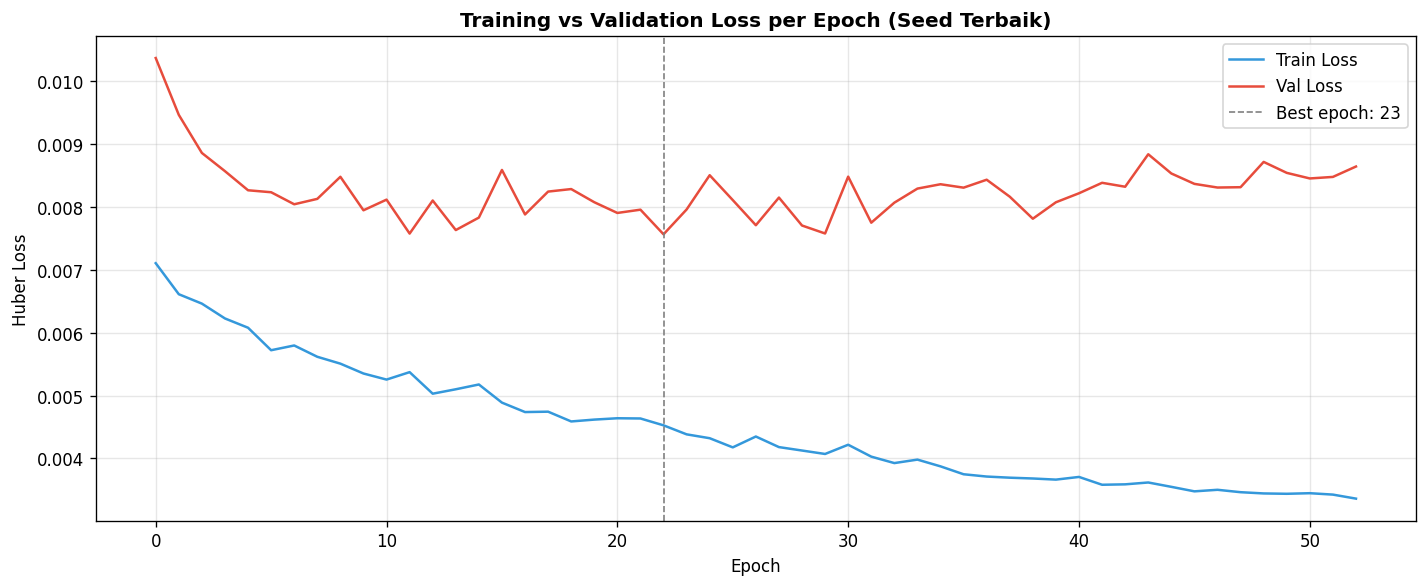

Train loss akhir : 0.003362
Val loss akhir   : 0.008638
Gap (val-train)  : 0.005276
Catatan: gap loss val-train hanya indikasi kasar. Penilaian overfitting dilihat dari MAPE training vs testing (lihat sel di bawah).


In [470]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(history_train, color='#3498db', lw=1.5, label='Train Loss')
ax.plot(history_val,   color='#e74c3c', lw=1.5, label='Val Loss')
ax.axvline(best_epoch - 1, color='gray', ls='--', lw=1, label=f'Best epoch: {best_epoch}')
ax.set_title('Training vs Validation Loss per Epoch (Seed Terbaik)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Huber Loss'); ax.legend()

plt.tight_layout()
plt.savefig('outputs_r2/training_loss.png', bbox_inches='tight')
plt.show()

gap = history_val[-1] - history_train[-1]
print(f'Train loss akhir : {history_train[-1]:.6f}')
print(f'Val loss akhir   : {history_val[-1]:.6f}')
print(f'Gap (val-train)  : {gap:.6f}')
print('Catatan: gap loss val-train hanya indikasi kasar. Penilaian overfitting '
      'dilihat dari MAPE training vs testing (lihat sel di bawah).')

## STEP 12: Evaluasi Model

Evaluasi dilakukan pada **data test** yang belum pernah dilihat model.
Metode: **Fixed Split + Ensemble** (5 model, rata-rata prediksi).

Metrik yang digunakan:
- **MAE**  : rata-rata selisih absolut (Rupiah)
- **RMSE** : seperti MAE, lebih sensitif ke error besar
- **MAPE** : error dalam persen — Akurasi = 100% - MAPE
- **R²**   : seberapa baik model menangkap pola naik-turun harga
  - R² mendekati 1 = sangat baik
  - R² negatif     = model lebih buruk dari sekadar prediksi rata-rata

### Fungsi Metrik & Inverse Transform

In [471]:
# Fungsi metrik evaluasi
def mape(yt, yp):
    n = yt.shape[-1]
    hasil = []
    for i in range(n):
        y_i = yt[..., i].flatten()
        p_i = yp[..., i].flatten()
        mask = y_i > 500
        if mask.sum() > 0:
            hasil.append(
                np.mean(np.abs((y_i[mask] - p_i[mask]) / y_i[mask])) * 100
            )
    return np.mean(hasil)

def mae(yt, yp):
    n = yt.shape[-1]
    hasil = []
    for i in range(n):
        hasil.append(np.mean(np.abs(yt[..., i] - yp[..., i])))
    return np.mean(hasil)

def rmse(yt, yp):
    n = yt.shape[-1]
    hasil = []
    for i in range(n):
        hasil.append(np.sqrt(np.mean((yt[..., i] - yp[..., i])**2)))
    return np.mean(hasil)

def r2(yt, yp):
    n = yt.shape[-1]
    hasil = []
    for i in range(n):
        y_i = yt[..., i].flatten()
        p_i = yp[..., i].flatten()
        ss_res = np.sum((y_i - p_i)**2)
        ss_tot = np.sum((y_i - np.mean(y_i))**2)
        if ss_tot != 0:
            hasil.append(1 - ss_res / ss_tot)
    return np.mean(hasil)

# Inverse transform ke Rupiah
def inverse_tr(arr, scaler):
    n, h, p = arr.shape
    return scaler.inverse_transform(arr.reshape(n*h, p)).reshape(n, h, p)

# Ambil prediksi dan aktual
y_np      = y_test_t.cpu().numpy()
pred_m_rp = inverse_tr(pred_np[:,:,:,0], scaler_m)
pred_h_rp = inverse_tr(pred_np[:,:,:,1], scaler_h)
# REVISI 2: harga aktual uji diambil langsung dari data harga (Rupiah asli)
idx0   = n_samp_val + LOOKBACK            # indeks hari target pertama sampel uji ke-0
y_m_rp = np.stack([pivot_all_m.values[idx0+i : idx0+i+HORIZON] for i in range(len(X_test))])
y_h_rp = np.stack([pivot_all_h.values[idx0+i : idx0+i+HORIZON] for i in range(len(X_test))])
assert np.allclose(y_m_rp, inverse_tr(y_np[:,:,:,0], scaler_m), atol=1), 'Target tidak cocok!'

print(f'Shape prediksi : {pred_np.shape}')
print(f'Aktual merah   : Rp {y_m_rp.min():,.0f} - Rp {y_m_rp.max():,.0f}')
print(f'Aktual hijau   : Rp {y_h_rp.min():,.0f} - Rp {y_h_rp.max():,.0f}')

Shape prediksi : (107, 30, 14, 2)
Aktual merah   : Rp 20,000 - Rp 100,000
Aktual hijau   : Rp 15,000 - Rp 82,000


### Ringkasan & Akurasi

In [472]:
mape_m = mape(y_m_rp, pred_m_rp); akr_m = max(0, 100-mape_m)
mape_h = mape(y_h_rp, pred_h_rp); akr_h = max(0, 100-mape_h)
akr      = (akr_m + akr_h) / 2
mape_avg = (mape_m + mape_h) / 2

print('=' * 55)
print('  RINGKASAN EVALUASI MODEL ST-GCN (ENSEMBLE)')
print('=' * 55)
print(f'  Rawit Merah:')
print(f'    MAE      : Rp {mae(y_m_rp, pred_m_rp):,.0f}')
print(f'    RMSE     : Rp {rmse(y_m_rp, pred_m_rp):,.0f}')
print(f'    MAPE     : {mape_m:.2f}%')
print(f'    R²       : {r2(y_m_rp, pred_m_rp):.4f}')
print(f'    Akurasi  : {akr_m:.2f}%')
print()
print(f'  Rawit Hijau:')
print(f'    MAE      : Rp {mae(y_h_rp, pred_h_rp):,.0f}')
print(f'    RMSE     : Rp {rmse(y_h_rp, pred_h_rp):,.0f}')
print(f'    MAPE     : {mape_h:.2f}%')
print(f'    R²       : {r2(y_h_rp, pred_h_rp):.4f}')
print(f'    Akurasi  : {akr_h:.2f}%')
print()
print(f'  MAPE Rata-rata    : {mape_avg:.2f}%')
print(f'  Akurasi Rata-rata : {akr:.2f}%')

  RINGKASAN EVALUASI MODEL ST-GCN (ENSEMBLE)
  Rawit Merah:
    MAE      : Rp 10,394
    RMSE     : Rp 15,852
    MAPE     : 25.46%
    R²       : -0.0128
    Akurasi  : 74.54%

  Rawit Hijau:
    MAE      : Rp 6,278
    RMSE     : Rp 9,144
    MAPE     : 20.59%
    R²       : -0.4972
    Akurasi  : 79.41%

  MAPE Rata-rata    : 23.03%
  Akurasi Rata-rata : 76.97%


### MAPE per Seed (REVISI: bahan paired t-test)

In [473]:
# ===== MAPE PER SEED + RINGKASAN (bahan tabel perbandingan & paired t-test) =====
import json
VERSI = 'korelasi'

def ringkas_prediksi(pred):
    """Metrik ringkas dari prediksi skala 0-1 berbentuk (sampel, 30, 14, >=2)."""
    pm = inverse_tr(pred[:, :, :, 0], scaler_m)
    ph = inverse_tr(pred[:, :, :, 1], scaler_h)
    hasil = {
        'MAPE Merah': mape(y_m_rp, pm), 'MAPE Hijau': mape(y_h_rp, ph),
        'MAE Merah' : mae(y_m_rp, pm),  'MAE Hijau' : mae(y_h_rp, ph),
        'RMSE Merah': rmse(y_m_rp, pm), 'RMSE Hijau': rmse(y_h_rp, ph),
        'R2 Merah'  : r2(y_m_rp, pm),   'R2 Hijau'  : r2(y_h_rp, ph),
    }
    hasil['MAPE Rata2'] = (hasil['MAPE Merah'] + hasil['MAPE Hijau']) / 2
    for h in [1, 7, 14, 21, 30]:
        hasil[f'MAPE H{h}'] = (mape(y_m_rp[:, h-1, :], pm[:, h-1, :]) +
                               mape(y_h_rp[:, h-1, :], ph[:, h-1, :])) / 2
    hasil['MAPE per pasar'] = {
        p: (mape(y_m_rp[:, :, i:i+1], pm[:, :, i:i+1]) + mape(y_h_rp[:, :, i:i+1], ph[:, :, i:i+1])) / 2
        for i, p in enumerate(daftar_pasar)}
    return hasil

mape_per_seed = {}
for seed, p in zip(SEEDS_ENSEMBLE, semua_pred_e):
    mape_per_seed[str(seed)] = ringkas_prediksi(p)['MAPE Rata2']
    print(f'  Seed {seed:>3} -> MAPE rata-rata {mape_per_seed[str(seed)]:.2f}%')
vals = np.array(list(mape_per_seed.values()))
print(f'  Rata-rata 5 seed: {vals.mean():.2f}% (std {vals.std(ddof=1):.2f}) | Ensemble: {mape_avg:.2f}%')

ringkasan = ringkas_prediksi(pred_np)
ringkasan['per_seed'] = mape_per_seed
os.makedirs('outputs_r2', exist_ok=True)
with open(f'outputs_r2/ringkasan_{VERSI}.json', 'w') as f:
    json.dump(ringkasan, f, indent=2, default=float)
print(f'\nTersimpan: outputs_r2/ringkasan_{VERSI}.json')

  Seed  10 -> MAPE rata-rata 22.19%
  Seed   1 -> MAPE rata-rata 21.26%
  Seed   3 -> MAPE rata-rata 27.84%
  Seed  42 -> MAPE rata-rata 22.38%
  Seed   7 -> MAPE rata-rata 28.20%
  Rata-rata 5 seed: 24.37% (std 3.36) | Ensemble: 23.03%

Tersimpan: outputs_r2/ringkasan_korelasi.json


### Evaluasi per Horizon

In [474]:
# Evaluasi per horizon: MAE, RMSE, MAPE, R²
rows = []
for h in range(HORIZON):
    ym = y_m_rp[:,h,:];  pm = pred_m_rp[:,h,:]
    yh = y_h_rp[:,h,:];  ph = pred_h_rp[:,h,:]
    mape_m_h = round(mape(ym, pm), 2)
    mape_h_h = round(mape(yh, ph), 2)
    rows.append({
        'Horizon'         : f'Hari ke-{h+1}',
        'MAE Merah (Rp)'  : round(mae(ym, pm)),
        'RMSE Merah (Rp)' : round(rmse(ym, pm)),
        'MAPE Merah (%)'   : mape_m_h,
        'R2 Merah'         : round(r2(ym, pm), 4),
        'MAE Hijau (Rp)'  : round(mae(yh, ph)),
        'RMSE Hijau (Rp)' : round(rmse(yh, ph)),
        'MAPE Hijau (%)'   : mape_h_h,
        'R2 Hijau'         : round(r2(yh, ph), 4),
        'MAPE Rata2 (%)'   : round((mape_m_h + mape_h_h) / 2, 2),
        'Akurasi Rata2 (%)': round(100 - (mape_m_h + mape_h_h) / 2, 2),
    })

mape_m_avg = round(mape(y_m_rp, pred_m_rp), 2)
mape_h_avg = round(mape(y_h_rp, pred_h_rp), 2)
rows.append({
    'Horizon'         : 'RATA-RATA',
    'MAE Merah (Rp)'  : round(mae(y_m_rp, pred_m_rp)),
    'RMSE Merah (Rp)' : round(rmse(y_m_rp, pred_m_rp)),
    'MAPE Merah (%)'   : mape_m_avg,
    'R2 Merah'         : round(r2(y_m_rp, pred_m_rp), 4),
    'MAE Hijau (Rp)'  : round(mae(y_h_rp, pred_h_rp)),
    'RMSE Hijau (Rp)' : round(rmse(y_h_rp, pred_h_rp)),
    'MAPE Hijau (%)'   : mape_h_avg,
    'R2 Hijau'         : round(r2(y_h_rp, pred_h_rp), 4),
    'MAPE Rata2 (%)'   : round((mape_m_avg + mape_h_avg) / 2, 2),
    'Akurasi Rata2 (%)': round(100 - (mape_m_avg + mape_h_avg) / 2, 2),
})

df_horizon = pd.DataFrame(rows)
print('EVALUASI PER HORIZON — Fixed Split + Ensemble')
display(df_horizon)

EVALUASI PER HORIZON — Fixed Split + Ensemble


,Horizon,MAE Merah (Rp),RMSE Merah (Rp),MAPE Merah (%),R2 Merah,MAE Hijau (Rp),RMSE Hijau (Rp),MAPE Hijau (%),R2 Hijau,MAPE Rata2 (%),Akurasi Rata2 (%)
0,Hari ke-1,1070,2464,3.13,0.8372,680,2011,2.49,0.7804,2.81,97.19
1,Hari ke-2,1995,3949,5.63,0.6534,1260,2829,4.54,0.5790,5.08,94.92
2,Hari ke-3,2824,5172,7.75,0.4904,1827,3439,6.56,0.3716,7.15,92.84
3,Hari ke-4,3526,6359,9.39,0.4802,2274,3867,8.15,0.2041,8.77,91.23
4,Hari ke-5,4210,7387,10.94,0.4397,2649,4262,9.38,0.0582,10.16,89.84
5,Hari ke-6,4894,8319,12.49,0.4074,3011,4724,10.51,-0.1277,11.50,88.50
6,Hari ke-7,5618,9383,14.04,0.3747,3403,5232,11.77,0.0860,12.90,87.10
7,Hari ke-8,6402,10502,15.70,0.3418,3829,5789,13.10,0.0159,14.40,85.60
8,Hari ke-9,7177,11573,17.30,0.3076,4203,6298,14.20,-0.0464,15.75,84.25
9,Hari ke-10,7907,12520,18.87,0.2725,4579,6739,15.37,-0.1062,17.12,82.88


### MAPE Per Pasar

In [475]:
hasil_pasar = []
for i, pasar in enumerate(daftar_pasar):
    mm  = mape(y_m_rp[:,:,i], pred_m_rp[:,:,i])
    mh  = mape(y_h_rp[:,:,i], pred_h_rp[:,:,i])
    hasil_pasar.append({
        'Pasar'         : pasar,
        'MAPE Merah (%)': round(mm, 2),
        'MAPE Hijau (%)': round(mh, 2),
        'Rata-rata (%)'  : round((mm+mh)/2, 2)
    })

df_pasar = pd.DataFrame(hasil_pasar).sort_values('Rata-rata (%)').reset_index(drop=True)
df_pasar.index += 1
print('MAPE PER PASAR — Fixed Split + Ensemble')
display(df_pasar)

MAPE PER PASAR — Fixed Split + Ensemble


,Pasar,MAPE Merah (%),MAPE Hijau (%),Rata-rata (%)
1,WANGON,14.78,10.68,12.73
2,TAMBAK,15.86,10.36,13.11
3,SARIMULYO,21.58,17.31,19.44
4,BANYUMAS,22.85,19.07,20.96
5,SUMPIUH,20.65,22.66,21.65
6,MANIS,23.43,20.28,21.86
7,KEMUKUSAN,31.89,14.07,22.98
8,WIJAHAN,27.60,21.86,24.73
9,LARANGAN,29.14,20.75,24.94
10,PROLIMAN,26.49,25.64,26.06


### Bar Chart MAPE per Pasar

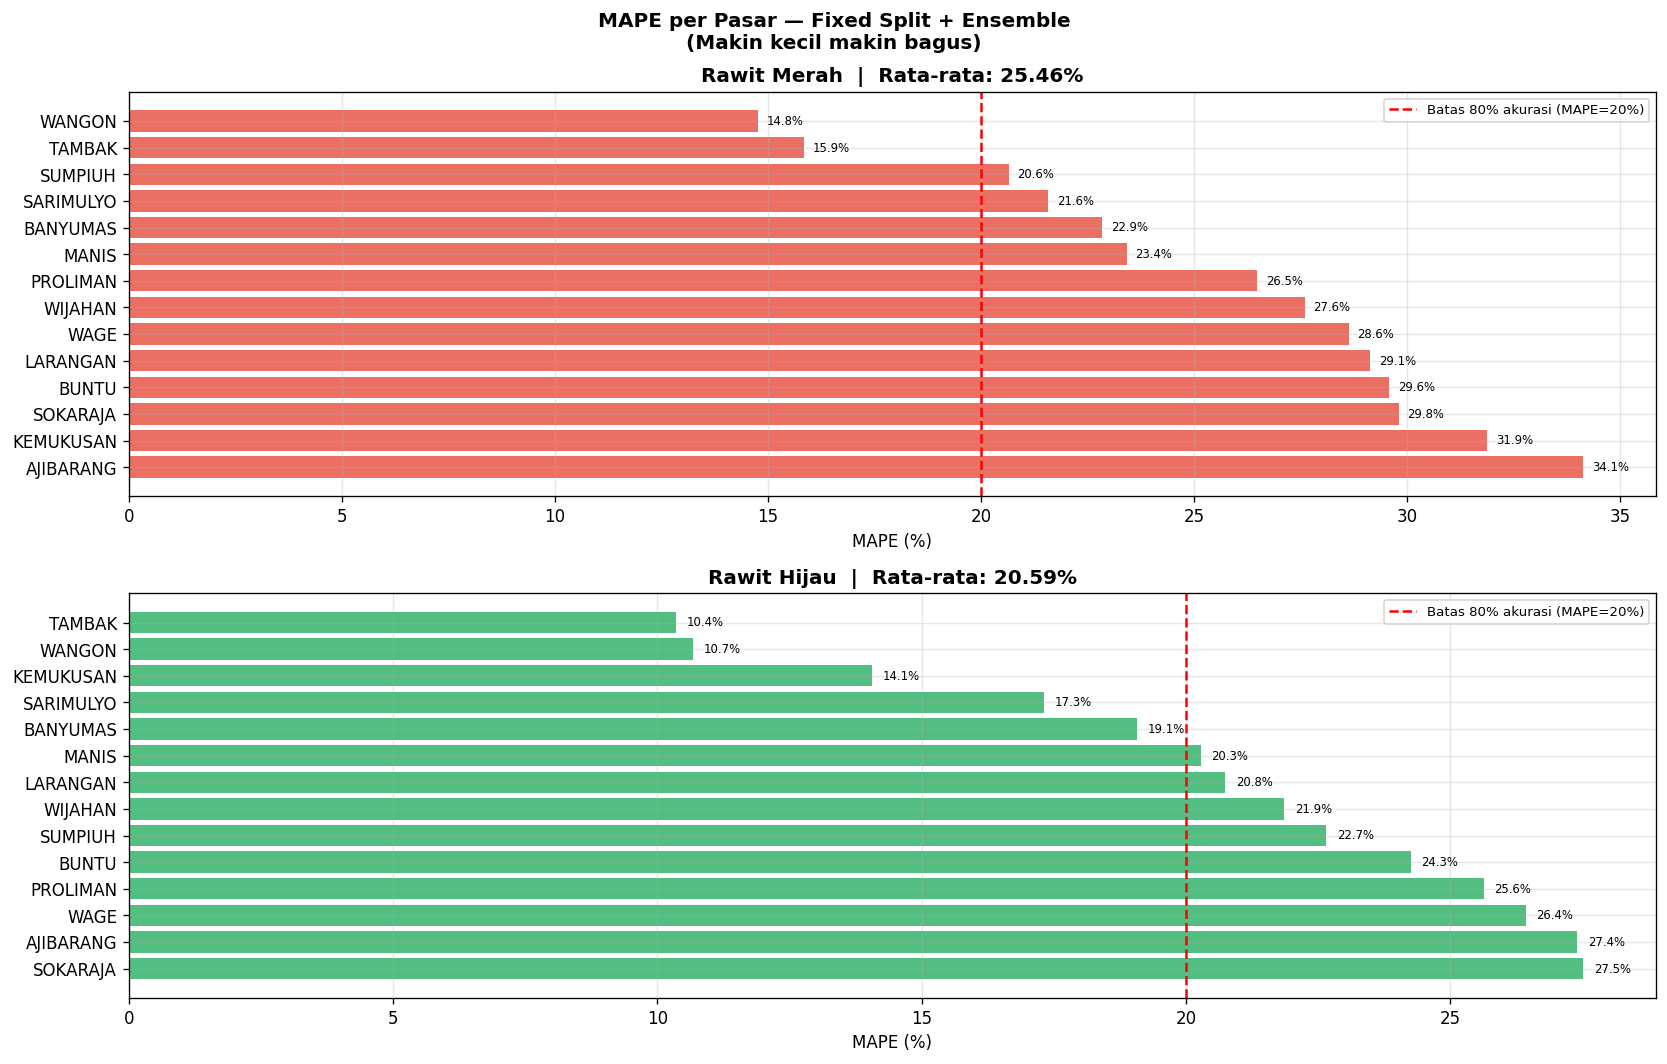

In [476]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
fig.suptitle('MAPE per Pasar — Fixed Split + Ensemble\n(Makin kecil makin bagus)',
            fontweight='bold')
for ax, kolom, label, warna in zip(
    axes, ['MAPE Merah (%)','MAPE Hijau (%)'],
    ['Rawit Merah','Rawit Hijau'], ['#e74c3c','#27ae60']
):
    ds   = df_pasar.sort_values(kolom, ascending=False)
    bars = ax.barh(ds['Pasar'], ds[kolom], color=warna, alpha=0.8)
    ax.axvline(20, color='red', ls='--', lw=1.5, label='Batas 80% akurasi (MAPE=20%)')
    ax.set_xlabel('MAPE (%)'); ax.legend(fontsize=8)
    ax.set_title(f'{label}  |  Rata-rata: {ds[kolom].mean():.2f}%')
    for bar, val in zip(bars, ds[kolom]):
        ax.text(val+0.2, bar.get_y()+bar.get_height()/2,
                f'{val:.1f}%', va='center', fontsize=7)
        
plt.tight_layout()
plt.savefig('outputs_r2/mape_per_pasar.png', bbox_inches='tight')
plt.show()

### Visualisasi Prediksi vs Aktual

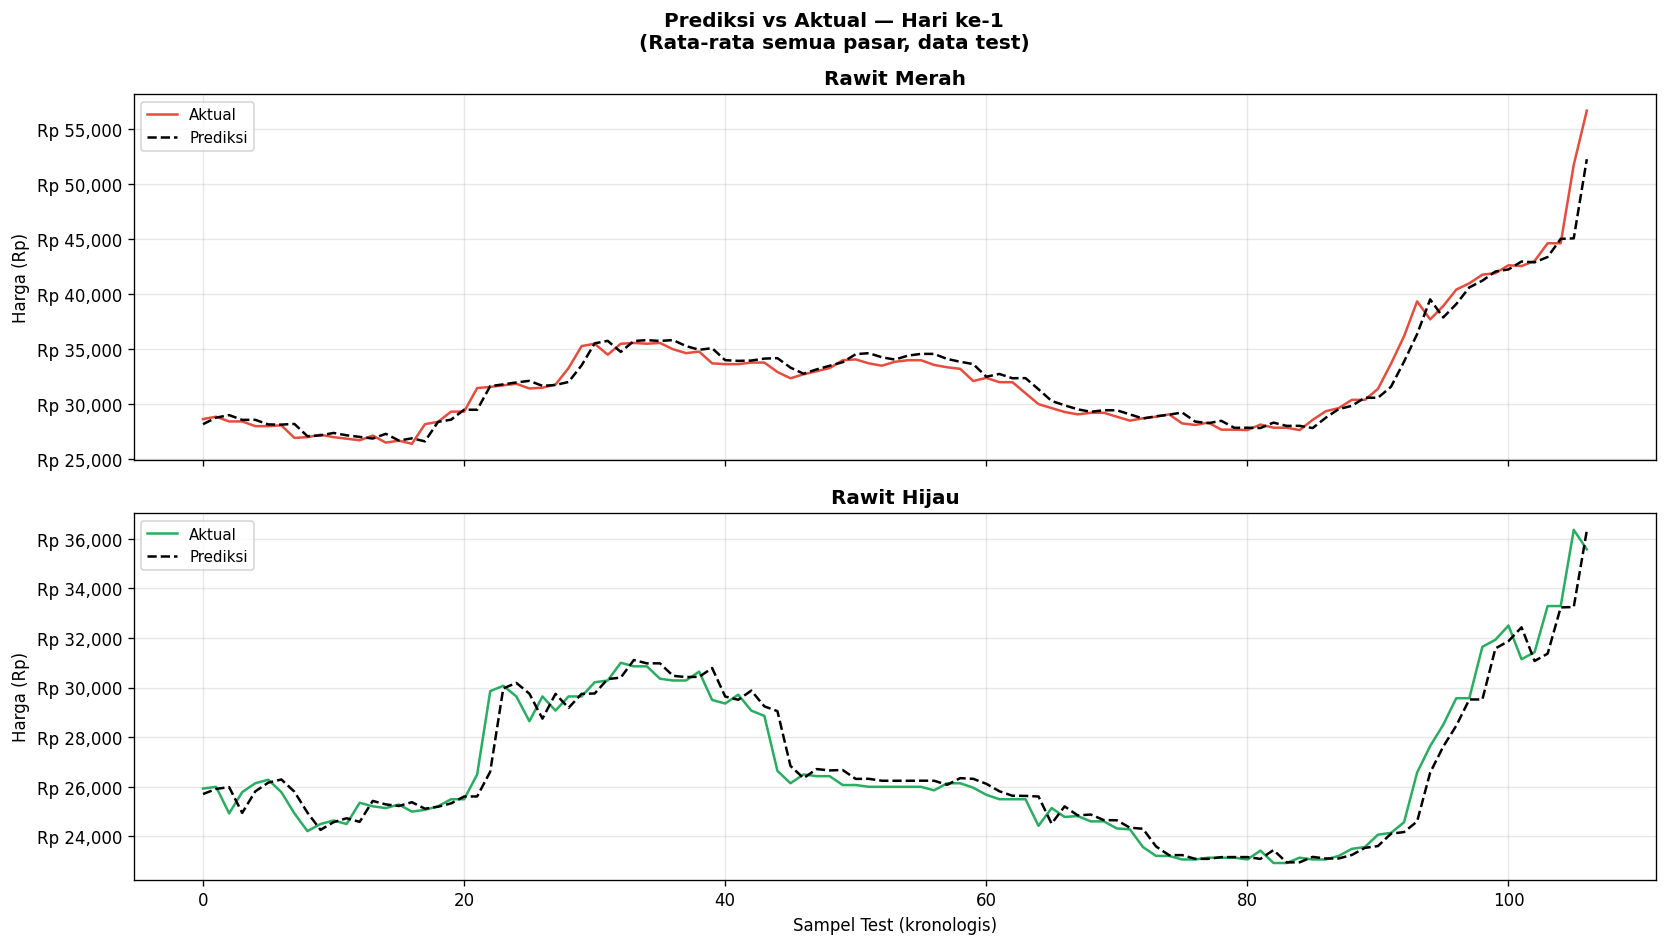

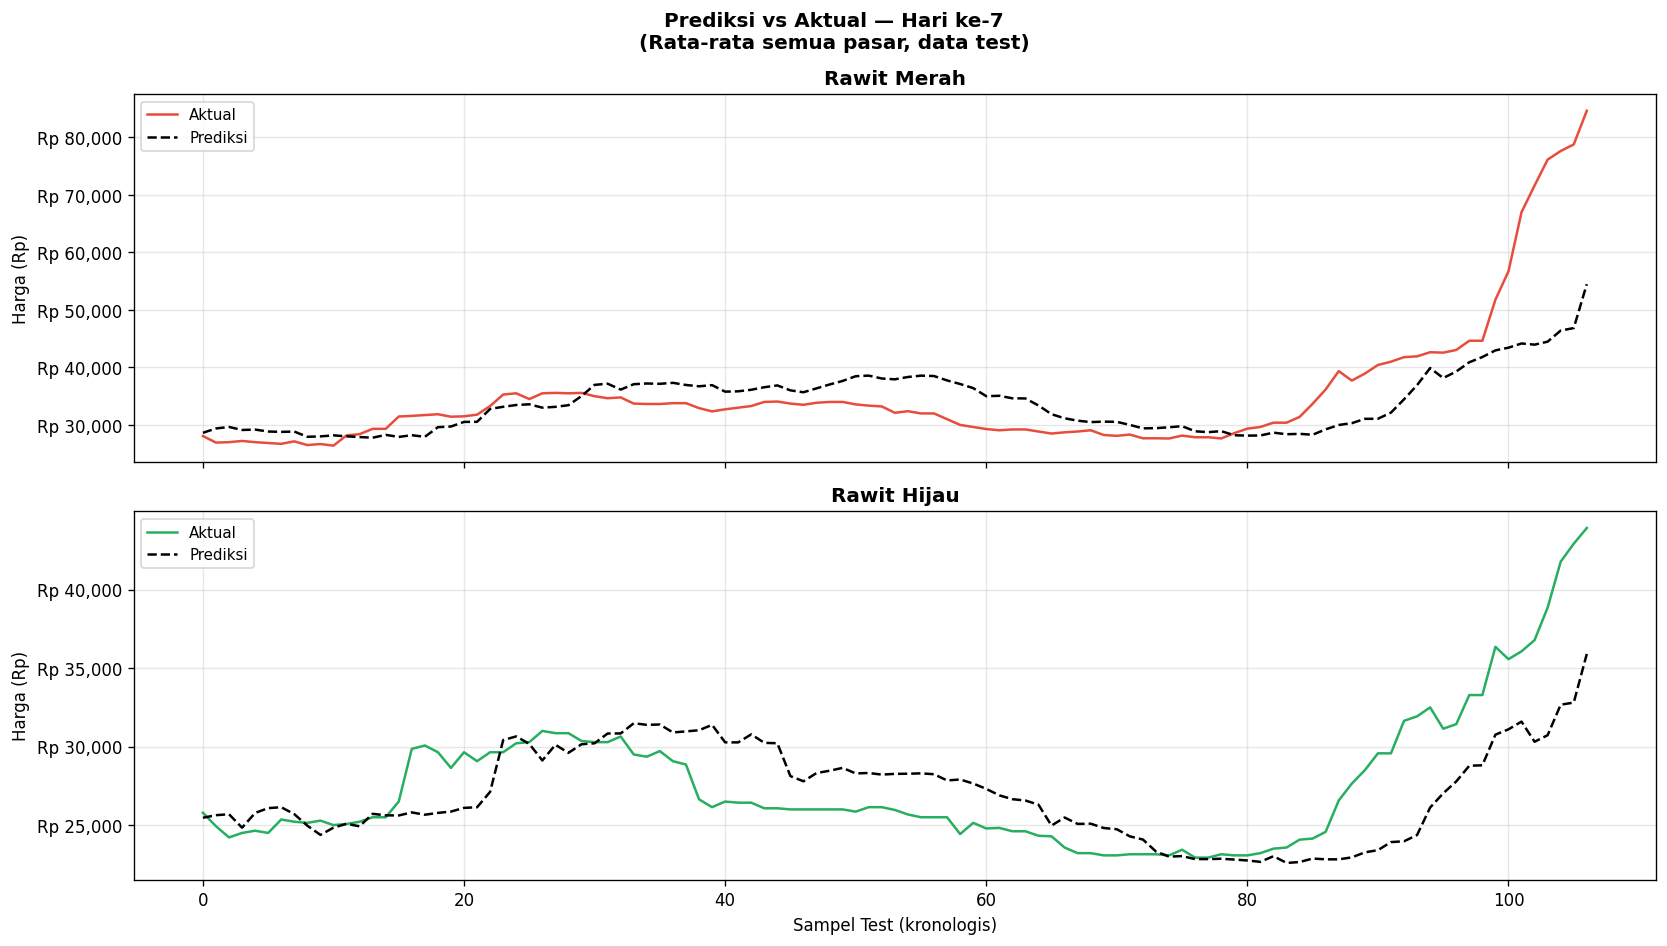

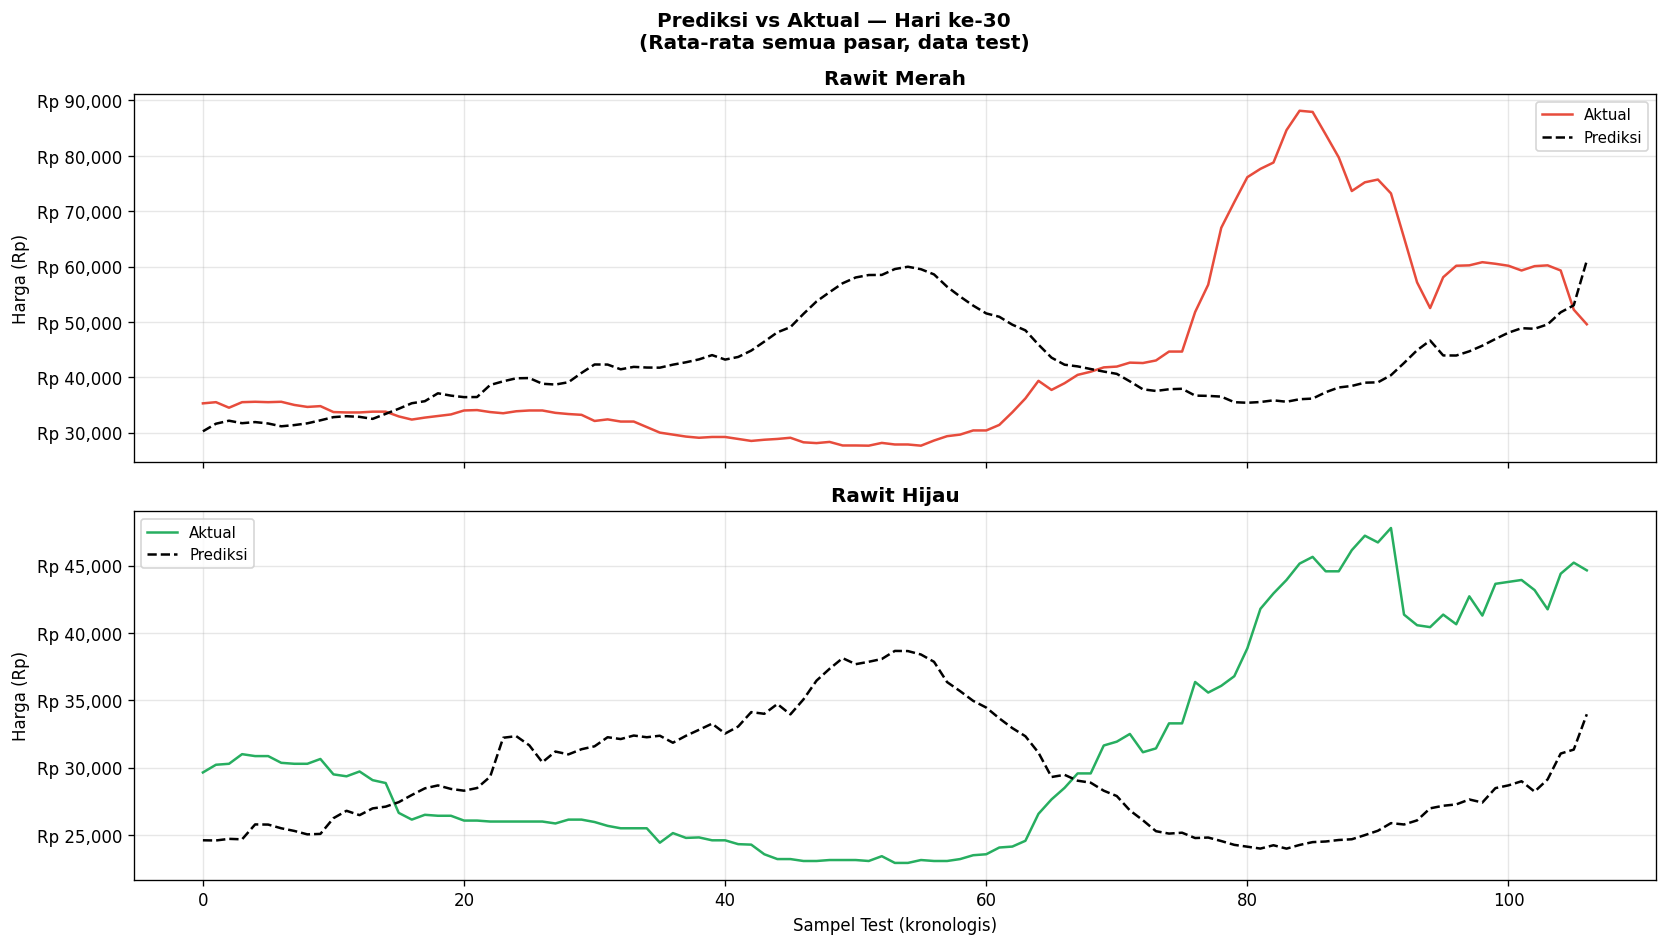

In [477]:
for h_idx, h_label in [(0,'Hari ke-1'),(6,'Hari ke-7'),(29,'Hari ke-30')]:
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    fig.suptitle(f'Prediksi vs Aktual — {h_label}\n'
                f'(Rata-rata semua pasar, data test)', fontweight='bold')
    for ax, yr, pr, label, warna in zip(
        axes,
        [y_m_rp[:,h_idx,:], y_h_rp[:,h_idx,:]],
        [pred_m_rp[:,h_idx,:], pred_h_rp[:,h_idx,:]],
        ['Rawit Merah','Rawit Hijau'], ['#e74c3c','#27ae60']
    ):
        ax.plot(yr.mean(axis=1),  color=warna,   lw=1.5, label='Aktual')
        ax.plot(pr.mean(axis=1),  color='black',  lw=1.5, ls='--', label='Prediksi')
        ax.set_title(label); ax.set_ylabel('Harga (Rp)')
        ax.yaxis.set_major_formatter(
            mticker.FuncFormatter(lambda v,_: f'Rp {v:,.0f}'))
        ax.legend(fontsize=9)
    axes[1].set_xlabel('Sampel Test (kronologis)')
    
    plt.tight_layout()
    plt.savefig(f'outputs_r2/pred_{h_label.replace(" ","_")}.png', bbox_inches='tight')
    plt.show()

In [478]:
# ===== Cek periode uji + persentase data ASLI (REVISI 2) =====
tgl_series = pd.to_datetime(daftar_tanggal)
awal_target, akhir_target = tgl_series[n_samp_val + LOOKBACK], tgl_series[-1]
print('Input sampel uji pertama mulai :', tgl_series[n_samp_val].date())
print('Periode TARGET uji             :', awal_target.date(), 's/d', akhir_target.date())
print('Total sampel uji               :', len(X_test))

uji = df_lengkap[(df_lengkap['tanggal'] >= awal_target) & (df_lengkap['tanggal'] <= akhir_target)]
print(f"Baris harga di periode target : {len(uji):,} ({uji['tanggal'].nunique()} hari x {uji['nama_pasar'].nunique()} pasar)")
print(f"Data ASLI (bukan forward fill): merah {uji['is_observed_merah'].mean()*100:.1f}% | "
      f"hijau {uji['is_observed_hijau'].mean()*100:.1f}%")

Input sampel uji pertama mulai : 2025-08-04
Periode TARGET uji             : 2025-08-18 s/d 2025-12-31
Total sampel uji               : 107
Baris harga di periode target : 1,904 (136 hari x 14 pasar)
Data ASLI (bukan forward fill): merah 97.2% | hijau 97.0%


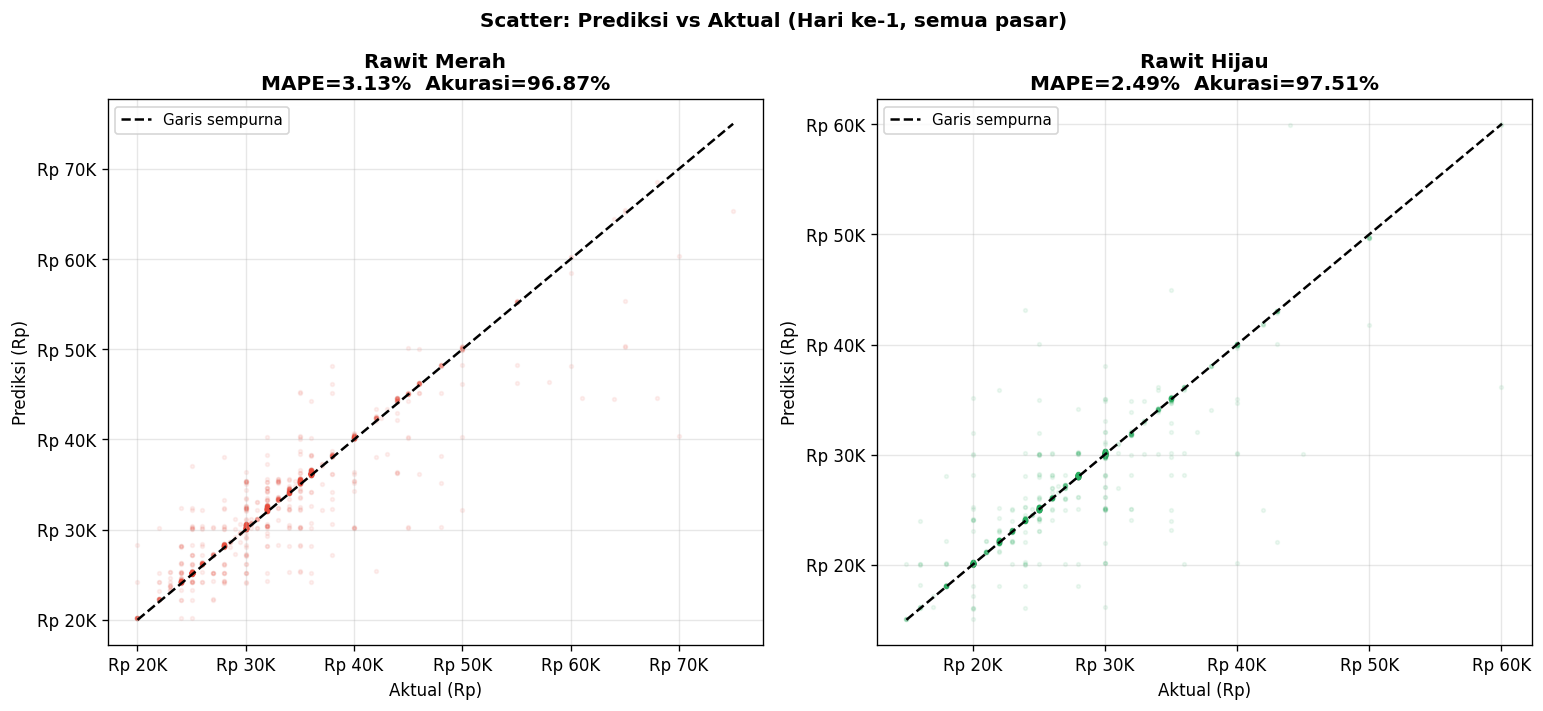

In [479]:
# Scatter Plot

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
fig.suptitle('Scatter: Prediksi vs Aktual (Hari ke-1, semua pasar)', fontweight='bold')

mape_scatter_m = mape(y_m_rp[:,0,:], pred_m_rp[:,0,:])
mape_scatter_h = mape(y_h_rp[:,0,:], pred_h_rp[:,0,:])

for ax, yr, pr, label, warna, mp in zip(
    axes,
    [y_m_rp[:,0,:], y_h_rp[:,0,:]],
    [pred_m_rp[:,0,:], pred_h_rp[:,0,:]],
    ['Rawit Merah','Rawit Hijau'], ['#e74c3c','#27ae60'],
    [mape_scatter_m, mape_scatter_h]
):
    yf, pf = yr.flatten(), pr.flatten()
    ax.scatter(yf, pf, alpha=0.08, s=5, color=warna)
    lim = [min(yf.min(),pf.min()), max(yf.max(),pf.max())]
    ax.plot(lim, lim, 'k--', lw=1.5, label='Garis sempurna')
    ax.set_title(f'{label}\nMAPE={mp:.2f}%  Akurasi={max(0,100-mp):.2f}%')
    ax.set_xlabel('Aktual (Rp)'); ax.set_ylabel('Prediksi (Rp)')
    for axis in [ax.xaxis, ax.yaxis]:
        axis.set_major_formatter(
            mticker.FuncFormatter(lambda v,_: f'Rp {v/1000:.0f}K'))
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('outputs_r2/scatter_pred.png', bbox_inches='tight')
plt.show()

### MAPE Training vs Testing

In [480]:
# MAPE training vs testing menggunakan prediksi ensemble yang sudah ada
y_tr_np = y_train_t.cpu().numpy()

ptr_m = inverse_tr(pred_train_np[:,:,:,0], scaler_m)
ptr_h = inverse_tr(pred_train_np[:,:,:,1], scaler_h)
ytr_m = inverse_tr(y_tr_np[:,:,:,0],      scaler_m)
ytr_h = inverse_tr(y_tr_np[:,:,:,1],      scaler_h)

mtr_m = mape(ytr_m, ptr_m)
mtr_h = mape(ytr_h, ptr_h)
sel_m = abs(mape_m - mtr_m)
sel_h = abs(mape_h - mtr_h)

print('=' * 58)
print('  MAPE TRAINING vs TESTING')
print('=' * 58)
print(f'  {"":22} {"Rawit Merah":>14} {"Rawit Hijau":>14}')
print('  ' + '-' * 55)
print(f'  {"MAPE Training":22} {mtr_m:>12.2f}%  {mtr_h:>12.2f}%')
print(f'  {"MAPE Testing":22} {mape_m:>12.2f}%  {mape_h:>12.2f}%')
print('  ' + '-' * 55)
print(f'  {"Selisih":22} {sel_m:>12.2f}%  {sel_h:>12.2f}%')
print('=' * 58)
status = 'SEHAT — selisih kecil' if max(sel_m,sel_h) < 5  else \
         'SEDANG — masih dapat diterima'        if max(sel_m,sel_h) < 10 else \
         'PERHATIAN — selisih cukup besar'
print(f'  Status: {status}')

# REVISI 2: angka GABUNGAN (rata-rata merah & hijau) untuk paper
mtr_avg, mte_avg = (mtr_m + mtr_h) / 2, (mape_m + mape_h) / 2
print()
print(f'  GABUNGAN -> MAPE training {mtr_avg:.2f}% | MAPE testing {mte_avg:.2f}% | selisih {mte_avg - mtr_avg:.2f}%')

  MAPE TRAINING vs TESTING
                            Rawit Merah    Rawit Hijau
  -------------------------------------------------------
  MAPE Training                 14.48%         12.31%
  MAPE Testing                  25.46%         20.59%
  -------------------------------------------------------
  Selisih                       10.98%          8.28%
  Status: PERHATIAN — selisih cukup besar

  GABUNGAN -> MAPE training 13.40% | MAPE testing 23.03% | selisih 9.63%


### Download File

In [481]:
import os
os.makedirs('model_r2', exist_ok=True)
np.save('model_r2/pred_m_rp.npy', pred_m_rp)
np.save('model_r2/pred_h_rp.npy', pred_h_rp)
np.save('model_r2/y_m_rp.npy', y_m_rp)
np.save('model_r2/y_h_rp.npy', y_h_rp)
np.save('model_r2/history_train.npy', history_train)
np.save('model_r2/history_val.npy', history_val)
np.save('model_r2/best_epoch.npy', [best_epoch])
np.save('model_r2/daftar_pasar.npy', daftar_pasar)
np.save('model_r2/daftar_tanggal.npy', daftar_tanggal)
np.save('model_r2/adj_matrix.npy', adj_norm)
np.save('model_r2/tensor_data.npy', X_all)

import pickle
with open('model_r2/scaler_m.pkl','wb') as f: pickle.dump(scaler_m, f)
with open('model_r2/scaler_h.pkl','wb') as f: pickle.dump(scaler_h, f)
torch.save(best_state_dict, 'model_r2/model_best.pt')
print("Semua file model tersimpan di folder model_r2/")

Semua file model tersimpan di folder model_r2/


## Analisis Distribusi Shift pada Pasar Bermasalah

Tiga pasar menunjukkan MAPE yang sangat tinggi dibandingkan pasar lainnya:
KEMUKUSAN, PROLIMAN, SOKARAJA (angka terbaru: lihat tabel MAPE per pasar di atas).

> **CATATAN REVISI 2:** daftar 6 pasar di bawah dipertahankan agar Tabel IV paper tetap bisa direproduksi. Tabel distribusi ini **tidak bergantung pada model**; yang bergantung pada model hanya kolom MAPE. Kesimpulan di akhir bagian ini sudah dibuat netral.

Analisis ini menginvestigasi penyebab tingginya error pada ketiga pasar tersebut
dengan membandingkan distribusi harga pada periode training dan testing.

### Grafik Investigasi 3 Pasar

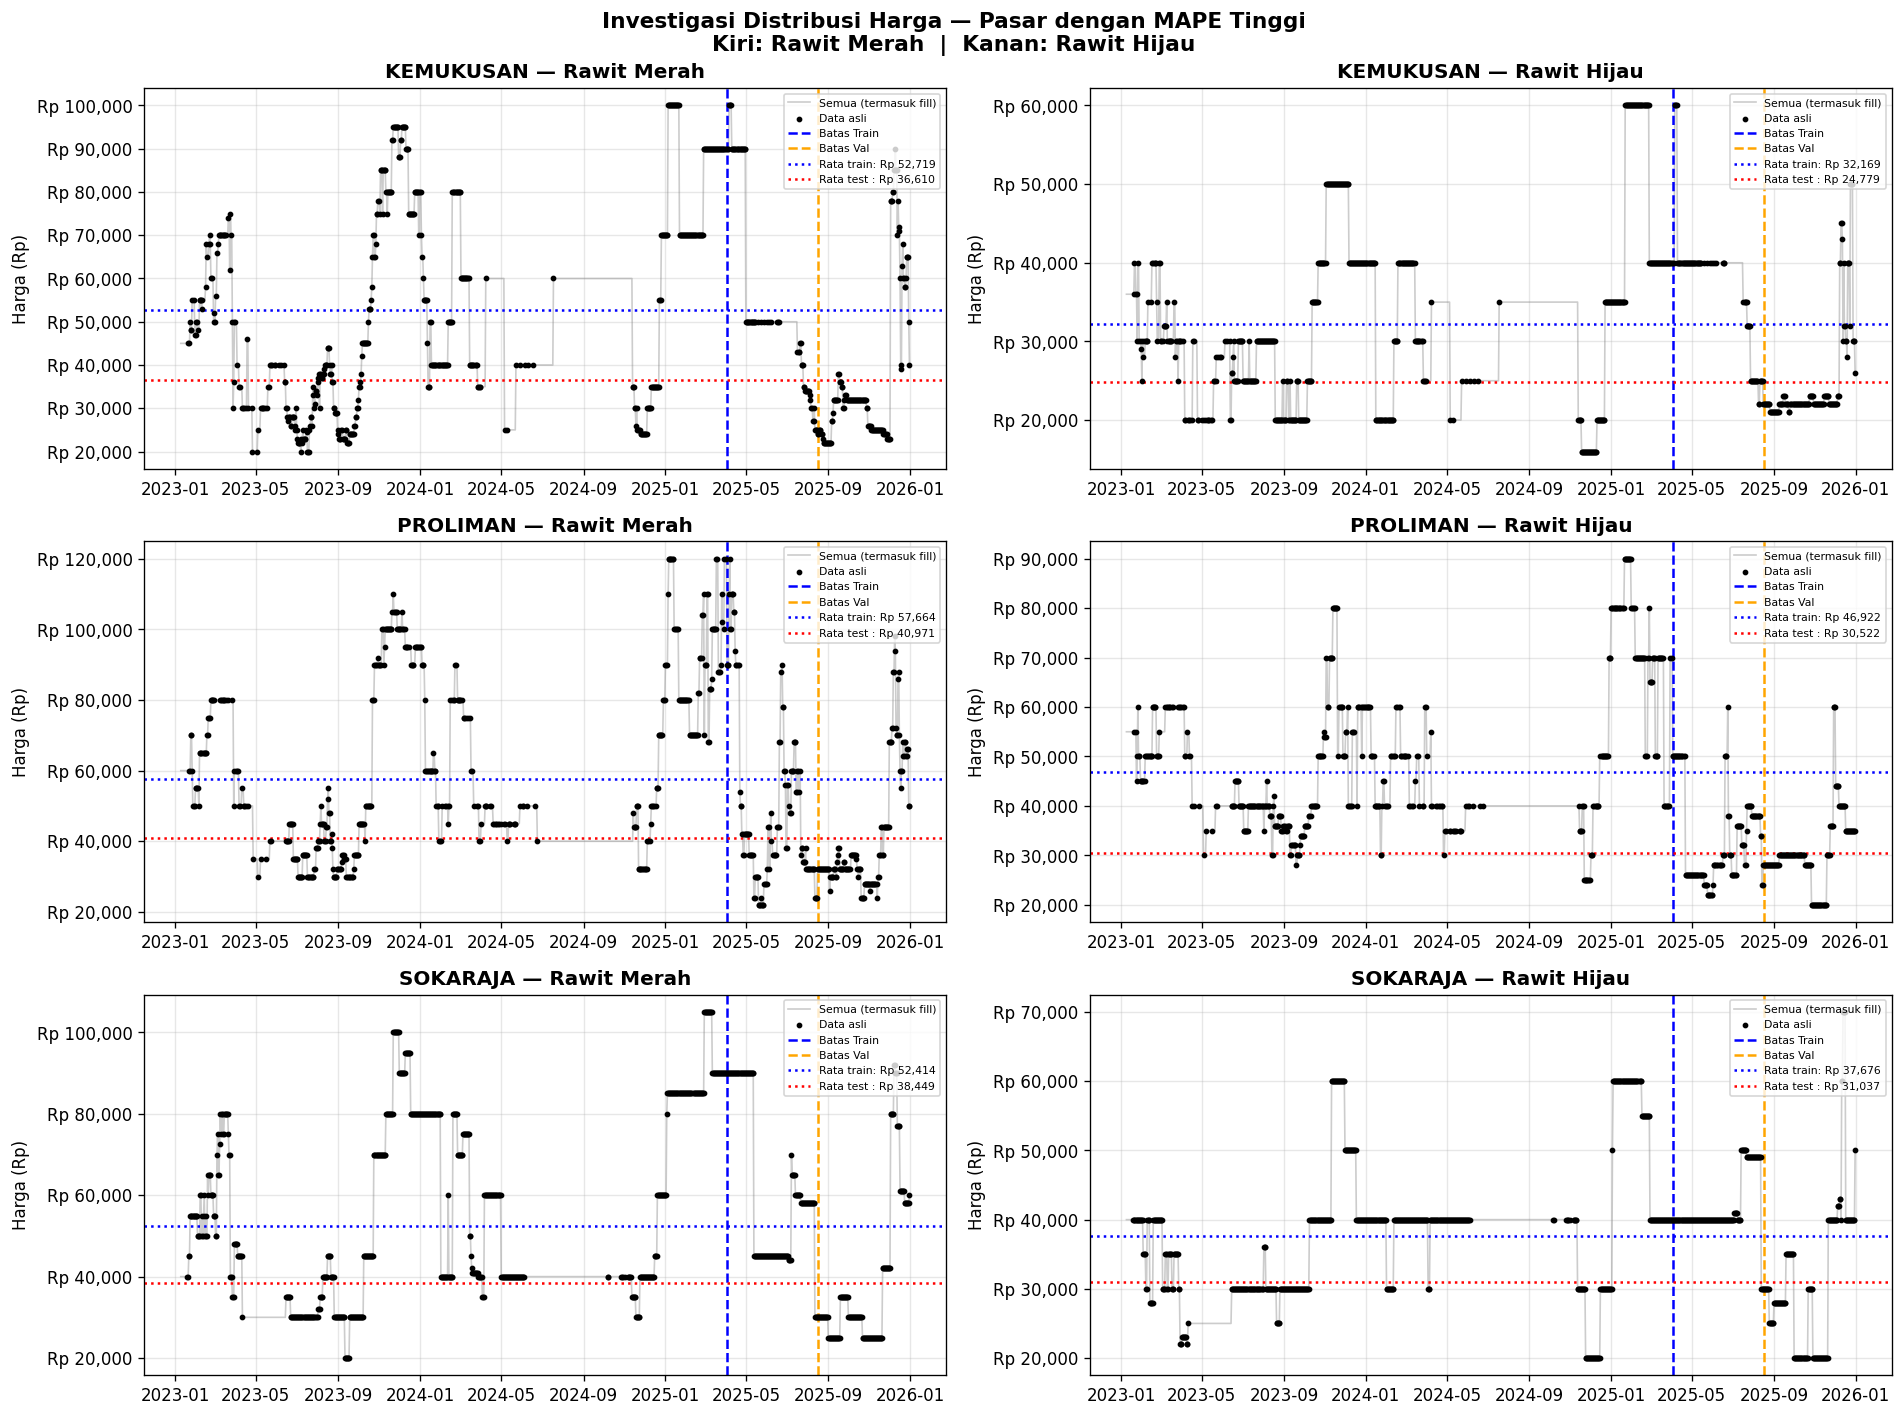

In [482]:
# Investigasi visual distribusi harga 3 pasar bermasalah
pasar_masalah = ['KEMUKUSAN', 'PROLIMAN', 'SOKARAJA']

fig, axes = plt.subplots(len(pasar_masalah), 2, figsize=(16, 12))
fig.suptitle('Investigasi Distribusi Harga — Pasar dengan MAPE Tinggi\n'
            'Kiri: Rawit Merah  |  Kanan: Rawit Hijau', fontweight='bold', fontsize=13)

for idx, pasar in enumerate(pasar_masalah):
    for col, (kolom, label) in enumerate([
        ('harga_rawit_merah', 'Rawit Merah'),
        ('harga_rawit_hijau', 'Rawit Hijau')
    ]):
        ax   = axes[idx, col]
        data = df_lengkap[df_lengkap['nama_pasar'] == pasar].copy()
        jenis = kolom.split('_')[2]
        obs  = data[data[f'is_observed_{jenis}'] == 1]

        # Plot semua data
        ax.plot(data['tanggal'], data[kolom],
                lw=1, alpha=0.4, color='gray', label='Semua (termasuk fill)')
        # Plot data asli
        ax.scatter(obs['tanggal'], obs[kolom], s=6, color='black', zorder=5, label='Data asli')
        # Garis batas
        ax.axvline(tgl_train_end, color='blue',   ls='--', lw=1.5, label='Batas Train')
        ax.axvline(tgl_val_end,   color='orange', ls='--', lw=1.5, label='Batas Val')
        # Rata-rata train vs test
        mean_train = data[data['tanggal'] <= tgl_train_end][kolom].mean()
        mean_test  = data[data['tanggal'] >  tgl_val_end][kolom].mean()
        ax.axhline(mean_train, color='blue', ls=':', lw=1.5, label=f'Rata train: Rp {mean_train:,.0f}')
        ax.axhline(mean_test,  color='red',  ls=':', lw=1.5, label=f'Rata test : Rp {mean_test:,.0f}')

        ax.set_title(f'{pasar} — {label}', fontweight='bold')
        ax.set_ylabel('Harga (Rp)')
        ax.yaxis.set_major_formatter(
            mticker.FuncFormatter(lambda v,_: f'Rp {v:,.0f}'))
        ax.legend(fontsize=6.5, loc='upper right')

plt.tight_layout()
plt.savefig('outputs_r2/investigasi_distribusi_shift.png', dpi=300, bbox_inches='tight')
plt.show()

### Tabel Perbandingan Distribusi

In [483]:
# Tabel perbandingan distribusi train vs test
pasar_bagus = ['SARIMULYO', 'TAMBAK', 'MANIS']
semua_pasar = pasar_masalah + pasar_bagus

hasil_dist = []
for pasar in semua_pasar:
    data    = df_lengkap[df_lengkap['nama_pasar'] == pasar]
    train_m = data[data['tanggal'] <= tgl_train_end]['harga_rawit_merah']
    test_m  = data[data['tanggal'] >  tgl_val_end]['harga_rawit_merah']

    hasil_dist.append({
        'Pasar'           : pasar,
        'Kategori'        : 'Bermasalah' if pasar in pasar_masalah else 'Stabil',
        'Rata Train (Rp)' : round(train_m.mean()),
        'Rata Test (Rp)'  : round(test_m.mean()),
        'Selisih (Rp)'    : round(abs(test_m.mean() - train_m.mean())),
    })

df_dist = pd.DataFrame(hasil_dist)
print('PERBANDINGAN DISTRIBUSI HARGA RAWIT MERAH: TRAIN vs TEST')
print('Keterangan: Selisih besar = harga di test period sangat berbeda dari training')
display(df_dist)

PERBANDINGAN DISTRIBUSI HARGA RAWIT MERAH: TRAIN vs TEST
Keterangan: Selisih besar = harga di test period sangat berbeda dari training


,Pasar,Kategori,Rata Train (Rp),Rata Test (Rp),Selisih (Rp)
0,KEMUKUSAN,Bermasalah,52719,36610,16108
1,PROLIMAN,Bermasalah,57664,40971,16694
2,SOKARAJA,Bermasalah,52414,38449,13965
3,SARIMULYO,Stabil,50439,43169,7270
4,TAMBAK,Stabil,49708,44824,4884
5,MANIS,Stabil,49562,42074,7489


### Kesimpulan Distribusi Shift

In [484]:
# Ringkasan temuan distribusi shift
print('=' * 60)
print('  RINGKASAN DISTRIBUSI SHIFT')
print('=' * 60)

for pasar in pasar_masalah:
    row = df_dist[df_dist['Pasar'] == pasar].iloc[0]
    idx = daftar_pasar.index(pasar)
    mp  = df_pasar[df_pasar['Pasar'] == pasar]['Rata-rata (%)'].values[0]
    print(f'\n  {pasar}')
    print(f'    Rata-rata training : Rp {row["Rata Train (Rp)"]:,}')
    print(f'    Rata-rata testing  : Rp {row["Rata Test (Rp)"]:,}')
    print(f'    Selisih            : Rp {row["Selisih (Rp)"]:,}')
    print(f'    MAPE (rata-rata)   : {mp:.2f}%')

print()
print('  Pasar stabil sebagai pembanding:')
for pasar in pasar_bagus:
    row = df_dist[df_dist['Pasar'] == pasar].iloc[0]
    mp  = df_pasar[df_pasar['Pasar'] == pasar]['Rata-rata (%)'].values[0]
    print(f'    {pasar:<12} selisih Rp {row["Selisih (Rp)"]:,}  '
          f'MAPE {mp:.2f}%')

print()
print('  KESIMPULAN:')
# REVISI 2: kesimpulan netral (klaim lama "bukan kegagalan model" tidak didukung data)
print('  Perubahan rata-rata harga train -> test (distribution shift) adalah SALAH SATU')
print('  faktor tingginya error. Faktor lain: pola musiman yang tidak berulang antar tahun')
print('  (lihat STEP 13.5) dan perbandingan dengan naive persistence (STEP 13).')
print('=' * 60)

  RINGKASAN DISTRIBUSI SHIFT

  KEMUKUSAN
    Rata-rata training : Rp 52,719
    Rata-rata testing  : Rp 36,610
    Selisih            : Rp 16,108
    MAPE (rata-rata)   : 22.98%

  PROLIMAN
    Rata-rata training : Rp 57,664
    Rata-rata testing  : Rp 40,971
    Selisih            : Rp 16,694
    MAPE (rata-rata)   : 26.06%

  SOKARAJA
    Rata-rata training : Rp 52,414
    Rata-rata testing  : Rp 38,449
    Selisih            : Rp 13,965
    MAPE (rata-rata)   : 28.66%

  Pasar stabil sebagai pembanding:
    SARIMULYO    selisih Rp 7,270  MAPE 19.44%
    TAMBAK       selisih Rp 4,884  MAPE 13.11%
    MANIS        selisih Rp 7,489  MAPE 21.86%

  KESIMPULAN:
  Perubahan rata-rata harga train -> test (distribution shift) adalah SALAH SATU
  faktor tingginya error. Faktor lain: pola musiman yang tidak berulang antar tahun
  (lihat STEP 13.5) dan perbandingan dengan naive persistence (STEP 13).


## STEP 13: Pembanding (Baseline) & Uji Statistik
**Urutan menjalankan:** jalankan dulu notebook **versi jarak REVISI 2** sampai selesai (menghasilkan `C:/prediksi-cabai-banyumas-jarak/outputs_jarak_r2/ringkasan_jarak.json`), baru notebook ini.

1. **Naive persistence**: prediksi 30 hari ke depan = harga hari terakhir yang diketahui (tidak dilatih).
2. **GRU-only (ablasi)**: arsitektur & seed sama persis, tetapi adjacency diganti matriks nol, sehingga jalur tetangga mati dan model hanya memakai harga pasar itu sendiri.
3. **Tabel perbandingan** semua model.
4. **Paired t-test** pada MAPE 5 seed (berpasangan per seed)

### 13.1 Naive Persistence

In [485]:
# ===== 13.1 NAIVE PERSISTENCE =====
# Harga 30 hari ke depan = harga hari terakhir di jendela input (hari ke-14)

raw_m = scaler_m.transform(pivot_all_m.values)    # tanpa clip
raw_h = scaler_h.transform(pivot_all_h.values)
idx_last = n_samp_val + LOOKBACK - 1
last = np.stack([np.stack([raw_m[idx_last+i], raw_h[idx_last+i]], -1) for i in range(len(X_test))])
pred_persist = np.repeat(last[:, None], HORIZON, axis=1)  # (sampel uji, 30, 14, 2)
ringkasan_persist = ringkas_prediksi(pred_persist)
print(f"Naive persistence -> MAPE rata-rata {ringkasan_persist['MAPE Rata2']:.2f}% | H1 {ringkasan_persist['MAPE H1']:.2f}%")

Naive persistence -> MAPE rata-rata 16.71% | H1 2.28%


### 13.2 GRU-only (ablasi tanpa graph)

In [486]:
# ===== 13.2 GRU-ONLY (ST-GCN TANPA GRAPH = ABLASI) =====
# Arsitektur, hyperparameter & seed SAMA PERSIS dengan ST-GCN.
# Bedanya hanya adjacency = matriks nol -> jalur tetangga tidak menerima informasi apa pun.
adj_nol = torch.zeros_like(adj_t)
semua_pred_gru = []
for seed in SEEDS_ENSEMBLE:
    p_g, bv_g, h_tr_g, _, _ = train_model(X_train_t, y_train_t, X_val_t, y_val_t,
                                          adj_nol, seed=seed, verbose=True)
    semua_pred_gru.append(p_g)
    print(f'  [GRU-only] Seed {seed:>3} | val loss: {bv_g:.6f} | epochs: {len(h_tr_g)}')

pred_gru = np.mean(semua_pred_gru, axis=0)
ringkasan_gru = ringkas_prediksi(pred_gru)
ringkasan_gru['per_seed'] = {str(s): ringkas_prediksi(p)['MAPE Rata2']
                             for s, p in zip(SEEDS_ENSEMBLE, semua_pred_gru)}
with open('outputs_r2/ringkasan_gru_only.json', 'w') as f:
    json.dump(ringkasan_gru, f, indent=2, default=float)
print(f"\nGRU-only -> MAPE rata-rata {ringkasan_gru['MAPE Rata2']:.2f}% | "
      f"H1 {ringkasan_gru['MAPE H1']:.2f}% | H30 {ringkasan_gru['MAPE H30']:.2f}%")

  Early stop epoch 62
  [GRU-only] Seed  10 | val loss: 0.007566 | epochs: 62
  Early stop epoch 58
  [GRU-only] Seed   1 | val loss: 0.007618 | epochs: 58
  Early stop epoch 70
  [GRU-only] Seed   3 | val loss: 0.007607 | epochs: 70
  Early stop epoch 54
  [GRU-only] Seed  42 | val loss: 0.007499 | epochs: 54
  Early stop epoch 39
  [GRU-only] Seed   7 | val loss: 0.007755 | epochs: 39

GRU-only -> MAPE rata-rata 22.39% | H1 2.70% | H30 35.50%


### 13.3 Tabel Perbandingan

In [487]:
# ===== 13.3 TABEL PERBANDINGAN =====
FILE_JARAK = 'C:/prediksi-cabai-banyumas-jarak/outputs_jarak_r2/ringkasan_jarak.json'   # REVISI 2
baris = {'Naive persistence': ringkasan_persist,
         'GRU-only (tanpa graph)': ringkasan_gru}
if os.path.exists(FILE_JARAK):
    ringkasan_jarak = json.load(open(FILE_JARAK))
    baris['ST-GCN (graph jarak geografis)'] = ringkasan_jarak
else:
    ringkasan_jarak = None
    print('PERINGATAN: file ringkasan jarak belum ada -> jalankan notebook versi jarak dulu.')
baris['ST-GCN (graph korelasi harga)'] = ringkasan

kolom = ['MAPE H1', 'MAPE H7', 'MAPE H14', 'MAPE H21', 'MAPE H30',
         'MAPE Merah', 'MAPE Hijau', 'MAPE Rata2',
         'MAE Merah', 'MAE Hijau', 'RMSE Merah', 'RMSE Hijau', 'R2 Merah', 'R2 Hijau']
df_banding = pd.DataFrame({k: {c: v[c] for c in kolom} for k, v in baris.items()}).T.round(2)
print('TABEL PERBANDINGAN MODEL (data uji, MAPE dalam %, MAE/RMSE dalam Rp)')
display(df_banding)
df_banding.to_excel('outputs_r2/tabel_perbandingan_baseline.xlsx')

# MAPE per pasar: ST-GCN korelasi vs persistence (bahan pembahasan distribution shift)
df_pasar_banding = pd.DataFrame({
    'ST-GCN korelasi': ringkasan['MAPE per pasar'],
    'GRU-only'       : ringkasan_gru['MAPE per pasar'],
    'Persistence'    : ringkasan_persist['MAPE per pasar']}).round(2).sort_values('ST-GCN korelasi')
print('\nMAPE PER PASAR (rata-rata merah & hijau, %)')
display(df_pasar_banding)
df_pasar_banding.to_excel('outputs_r2/tabel_mape_per_pasar_banding.xlsx')

TABEL PERBANDINGAN MODEL (data uji, MAPE dalam %, MAE/RMSE dalam Rp)


,MAPE H1,MAPE H7,MAPE H14,MAPE H21,MAPE H30,MAPE Merah,MAPE Hijau,MAPE Rata2,MAE Merah,MAE Hijau,RMSE Merah,RMSE Hijau,R2 Merah,R2 Hijau
Naive persistence,2.28,10.61,17.03,21.51,25.45,18.07,15.36,16.71,8888.75,5023.72,15924.22,8280.33,-0.02,-0.19
GRU-only (tanpa graph),2.70,13.04,22.17,29.65,35.50,24.94,19.85,22.39,9892.13,5845.18,14468.34,8212.67,0.16,-0.18
ST-GCN (graph jarak geografis),2.55,12.63,22.24,30.04,36.12,24.97,20.10,22.54,10239.55,6128.02,15650.62,8899.21,0.01,-0.42
ST-GCN (graph korelasi harga),2.81,12.90,22.74,30.74,36.59,25.46,20.59,23.03,10393.92,6278.24,15852.38,9144.31,-0.01,-0.50



MAPE PER PASAR (rata-rata merah & hijau, %)


,ST-GCN korelasi,GRU-only,Persistence
WANGON,12.73,13.08,9.10
TAMBAK,13.11,12.32,5.51
SARIMULYO,19.44,17.79,14.67
BANYUMAS,20.96,20.01,15.54
SUMPIUH,21.65,20.40,16.56
MANIS,21.86,20.76,19.11
KEMUKUSAN,22.98,24.85,12.41
WIJAHAN,24.73,23.12,18.86
LARANGAN,24.94,24.02,18.61
PROLIMAN,26.06,29.13,17.51


### 13.4 Paired t-test

In [488]:
# ===== 13.4 PAIRED T-TEST (MAPE 5 seed, berpasangan per seed) =====
from scipy import stats

def uji_t(nama_a, seed_a, nama_b, seed_b):
    a = np.array([seed_a[str(s)] for s in SEEDS_ENSEMBLE])
    b = np.array([seed_b[str(s)] for s in SEEDS_ENSEMBLE])
    t, p = stats.ttest_rel(a, b)
    print(f'{nama_a} vs {nama_b}')
    print(f'   {nama_a:<10}: {a.mean():.2f}% +/- {a.std(ddof=1):.2f}   per seed {np.round(a, 2)}')
    print(f'   {nama_b:<10}: {b.mean():.2f}% +/- {b.std(ddof=1):.2f}   per seed {np.round(b, 2)}')
    print(f'   Selisih rata-rata: {(a - b).mean():+.2f} poin | t = {t:.3f} | p = {p:.4f} -> '
          + ('BERBEDA NYATA (p < 0,05)' if p < 0.05 else 'belum terbukti berbeda (p >= 0,05)'))
    print()
    return t, p

hasil_uji = {}
hasil_uji['korelasi_vs_gru'] = uji_t('Korelasi', ringkasan['per_seed'], 'GRU-only', ringkasan_gru['per_seed'])
if ringkasan_jarak is not None:
    hasil_uji['korelasi_vs_jarak'] = uji_t('Korelasi', ringkasan['per_seed'], 'Jarak', ringkasan_jarak['per_seed'])

Korelasi vs GRU-only
   Korelasi  : 24.37% +/- 3.36   per seed [22.19 21.26 27.84 22.38 28.2 ]
   GRU-only  : 23.00% +/- 2.47   per seed [21.24 26.12 21.24 25.26 21.14]
   Selisih rata-rata: +1.37 poin | t = 0.567 | p = 0.6007 -> belum terbukti berbeda (p >= 0,05)

Korelasi vs Jarak
   Korelasi  : 24.37% +/- 3.36   per seed [22.19 21.26 27.84 22.38 28.2 ]
   Jarak     : 23.78% +/- 2.65   per seed [21.05 21.95 27.76 23.3  24.86]
   Selisih rata-rata: +0.59 poin | t = 0.760 | p = 0.4896 -> belum terbukti berbeda (p >= 0,05)



### 13.5 ONE-SAMPLE T-TEST TERHADAP NAIVE PERSISTENCE

In [489]:
# ===== 13.5 ONE-SAMPLE T-TEST TERHADAP NAIVE PERSISTENCE =====
from scipy import stats
mape_persist = ringkasan_persist['MAPE Rata2']
daftar_uji = [('ST-GCN korelasi', ringkasan), ('GRU tanpa graf', ringkasan_gru)]
if ringkasan_jarak is not None:
    daftar_uji.append(('ST-GCN jarak', ringkasan_jarak))
print(f'MAPE naive persistence (tetap): {mape_persist:.2f}%\n')
for nama_m, r in daftar_uji:
    a = np.array([r['per_seed'][str(s)] for s in SEEDS_ENSEMBLE])
    t, p = stats.ttest_1samp(a, mape_persist)
    print(f'{nama_m:<16}: {a.mean():.2f}% +/- {a.std(ddof=1):.2f} | t = {t:.3f} | p = {p:.4f}')

MAPE naive persistence (tetap): 16.71%

ST-GCN korelasi : 24.37% +/- 3.36 | t = 5.105 | p = 0.0070
GRU tanpa graf  : 23.00% +/- 2.47 | t = 5.688 | p = 0.0047
ST-GCN jarak    : 23.78% +/- 2.65 | t = 5.979 | p = 0.0039


### 13.6 FIGUR: POLA MUSIMAN & TEBAKAN HARI KE-30

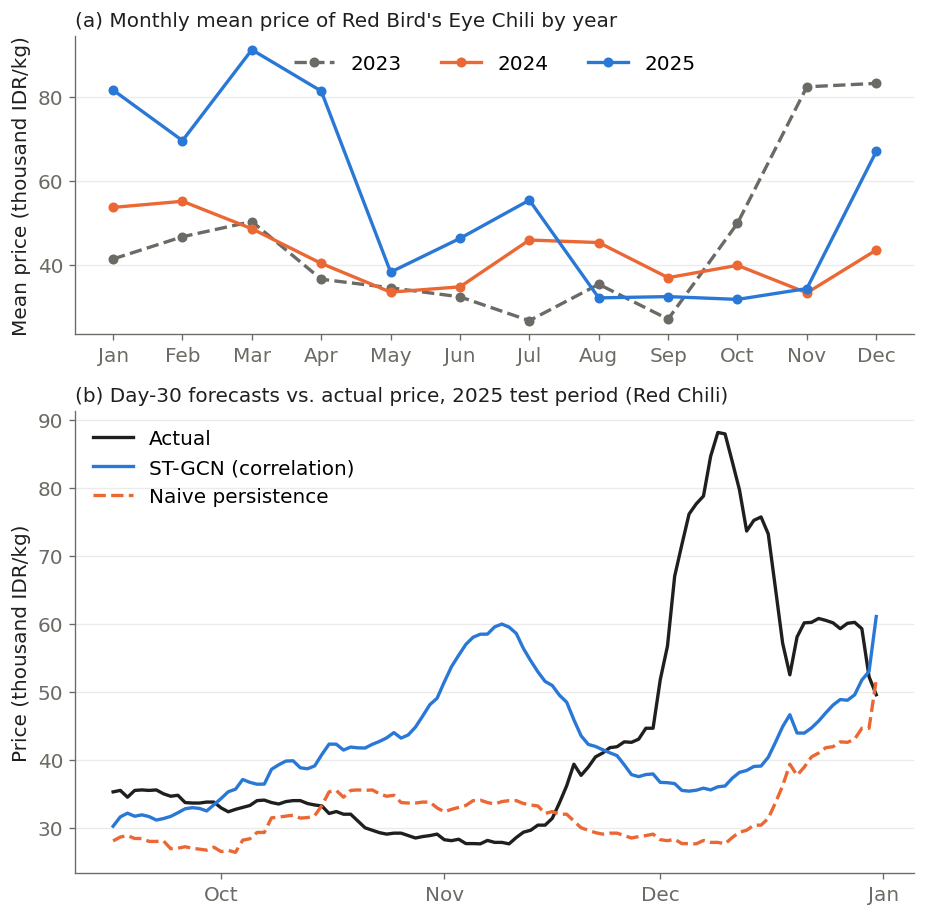

Tersimpan: outputs_r2/fig_pola_musiman_h30.png


In [490]:
# ===== 13.6 FIGUR: POLA MUSIMAN & TEBAKAN HARI KE-30 -> Fig. 4 di paper =====
# REVISI: dua panel (a) rata-rata harga bulanan per tahun, (b) prediksi hari ke-30 vs aktual vs persistence
import matplotlib.dates as mdates

with plt.rc_context(GAYA_PAPER_BESAR):
    fig, ax = plt.subplots(2, 1, figsize=(7.88, 7.8), gridspec_kw={'height_ratios': [1, 1.55]})

    # ---------- (a) Rata-rata harga cabai merah per bulan, per tahun ----------
    bulanan = (df_lengkap.assign(tahun=df_lengkap['tanggal'].dt.year, bulan=df_lengkap['tanggal'].dt.month)
               .groupby(['tahun', 'bulan'])['harga_rawit_merah'].mean().unstack(0) / 1000)
    for th, warna, gaya in [(2023, MUT, '--'), (2024, C_ORANYE, '-'), (2025, C_BIRU, '-')]:
        ax[0].plot(bulanan.index, bulanan[th], gaya, color=warna, lw=2, marker='o', ms=5, label=str(th))
    ax[0].set_xticks(range(1, 13))
    ax[0].set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
    ax[0].set_ylabel('Mean price (thousand IDR/kg)')
    ax[0].set_title("(a) Monthly mean price of Red Bird's Eye Chili by year", loc='left', fontsize=12, color=INK)
    ax[0].legend(frameon=False, ncol=3, loc='upper center'); ax[0].grid(axis='y', alpha=0.25)

    # ---------- (b) Tebakan hari ke-30 vs aktual di periode uji ----------
    tgl = pd.to_datetime(daftar_tanggal); n_uji = len(X_test)
    idx0 = n_samp_val + LOOKBACK               # indeks hari target pertama sampel uji ke-0
    h = HORIZON - 1                            # hari ke-30
    tgl_target = tgl[idx0 + h: idx0 + h + n_uji]
    aktual  = np.array([pivot_all_m.values[idx0 + i + h] for i in range(n_uji)]).mean(1) / 1000
    stgcn   = pred_m_rp[:, h, :].mean(1) / 1000
    persist = np.array([pivot_all_m.values[idx0 + i - 1] for i in range(n_uji)]).mean(1) / 1000
    ax[1].plot(tgl_target, aktual, color=INK, lw=2, label='Actual')
    ax[1].plot(tgl_target, stgcn, color=C_BIRU, lw=2, label='ST-GCN (correlation)')
    ax[1].plot(tgl_target, persist, color=C_ORANYE, lw=2, ls='--', label='Naive persistence')
    ax[1].set_ylabel('Price (thousand IDR/kg)')
    ax[1].set_title('(b) Day-30 forecasts vs. actual price, 2025 test period (Red Chili)', loc='left', fontsize=12, color=INK)
    ax[1].xaxis.set_major_locator(mdates.MonthLocator()); ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax[1].legend(frameon=False, loc='upper left'); ax[1].grid(axis='y', alpha=0.25)

    fig.tight_layout()
    plt.savefig('outputs_r2/fig_pola_musiman_h30.png', dpi=500, bbox_inches='tight')
    plt.show()
print('Tersimpan: outputs_r2/fig_pola_musiman_h30.png')


## STEP 14: Cek MAPE pada Target Asli (bukan hasil pengisian)
Sekitar 3% harga aktual di periode uji adalah hasil forward fill. Di titik itu naive persistence otomatis benar.
Sel ini menghitung ulang MAPE **hanya pada harga yang benar-benar tercatat** untuk memastikan urutan model tidak berubah.
Tidak perlu melatih ulang model.

In [491]:
# ===== 14. MAPE HANYA PADA TARGET ASLI =====
obs_m = df_lengkap.pivot_table(index='tanggal', columns='nama_pasar', values='is_observed_merah').reindex(columns=daftar_pasar).values
obs_h = df_lengkap.pivot_table(index='tanggal', columns='nama_pasar', values='is_observed_hijau').reindex(columns=daftar_pasar).values
idx0 = n_samp_val + LOOKBACK
M_m = np.stack([obs_m[idx0+i : idx0+i+HORIZON] for i in range(len(X_test))]).astype(bool)
M_h = np.stack([obs_h[idx0+i : idx0+i+HORIZON] for i in range(len(X_test))]).astype(bool)

def mape_asli(pred):
    pm = inverse_tr(pred[:, :, :, 0], scaler_m)
    ph = inverse_tr(pred[:, :, :, 1], scaler_h)
    hasil = []
    for y, p, m in [(y_m_rp, pm, M_m), (y_h_rp, ph, M_h)]:
        per_pasar = [np.mean(np.abs((y[:, :, j][m[:, :, j]] - p[:, :, j][m[:, :, j]]) / y[:, :, j][m[:, :, j]])) * 100
                     for j in range(y.shape[2])]
        hasil.append(np.mean(per_pasar))
    return hasil[0], hasil[1], np.mean(hasil)

print(f"Persentase target asli: merah {M_m.mean()*100:.1f}% | hijau {M_h.mean()*100:.1f}%")
hasil_asli = {}
for nama_m, pr in [('Naive persistence', pred_persist), ('GRU tanpa graf', pred_gru), ('ST-GCN korelasi', pred_np)]:
    mm, mh, ma = mape_asli(pr)
    hasil_asli[nama_m] = {'merah': mm, 'hijau': mh, 'rata2': ma}
    print(f"{nama_m:<18}: MAPE merah {mm:.2f}% | hijau {mh:.2f}% | rata-rata {ma:.2f}%")


Persentase target asli: merah 97.3% | hijau 97.1%
Naive persistence : MAPE merah 18.13% | hijau 15.45% | rata-rata 16.79%
GRU tanpa graf    : MAPE merah 24.98% | hijau 19.89% | rata-rata 22.44%
ST-GCN korelasi   : MAPE merah 25.51% | hijau 20.66% | rata-rata 23.08%


## STEP 15: Simpan File untuk Dashboard Streamlit
Menyimpan semua file yang dibaca `app.py` ke folder **`model_r2/`**. Setelah sel ini dijalankan, salin folder `model_r2/`
dan file `data/dinperindag_2023-2025_clean.xlsx` ke folder dashboard.

In [492]:
# ===== 15. SIMPAN FILE UNTUK DASHBOARD =====
import json
os.makedirs('model_r2', exist_ok=True)

# prediksi pembanding dalam Rupiah (bentuk sama dengan pred_m_rp: sampel uji x 30 hari x 14 pasar)
np.save('model_r2/pred_gru_m_rp.npy',     inverse_tr(pred_gru[:, :, :, 0], scaler_m))
np.save('model_r2/pred_gru_h_rp.npy',     inverse_tr(pred_gru[:, :, :, 1], scaler_h))
np.save('model_r2/pred_persist_m_rp.npy', inverse_tr(pred_persist[:, :, :, 0], scaler_m))
np.save('model_r2/pred_persist_h_rp.npy', inverse_tr(pred_persist[:, :, :, 1], scaler_h))

# prediksi ST-GCN jarak (hasil notebook versi jarak REVISI 2) -> disalin agar bisa dipilih di dashboard
DIR_JARAK = 'C:/prediksi-cabai-banyumas-jarak/model_jarak_r2'
if os.path.exists(f'{DIR_JARAK}/pred_m_rp.npy'):
    yj = np.load(f'{DIR_JARAK}/y_m_rp.npy')
    if yj.shape == y_m_rp.shape and np.allclose(yj, y_m_rp):          # cek: periode uji harus sama persis
        np.save('model_r2/pred_jarak_m_rp.npy', np.load(f'{DIR_JARAK}/pred_m_rp.npy'))
        np.save('model_r2/pred_jarak_h_rp.npy', np.load(f'{DIR_JARAK}/pred_h_rp.npy'))
        np.save('model_r2/history_jarak_train.npy', np.load(f'{DIR_JARAK}/history_train.npy'))
        np.save('model_r2/history_jarak_val.npy', np.load(f'{DIR_JARAK}/history_val.npy'))
        np.save('model_r2/best_epoch_jarak.npy', np.load(f'{DIR_JARAK}/best_epoch.npy'))
        print('Prediksi ST-GCN jarak ikut disalin ke model_r2/')
    else:
        print('PERINGATAN: periode uji notebook jarak berbeda -> jalankan ulang notebook jarak REVISI 2.')
else:
    print('PERINGATAN: folder model_jarak_r2 belum ada -> ST-GCN jarak tidak bisa dipilih di grafik dashboard.')

tgl = pd.to_datetime(daftar_tanggal)
info = {
    # tanggal harga terakhir yang diketahui untuk tiap sampel uji (hari ke-1 = tanggal ini + 1)
    'tgl_asal'  : [str(tgl[n_samp_val + LOOKBACK - 1 + i].date()) for i in range(len(X_test))],
    'mape_train': {'merah': float(mtr_m), 'hijau': float(mtr_h)},
    'mape_test' : {'merah': float(mape_m), 'hijau': float(mape_h)},
    'ringkasan' : {'Naive persistence': ringkasan_persist, 'GRU tanpa graf': ringkasan_gru,
                   'ST-GCN korelasi': ringkasan},
    'p_value'   : {k: float(v[1]) for k, v in hasil_uji.items()},
    'mape_target_asli': hasil_asli if 'hasil_asli' in globals() else None,
}
if ringkasan_jarak is not None:
    info['ringkasan']['ST-GCN jarak'] = ringkasan_jarak
with open('model_r2/info_dashboard.json', 'w') as f:
    json.dump(info, f, indent=2, default=float)

print('Tersimpan di model_r2/:')
for fn in sorted(os.listdir('model_r2')): print('  ', fn)


Prediksi ST-GCN jarak ikut disalin ke model_r2/
Tersimpan di model_r2/:
   adj_matrix.npy
   best_epoch.npy
   best_epoch_jarak.npy
   daftar_pasar.npy
   daftar_tanggal.npy
   history_jarak_train.npy
   history_jarak_val.npy
   history_train.npy
   history_val.npy
   info_dashboard.json
   model_best.pt
   pred_gru_h_rp.npy
   pred_gru_m_rp.npy
   pred_h_rp.npy
   pred_jarak_h_rp.npy
   pred_jarak_m_rp.npy
   pred_m_rp.npy
   pred_persist_h_rp.npy
   pred_persist_m_rp.npy
   scaler_h.pkl
   scaler_m.pkl
   tensor_data.npy
   y_h_rp.npy
   y_m_rp.npy
